In [1]:
from pathlib import Path
import re

import healpy as hp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

### Masking and iterative inpainting of the injected maps

For each injection position $p$, five independent Gaussian CMB realisations are generated:

$$
T_{\mathrm{CMB}}^{(p,r)},
\qquad
r=0,\ldots,4.
$$

The matched-circle pair described above is injected separately into each realisation, producing

$$
T_{\mathrm{inj}}^{(p,r)}
=
\mathcal{I}_p
\left[
T_{\mathrm{CMB}}^{(p,r)}
\right].
$$

Thus, every injected map has a different CMB background.

#### Step 1: Apply equatorial masks

Each injected map is masked using

$$
|b|
\leq
b_{\mathrm{mask}},
\qquad
b_{\mathrm{mask}}
\in
\left\{
12^\circ,17^\circ,22^\circ,
27^\circ,32^\circ,37^\circ
\right\}.
$$

#### Step 2: Generate the initial fill

For each masked injected map, $\widehat C_\ell$ is estimated from the unmasked pixels. A Gaussian realisation drawn from $\widehat C_\ell$ supplies the initial values inside the mask.

#### Step 3: Iteratively inpaint

The transformation

$$
\mathrm{map}
\rightarrow
a_{\ell m}
\rightarrow
\mathrm{map}
$$

is repeated 50 times. After every iteration, the original injected-map values outside the mask are restored:

$$
T^{(r+1)}(p)
=
\begin{cases}
T_{\mathrm{inj}}(p),
& p\ \text{outside the mask},\\
\widetilde T^{(r+1)}(p),
& p\ \text{inside the mask}.
\end{cases}
$$

In total,

$$
26\ \text{positions}
\times
5\ \text{CMB realisations}
\times
6\ \text{mask widths}
=
780
$$

inpainted injected maps are produced.

In [ ]:


# ==================================================
# Paths
# ==================================================
root = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
)

base_dir = (
    root
    / "random_9positions_5cmb_nside128_lmax300"
)

full_map_dir = base_dir / "full_maps"
positions_file = base_dir / "random_positions.dat"
metadata_file = base_dir / "injection_metadata.dat"

power_spectrum_file = (
    root
    / "src"
    / "COM_PowerSpect_CMB-TT-full_R3.01.txt"
)

full_map_dir.mkdir(parents=True, exist_ok=True)


# ==================================================
# Settings
# ==================================================
new_position_ids = range(52, 78)
number_of_cmb_realisations = 5

nside = 128
nside_search = 128
lmax = 300
nphi = 512

alpha_deg = 50.16156154763937
phase_bin = 0
reverse = True

# Keep the original seeds. Generating positions 0--17
# reproduces the existing first nine and supplies the
# deterministic next nine.
position_master_seed = 20260727
background_master_seed = 20260728


# ==================================================
# Load Planck TT spectrum
# ==================================================
spec = np.loadtxt(
    power_spectrum_file,
    comments="#",
)

ell = spec[:, 0].astype(int)
Dl_microK2 = spec[:, 1]

cl = np.zeros(lmax + 1)

for ell_value, Dl_value in zip(
    ell,
    Dl_microK2,
):
    if 2 <= ell_value <= lmax:
        cl[ell_value] = (
            Dl_value
            * 1.0e-12
            * 2.0
            * np.pi
            / (
                ell_value
                * (ell_value + 1.0)
            )
        )

cl[0] = 0.0
cl[1] = 0.0


# ==================================================
# Geometry and injection helpers
# ==================================================
def make_basis(centre):
    centre = np.asarray(
        centre,
        dtype=float,
    )
    centre /= np.linalg.norm(centre)

    reference = np.array(
        [0.0, 0.0, 1.0]
    )

    if abs(np.dot(reference, centre)) > 0.9:
        reference = np.array(
            [1.0, 0.0, 0.0]
        )

    e1 = (
        reference
        - np.dot(reference, centre) * centre
    )
    e1 /= np.linalg.norm(e1)

    e2 = np.cross(centre, e1)

    return e1, e2


def circle_vectors(
    centre,
    alpha,
    phase,
):
    e1, e2 = make_basis(centre)

    return (
        np.cos(alpha) * centre[:, None]
        + np.sin(alpha)
        * (
            np.cos(phase)[None, :]
            * e1[:, None]
            + np.sin(phase)[None, :]
            * e2[:, None]
        )
    )


def sample_circle(
    sky_map,
    centre,
    alpha,
):
    phase = (
        2.0
        * np.pi
        * np.arange(nphi)
        / nphi
    )

    vectors = circle_vectors(
        centre,
        alpha,
        phase,
    )

    theta = np.arccos(
        np.clip(
            vectors[2],
            -1.0,
            1.0,
        )
    )

    phi = np.mod(
        np.arctan2(
            vectors[1],
            vectors[0],
        ),
        2.0 * np.pi,
    )

    return hp.get_interp_val(
        sky_map,
        theta,
        phi,
    )


def periodic_profile(profile, phase):
    coordinate = (
        np.mod(phase, 2.0 * np.pi)
        * nphi
        / (2.0 * np.pi)
    )

    lower = (
        np.floor(coordinate)
        .astype(int)
        % nphi
    )

    fraction = (
        coordinate
        - np.floor(coordinate)
    )

    upper = (lower + 1) % nphi

    return (
        (1.0 - fraction) * profile[lower]
        + fraction * profile[upper]
    )


def paint_circle(
    sky_map,
    centre,
    alpha,
    profile,
):
    output_map = sky_map.copy()

    pixel_size = np.sqrt(
        hp.nside2pixarea(nside)
    )

    core_half_width = 2.0 * pixel_size
    taper_width = 1.0 * pixel_size
    outer_half_width = (
        core_half_width
        + taper_width
    )

    pixels = hp.query_disc(
        nside,
        centre,
        alpha + outer_half_width,
        inclusive=True,
    )

    vectors = np.asarray(
        hp.pix2vec(nside, pixels),
        dtype=float,
    )

    cos_radius = np.clip(
        np.dot(centre, vectors),
        -1.0,
        1.0,
    )

    radius = np.arccos(cos_radius)

    distance = np.abs(
        radius - alpha
    )

    keep = distance < outer_half_width

    pixels = pixels[keep]
    vectors = vectors[:, keep]
    cos_radius = cos_radius[keep]
    distance = distance[keep]

    e1, e2 = make_basis(centre)

    radial = (
        vectors
        - centre[:, None]
        * cos_radius[None, :]
    )

    radial /= np.linalg.norm(
        radial,
        axis=0,
    )[None, :]

    local_phase = np.mod(
        np.arctan2(
            np.dot(e2, radial),
            np.dot(e1, radial),
        ),
        2.0 * np.pi,
    )

    desired_profile = periodic_profile(
        profile,
        local_phase,
    )

    weight = np.zeros(len(pixels))

    core = distance <= core_half_width

    taper = (
        (distance > core_half_width)
        & (distance < outer_half_width)
    )

    weight[core] = 1.0

    taper_coordinate = (
        distance[taper]
        - core_half_width
    ) / taper_width

    weight[taper] = (
        0.5
        * (
            1.0
            + np.cos(
                np.pi
                * taper_coordinate
            )
        )
    )

    output_map[pixels] = (
        (1.0 - weight)
        * output_map[pixels]
        + weight
        * desired_profile
    )

    return output_map


# ==================================================
# Reproduce positions 0--17 deterministically
# ==================================================
position_rng = np.random.default_rng(
    position_master_seed
)

position_rows = []
selected_axes = set()

while len(position_rows) < 78:
    pixel_i = int(
        position_rng.integers(
            0,
            hp.nside2npix(nside_search),
        )
    )

    centre_i = np.asarray(
        hp.pix2vec(
            nside_search,
            pixel_i,
        )
    )

    pixel_j = int(
        hp.vec2pix(
            nside_search,
            -centre_i[0],
            -centre_i[1],
            -centre_i[2],
        )
    )

    axis_key = tuple(
        sorted(
            (pixel_i, pixel_j)
        )
    )

    if axis_key in selected_axes:
        continue

    selected_axes.add(axis_key)

    theta_i, phi_i = hp.pix2ang(
        nside_search,
        pixel_i,
    )

    theta_j, phi_j = hp.pix2ang(
        nside_search,
        pixel_j,
    )

    centre_j = np.asarray(
        hp.pix2vec(
            nside_search,
            pixel_j,
        )
    )

    separation_deg = np.degrees(
        np.arccos(
            np.clip(
                np.dot(
                    centre_i,
                    centre_j,
                ),
                -1.0,
                1.0,
            )
        )
    )

    position_rows.append(
        {
            "position_id": len(
                position_rows
            ),
            "pixel_i": pixel_i,
            "theta_i_deg": np.degrees(
                theta_i
            ),
            "phi_i_deg": np.degrees(
                phi_i
            ),
            "pixel_j": pixel_j,
            "theta_j_deg": np.degrees(
                theta_j
            ),
            "phi_j_deg": np.degrees(
                phi_j
            ),
            "separation_deg": separation_deg,
            "alpha_deg": alpha_deg,
            "phase_bin": phase_bin,
            "reverse": int(reverse),
        }
    )

generated_positions = pd.DataFrame(
    position_rows
)


# ==================================================
# Verify and preserve positions 0--8
# ==================================================
if not positions_file.exists():
    raise FileNotFoundError(
        "Existing random_positions.dat is missing:\n"
        f"{positions_file}"
    )

existing_positions = pd.read_csv(
    positions_file,
    sep=r"\s+",
)

for position_id in range(9):
    existing_row = existing_positions.loc[
        existing_positions["position_id"]
        == position_id
    ]

    if len(existing_row) != 1:
        raise RuntimeError(
            "Expected exactly one existing "
            f"position_id={position_id}."
        )

    generated_row = generated_positions.loc[
        generated_positions["position_id"]
        == position_id
    ].iloc[0]

    existing_row = existing_row.iloc[0]

    existing_axis = tuple(
        sorted(
            (
                int(existing_row["pixel_i"]),
                int(existing_row["pixel_j"]),
            )
        )
    )

    generated_axis = tuple(
        sorted(
            (
                int(generated_row["pixel_i"]),
                int(generated_row["pixel_j"]),
            )
        )
    )

    if existing_axis != generated_axis:
        raise RuntimeError(
            "Generated positions do not reproduce "
            f"existing position {position_id}."
        )


# Append only missing position rows 9--17.
combined_positions = existing_positions.copy()

for position_id in new_position_ids:
    existing_row = combined_positions.loc[
        combined_positions["position_id"]
        == position_id
    ]

    generated_row = generated_positions.loc[
        generated_positions["position_id"]
        == position_id
    ]

    if len(existing_row) == 0:
        combined_positions = pd.concat(
            [
                combined_positions,
                generated_row,
            ],
            ignore_index=True,
        )
    elif len(existing_row) == 1:
        old_axis = tuple(
            sorted(
                (
                    int(
                        existing_row.iloc[0][
                            "pixel_i"
                        ]
                    ),
                    int(
                        existing_row.iloc[0][
                            "pixel_j"
                        ]
                    ),
                )
            )
        )

        new_axis = tuple(
            sorted(
                (
                    int(
                        generated_row.iloc[0][
                            "pixel_i"
                        ]
                    ),
                    int(
                        generated_row.iloc[0][
                            "pixel_j"
                        ]
                    ),
                )
            )
        )

        if old_axis != new_axis:
            raise RuntimeError(
                "Existing new-position metadata "
                f"conflicts for position {position_id}."
            )
    else:
        raise RuntimeError(
            "Duplicate position rows for "
            f"position_id={position_id}."
        )

combined_positions = (
    combined_positions
    .sort_values("position_id")
    .reset_index(drop=True)
)

temporary_positions_file = (
    positions_file.with_suffix(".tmp")
)

combined_positions.to_csv(
    temporary_positions_file,
    sep=" ",
    index=False,
    float_format="%.10e",
)

temporary_positions_file.replace(
    positions_file
)


# ==================================================
# Deterministic background seeds for positions 0--17
# ==================================================
background_rng = np.random.default_rng(
    background_master_seed
)

background_seeds = background_rng.integers(
    low=1,
    high=2**31 - 1,
    size=(78, number_of_cmb_realisations),
    dtype=np.int64,
)

# ==================================================
# Existing completed injection cases
# ==================================================
metadata_columns = [
    "position_id",
    "realisation_id",
    "background_seed",
    "pixel_i",
    "theta_i_deg",
    "phi_i_deg",
    "pixel_j",
    "theta_j_deg",
    "phi_j_deg",
    "separation_deg",
    "alpha_deg",
    "phase_bin",
    "reverse",
    "ring_correlation",
    "ring_rms_error_K",
    "D_at_injected_beta",
    "full_map_file",
]

if metadata_file.exists():
    existing_metadata = pd.read_csv(
        metadata_file,
        sep=r"\s+",
    )

    completed_keys = set(
        zip(
            existing_metadata[
                "position_id"
            ].astype(int),
            existing_metadata[
                "realisation_id"
            ].astype(int),
        )
    )
else:
    completed_keys = set()


# ==================================================
# Generate only pos09--pos17
# ==================================================
alpha = np.radians(alpha_deg)
ring_indices = np.arange(nphi)

if reverse:
    target_indices = (
        -ring_indices
        + phase_bin
    ) % nphi
else:
    target_indices = (
        ring_indices
        + phase_bin
    ) % nphi

for position_id in new_position_ids:
    position = generated_positions.loc[
        generated_positions["position_id"]
        == position_id
    ].iloc[0]

    pixel_i = int(position["pixel_i"])
    pixel_j = int(position["pixel_j"])

    centre_i = np.asarray(
        hp.pix2vec(
            nside_search,
            pixel_i,
        )
    )

    centre_j = np.asarray(
        hp.pix2vec(
            nside_search,
            pixel_j,
        )
    )

    for realisation_id in range(
        number_of_cmb_realisations
    ):
        output_file = (
            full_map_dir
            / (
                f"pos{position_id:02d}"
                f"_r{realisation_id:02d}"
                "_full.fits"
            )
        )

        key = (
            position_id,
            realisation_id,
        )

        if key in completed_keys:
            if not output_file.exists():
                raise RuntimeError(
                    "Metadata exists but map is missing:\n"
                    f"{output_file}"
                )

            print(
                "Already complete; skip:",
                output_file.name,
            )
            continue

        background_seed = int(
            background_seeds[
                position_id,
                realisation_id,
            ]
        )

        if output_file.exists():
            # Recover safely if a previous run wrote the
            # map but stopped before appending metadata.
            injected_map = hp.read_map(
                output_file,
                field=0,
                dtype=np.float64,
            )
        else:
            np.random.seed(background_seed)

            background_map = hp.synfast(
                cl,
                nside=nside,
                lmax=lmax,
                pixwin=False,
                verbose=False,
                new=True,
            )

            source_profile = sample_circle(
                background_map,
                centre_i,
                alpha,
            )

            target_profile = (
                source_profile[
                    target_indices
                ]
            )

            injected_map = paint_circle(
                background_map,
                centre_j,
                alpha,
                target_profile,
            )

            hp.write_map(
                output_file,
                injected_map,
                overwrite=False,
                dtype=np.float32,
            )

        ring_i = sample_circle(
            injected_map,
            centre_i,
            alpha,
        )

        ring_j = sample_circle(
            injected_map,
            centre_j,
            alpha,
        )

        ring_j_matched = ring_j[
            target_indices
        ]

        ring_correlation = float(
            np.corrcoef(
                ring_i,
                ring_j_matched,
            )[0, 1]
        )

        ring_rms_error = float(
            np.sqrt(
                np.mean(
                    (
                        ring_i
                        - ring_j_matched
                    )
                    ** 2
                )
            )
        )

        denominator = np.sum(
            ring_i**2
            + ring_j_matched**2
        )

        if denominator > 0.0:
            D_at_injected_beta = float(
                2.0
                * np.sum(
                    ring_i
                    * ring_j_matched
                )
                / denominator
            )
        else:
            D_at_injected_beta = np.nan

        metadata_row = {
            "position_id": position_id,
            "realisation_id": realisation_id,
            "background_seed": background_seed,
            "pixel_i": pixel_i,
            "theta_i_deg": position[
                "theta_i_deg"
            ],
            "phi_i_deg": position[
                "phi_i_deg"
            ],
            "pixel_j": pixel_j,
            "theta_j_deg": position[
                "theta_j_deg"
            ],
            "phi_j_deg": position[
                "phi_j_deg"
            ],
            "separation_deg": position[
                "separation_deg"
            ],
            "alpha_deg": alpha_deg,
            "phase_bin": phase_bin,
            "reverse": int(reverse),
            "ring_correlation": ring_correlation,
            "ring_rms_error_K": ring_rms_error,
            "D_at_injected_beta": D_at_injected_beta,
            "full_map_file": output_file,
        }

        pd.DataFrame(
            [metadata_row],
            columns=metadata_columns,
        ).to_csv(
            metadata_file,
            mode="a",
            header=not metadata_file.exists(),
            sep=" ",
            index=False,
            float_format="%.10e",
        )

        completed_keys.add(key)

        print(
            "Wrote:",
            output_file,
        )


# ==================================================
# Final validation
# ==================================================
new_full_maps = [
    full_map_dir
    / (
        f"pos{position_id:02d}"
        f"_r{realisation_id:02d}"
        "_full.fits"
    )
    for position_id in new_position_ids
    for realisation_id in range(
        number_of_cmb_realisations
    )
]

missing_new_maps = [
    path
    for path in new_full_maps
    if not path.exists()
]

if missing_new_maps:
    raise RuntimeError(
        f"{len(missing_new_maps)} new maps "
        "are still missing."
    )

print("\nFull-map stage ready.")
print("New full maps:", len(new_full_maps))
print("First:", new_full_maps[0])
print("Last :", new_full_maps[-1])


# ==================================================
# Mask and iterative-inpainting settings
# ==================================================
mask_dir = (
    base_dir
    / "shifted_equatorial_masks"
)

inpaint_output_dir = (
    base_dir
    / "iterative_inpainted"
)

mask_dir.mkdir(
    parents=True,
    exist_ok=True,
)

inpaint_output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

mask_half_widths_deg = [
    12,
    17,
    22,
    27,
    32,
    37,
]

number_of_inpaint_iterations = 50
inpaint_seed_base = 12345

# ==================================================
# Iterative inpainting
# ==================================================
def generate_inpainted_realisation(
    observed_map,
    valid_mask,
    estimated_cl,
    seed,
):
    np.random.seed(seed)

    random_alm = hp.synalm(
        estimated_cl,
        lmax=lmax,
        new=True,
    )

    work_map = hp.alm2map(
        random_alm,
        nside=nside,
        lmax=lmax,
        verbose=False,
    )

    work_map[valid_mask] = (
        observed_map[valid_mask]
    )

    for _ in range(
        number_of_inpaint_iterations
    ):
        alm = hp.map2alm(
            work_map,
            lmax=lmax,
            iter=3,
        )

        work_map = hp.alm2map(
            alm,
            nside=nside,
            lmax=lmax,
            verbose=False,
        )

        work_map[valid_mask] = (
            observed_map[valid_mask]
        )

    return work_map


def make_equatorial_mask(
    half_width_deg,
):
    pixels = np.arange(
        hp.nside2npix(nside)
    )

    theta, _ = hp.pix2ang(
        nside,
        pixels,
    )

    latitude_deg = (
        90.0
        - np.degrees(theta)
    )

    masked = (
        np.abs(latitude_deg)
        <= half_width_deg
    )

    # 1 = observed, 0 = masked
    return (
        ~masked
    ).astype(np.float64)


# ==================================================
# Mask and inpaint only pos09--pos17
# ==================================================
for position_id in new_position_ids:
    for realisation_id in range(
        number_of_cmb_realisations
    ):
        full_map_file = (
            full_map_dir
            / (
                f"pos{position_id:02d}"
                f"_r{realisation_id:02d}"
                "_full.fits"
            )
        )

        if not full_map_file.exists():
            raise FileNotFoundError(
                full_map_file
            )

        full_map = hp.read_map(
            full_map_file,
            field=0,
            dtype=np.float64,
        )

        if hp.get_nside(full_map) != nside:
            raise ValueError(
                f"{full_map_file.name} has "
                f"NSIDE={hp.get_nside(full_map)}, "
                f"expected NSIDE={nside}."
            )

        for half_width_deg in (
            mask_half_widths_deg
        ):
            mask_tag = (
                "b00deg"
                f"_pm{half_width_deg:02d}deg"
            )

            output_file = (
                inpaint_output_dir
                / (
                    f"pos{position_id:02d}"
                    f"_r{realisation_id:02d}"
                    "_iterative_inpainted_"
                    f"{mask_tag}.fits"
                )
            )

            # Restart-safe: never overwrite a
            # completed inpainted map.
            if output_file.exists():
                print(
                    "Inpainted map exists; skip:",
                    output_file.name,
                )
                continue

            mask = make_equatorial_mask(
                half_width_deg
            )

            valid_mask = mask > 0.5

            mask_file = (
                mask_dir
                / (
                    f"mask_{mask_tag}"
                    f"_nside{nside}.fits"
                )
            )

            if not mask_file.exists():
                hp.write_map(
                    mask_file,
                    mask,
                    overwrite=False,
                    dtype=np.float32,
                )

            observed_map = full_map.copy()
            observed_map[~valid_mask] = 0.0

            estimated_cl = hp.anafast(
                observed_map,
                lmax=lmax,
            )

            estimated_cl = np.maximum(
                estimated_cl,
                0.0,
            )

            inpaint_seed = (
                inpaint_seed_base
                + (
                    position_id * 5
                    + realisation_id
                )
                * 1000
                + half_width_deg
            )

            inpainted_map = (
                generate_inpainted_realisation(
                    observed_map=observed_map,
                    valid_mask=valid_mask,
                    estimated_cl=estimated_cl,
                    seed=inpaint_seed,
                )
            )

            hp.write_map(
                output_file,
                inpainted_map,
                overwrite=False,
                dtype=np.float32,
            )
            '''
            print(
                "Wrote inpainted map:",
                output_file.name,
            )
            '''

# ==================================================
# Final validation
# ==================================================
expected_inpainted_maps = [
    inpaint_output_dir
    / (
        f"pos{position_id:02d}"
        f"_r{realisation_id:02d}"
        "_iterative_inpainted_"
        "b00deg"
        f"_pm{half_width_deg:02d}deg.fits"
    )
    for position_id in new_position_ids
    for realisation_id in range(
        number_of_cmb_realisations
    )
    for half_width_deg in (
        mask_half_widths_deg
    )
]

missing_inpainted_maps = [
    path
    for path in expected_inpainted_maps
    if not path.exists()
]

if missing_inpainted_maps:
    raise RuntimeError(
        f"{len(missing_inpainted_maps)} "
        "inpainted maps are missing."
    )

print("\nPipeline done.")
print(
    "Injected full maps:",
    len(new_full_maps),
)
print(
    "Masked/inpainted maps:",
    len(expected_inpainted_maps),
)

New realization IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

inj09_original


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.973209,510.000000,358.593750,55.046135,44.648438,124.953865,224.648438,180.000000,0.000000,0.000000
1,5,50.161562,0.731452,510.000000,358.593750,55.046135,44.648438,124.953865,224.648438,180.000000,0.109375,0.218750
2,10,50.161562,0.568470,510.000000,358.593750,55.046135,44.648438,124.953865,224.648438,180.000000,0.230469,0.460938
3,15,50.161562,0.268745,106.000000,74.531250,86.715631,141.328125,93.284369,320.625000,179.298030,0.414062,0.437500
4,20,50.161562,0.270367,121.000000,85.078125,47.789630,310.039370,131.411189,129.375000,179.059847,0.486328,0.712891
5,25,50.161562,0.261574,244.000000,171.562500,28.810224,25.961538,151.943837,206.644737,179.178778,0.529297,0.394531
6,30,50.161562,0.275395,287.000000,201.796875,73.665177,29.179688,106.334823,209.179688,180.000000,0.568359,0.644531
7,35,50.161562,0.270590,250.000000,175.781250,59.654817,106.171875,121.039240,286.171875,179.305943,0.607422,0.628906
8,40,50.161562,0.275361,509.000000,357.890625,85.219808,186.679688,95.679190,6.328125,179.035239,0.642578,0.738281
9,45,50.161562,0.281201,247.000000,173.671875,49.379815,346.640625,131.014500,166.992188,179.524320,0.681641,0.679688


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


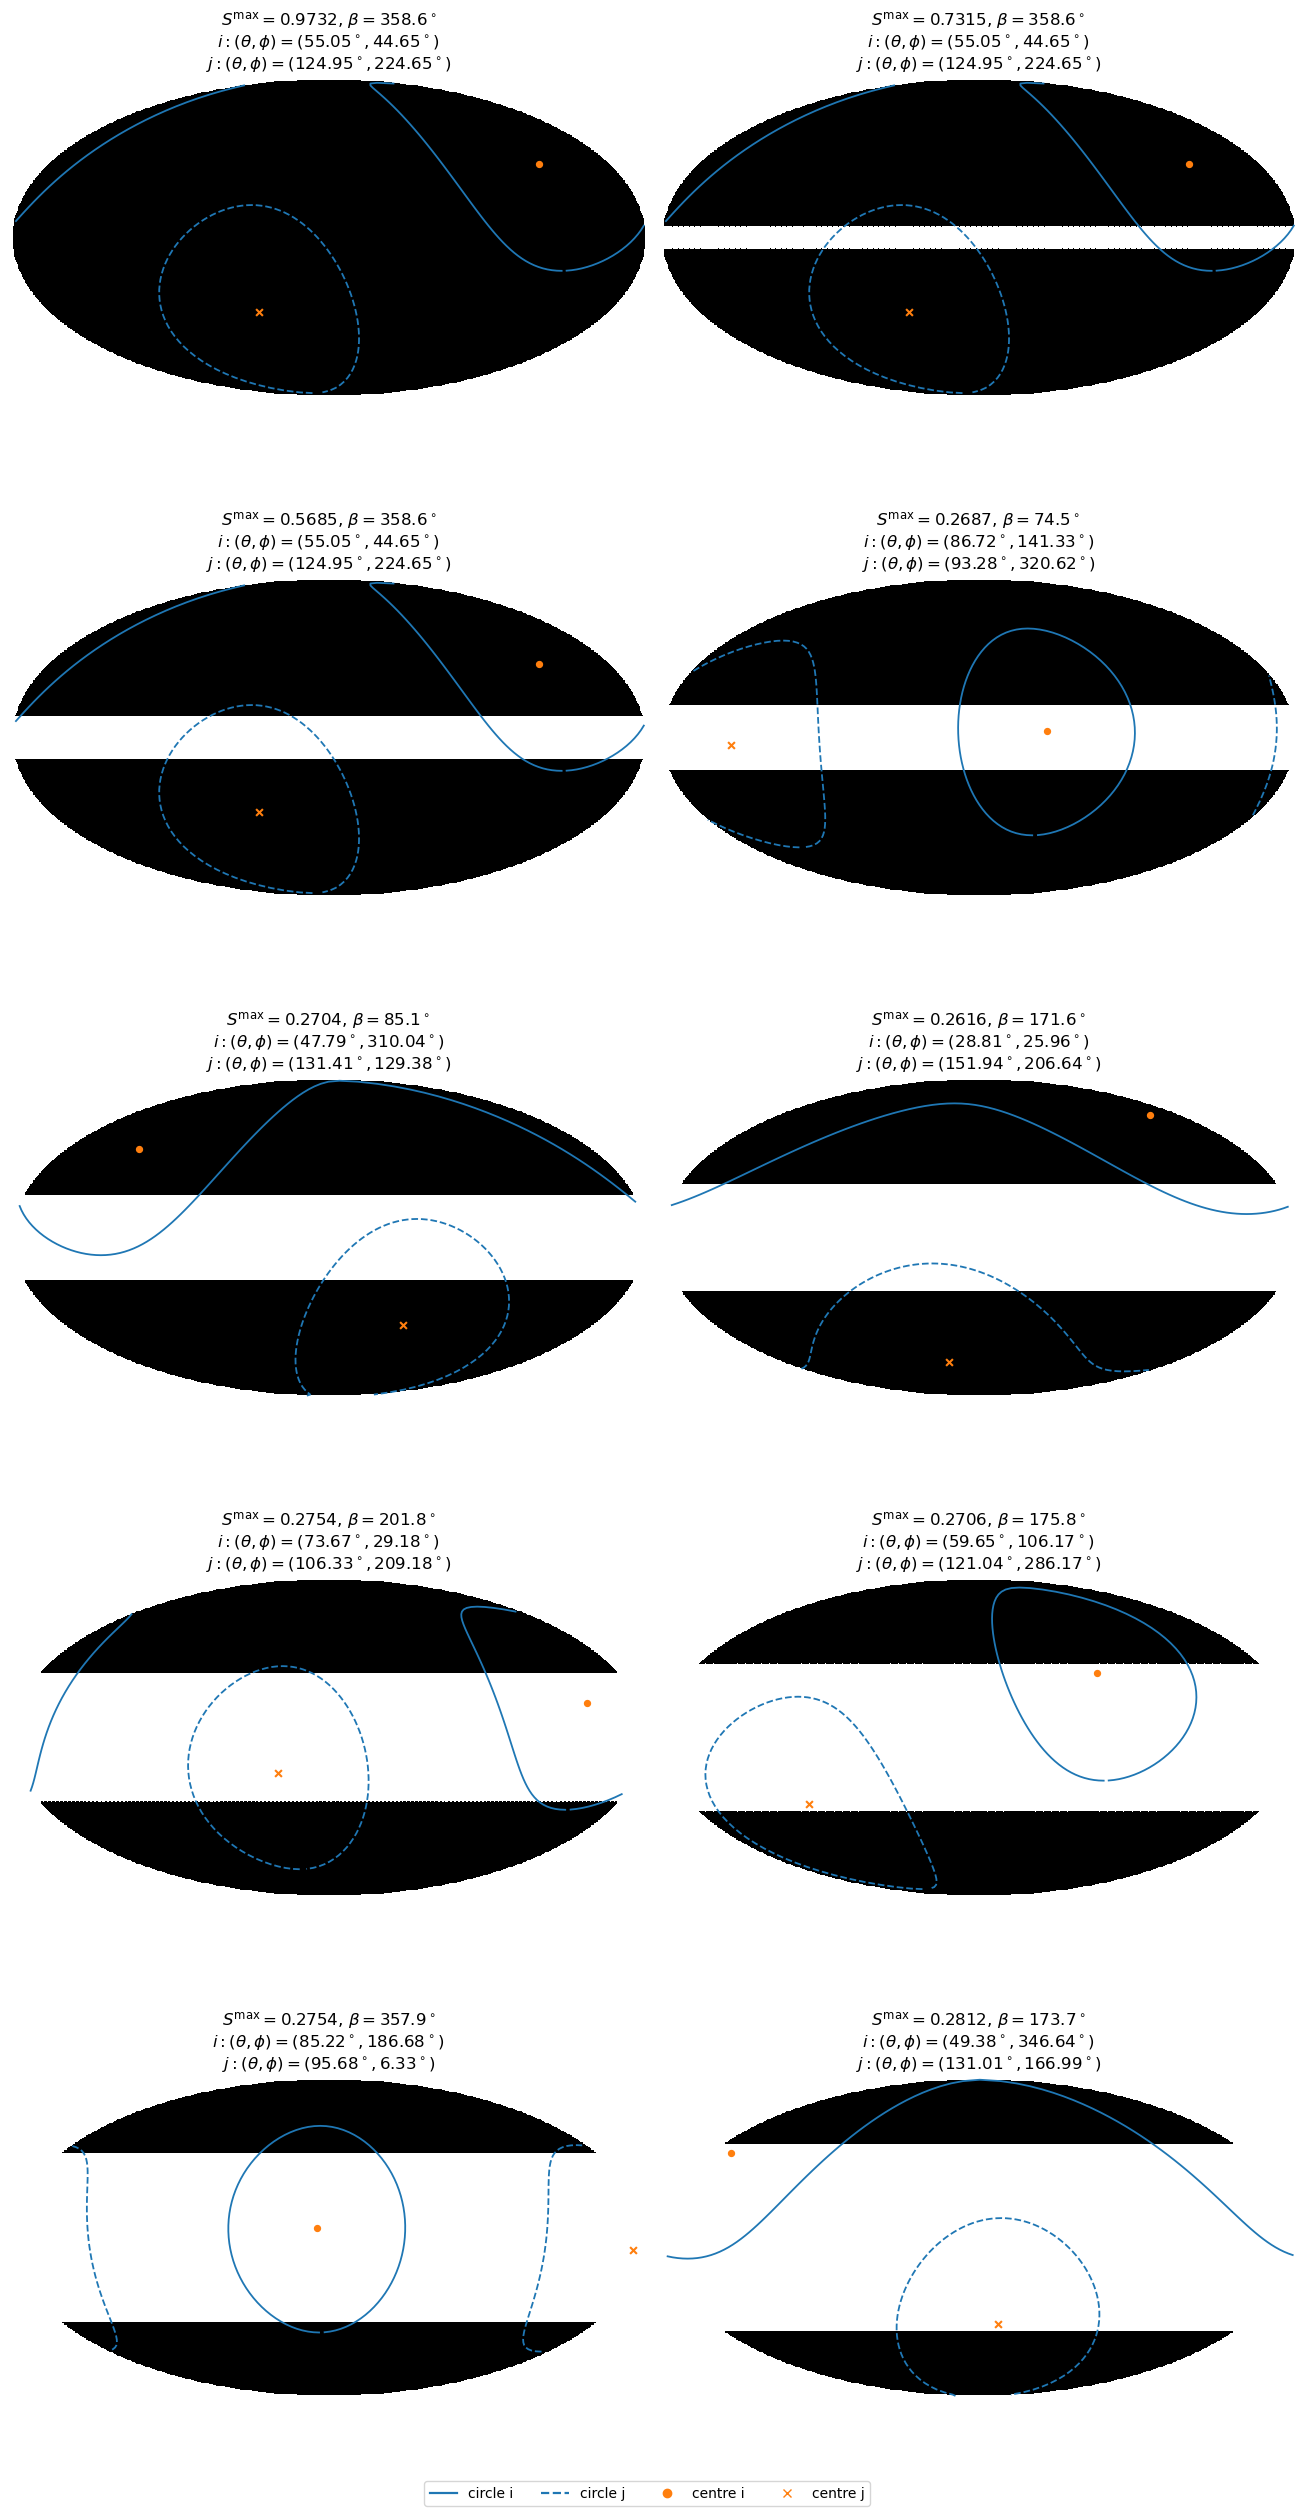

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj09_original_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj09_original_alpha50_pairs.png


################################################################################
Processing inj_00
################################################################################

inj_00


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.684773,510.000000,358.593750,15.027837,181.097561,164.972163,1.097561,180.000000,0.000000,0.000000
1,5,50.161562,0.684773,510.000000,358.593750,15.027837,181.097561,164.972163,1.097561,180.000000,0.000000,0.000000
2,10,50.161562,0.684773,510.000000,358.593750,15.027837,181.097561,164.972163,1.097561,180.000000,0.000000,0.000000
3,15,50.161562,0.684773,510.000000,358.593750,15.027837,181.097561,164.972163,1.097561,180.000000,0.000000,0.000000
4,20,50.161562,0.684773,510.000000,358.593750,15.027837,181.097561,164.972163,1.097561,180.000000,0.000000,0.000000
5,25,50.161562,0.640457,510.000000,358.593750,15.027837,181.097561,164.972163,1.097561,180.000000,0.105469,0.113281
6,30,50.161562,0.470963,510.000000,358.593750,15.396564,181.071429,165.340734,1.125000,179.262571,0.591797,0.593750
7,35,50.161562,0.272358,250.000000,175.781250,59.654817,106.171875,121.039240,286.171875,179.305943,0.855469,0.628906
8,40,50.161562,0.276636,278.000000,195.468750,62.046813,89.648438,118.291549,270.000000,179.541062,1.000000,0.714844
9,45,50.161562,0.286081,274.000000,192.656250,15.396564,311.785714,164.234548,135.000000,179.061286,1.000000,0.683594


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


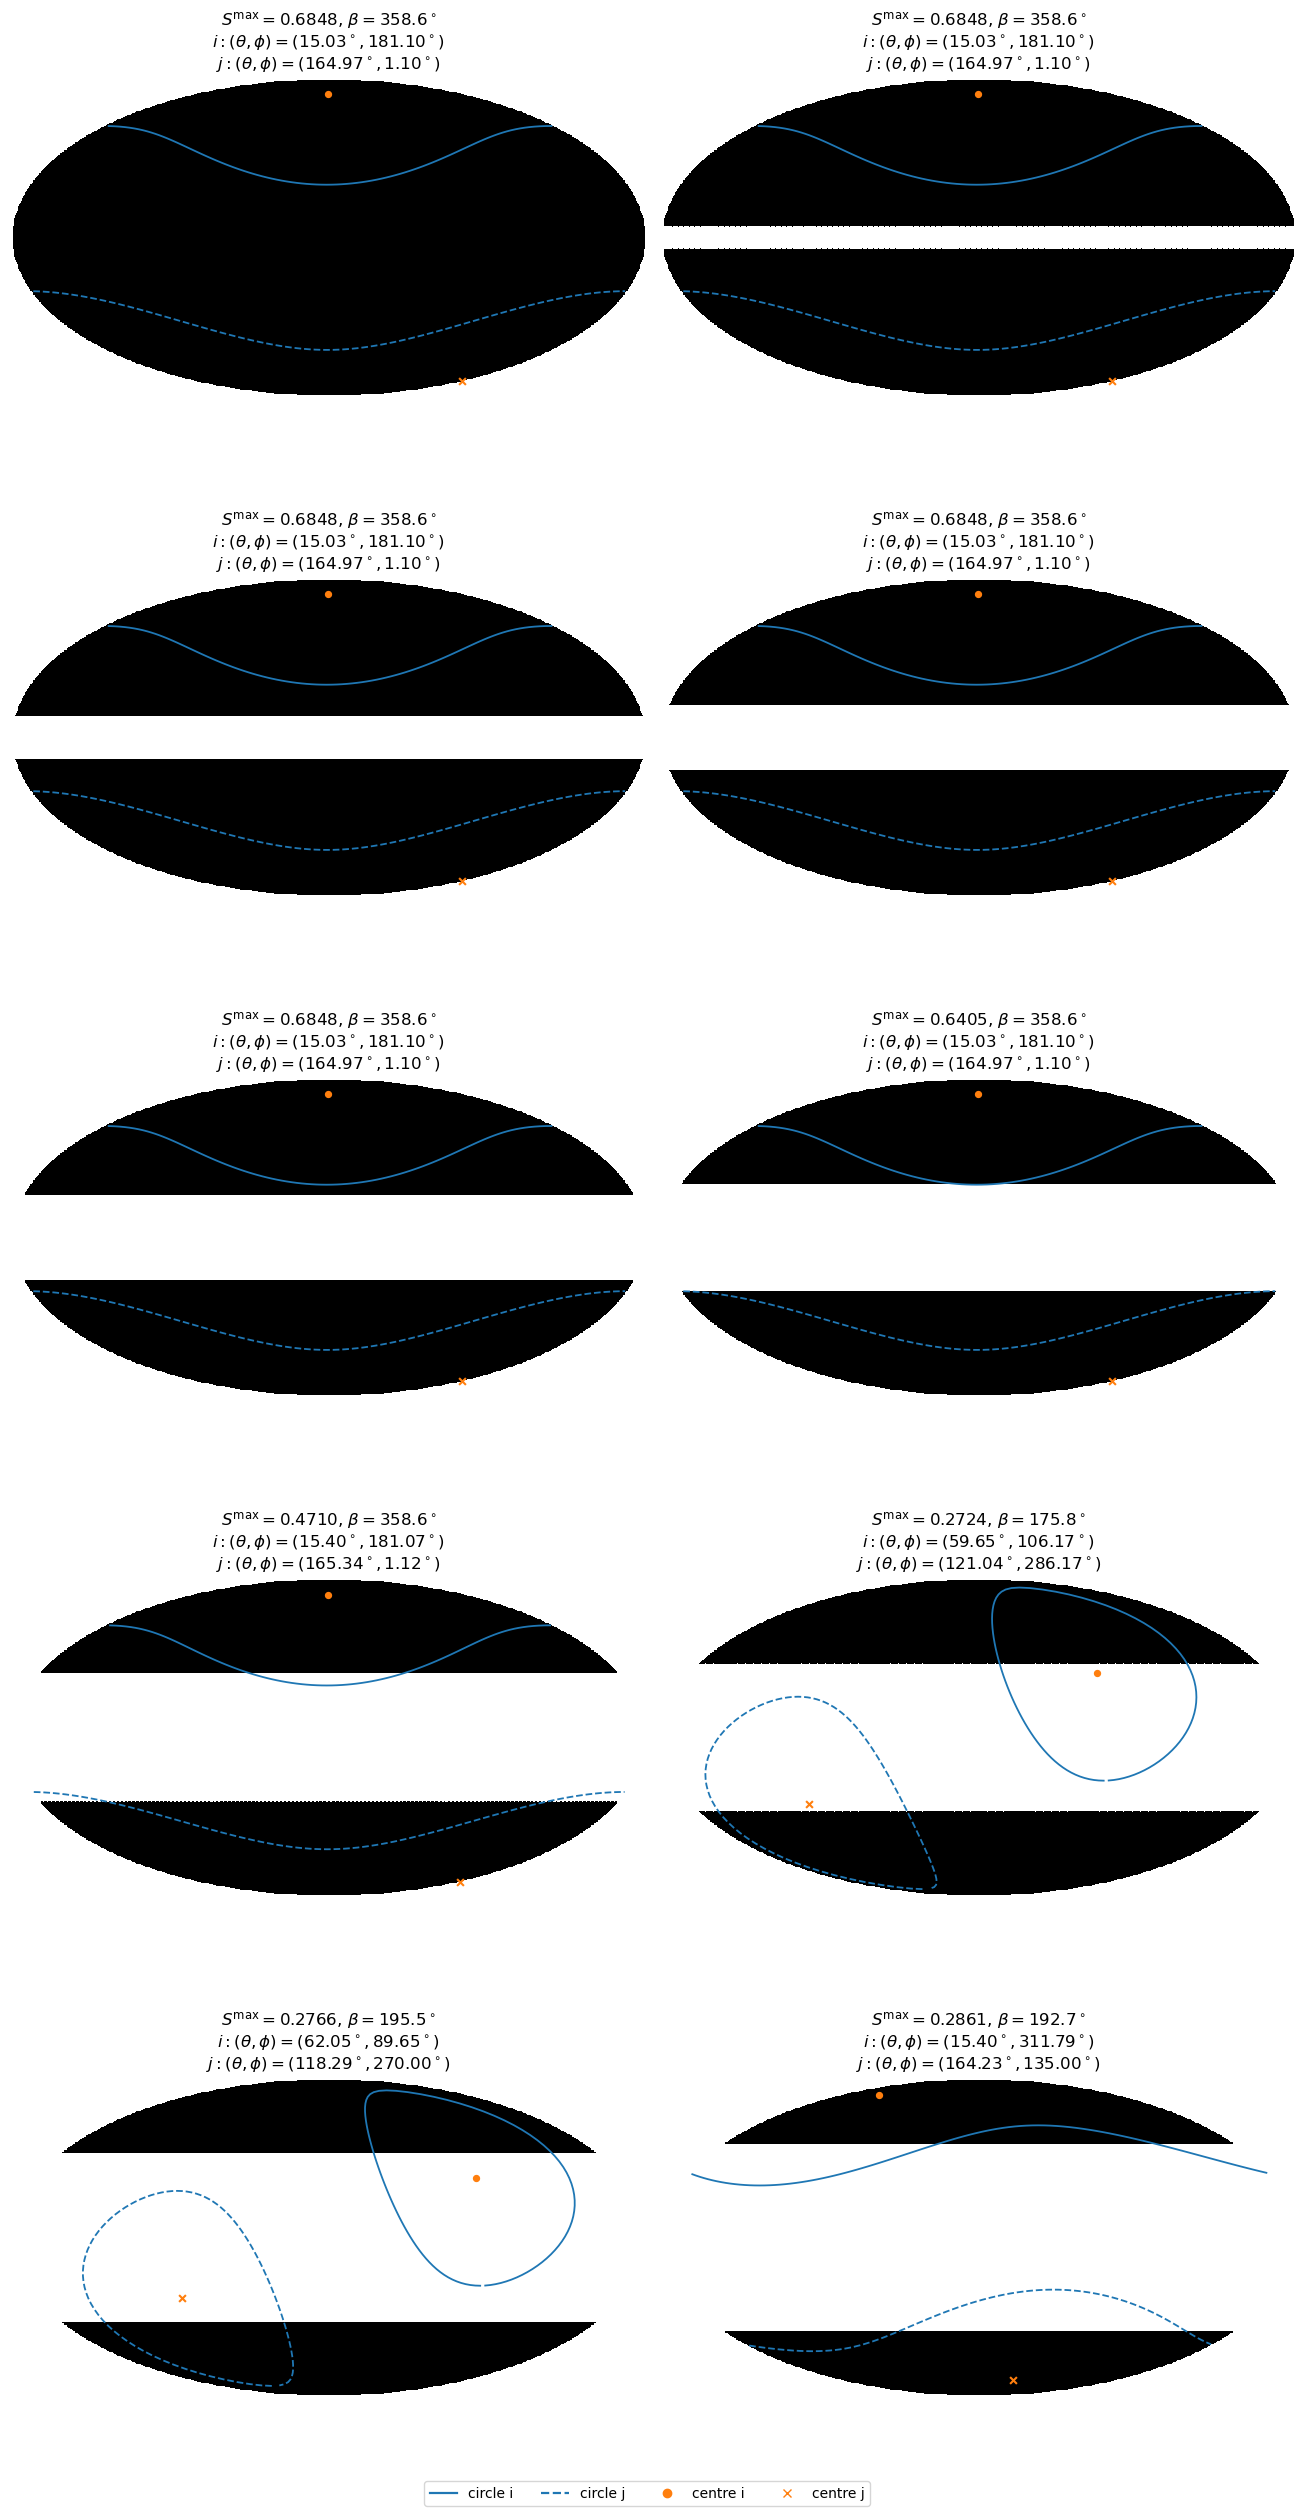

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_00_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_00_alpha50_pairs.png


################################################################################
Processing inj_01
################################################################################

inj_01


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.925183,510.000000,358.593750,19.834973,269.166667,160.165027,89.166667,180.000000,0.000000,0.000000
1,5,50.161562,0.925183,510.000000,358.593750,19.834973,269.166667,160.165027,89.166667,180.000000,0.000000,0.000000
2,10,50.161562,0.925183,510.000000,358.593750,19.834973,269.166667,160.165027,89.166667,180.000000,0.000000,0.000000
3,15,50.161562,0.925183,510.000000,358.593750,19.834973,269.166667,160.165027,89.166667,180.000000,0.000000,0.000000
4,20,50.161562,0.921619,510.000000,358.593750,19.834973,269.166667,160.165027,89.166667,180.000000,0.011719,0.007812
5,25,50.161562,0.554596,510.000000,358.593750,19.834973,269.166667,160.165027,89.166667,180.000000,0.511719,0.511719
6,30,50.161562,0.367764,510.000000,358.593750,19.834973,269.166667,160.165027,89.166667,180.000000,0.742188,0.742188
7,35,50.161562,0.276235,499.000000,350.859375,79.800082,130.429688,100.806923,311.132812,179.079997,0.929688,0.738281
8,40,50.161562,0.284955,509.000000,357.890625,85.219808,186.679688,95.679190,6.328125,179.035239,1.000000,0.738281
9,45,50.161562,0.281089,509.000000,357.890625,88.507754,202.500000,90.895283,21.796875,179.077758,1.000000,0.777344


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


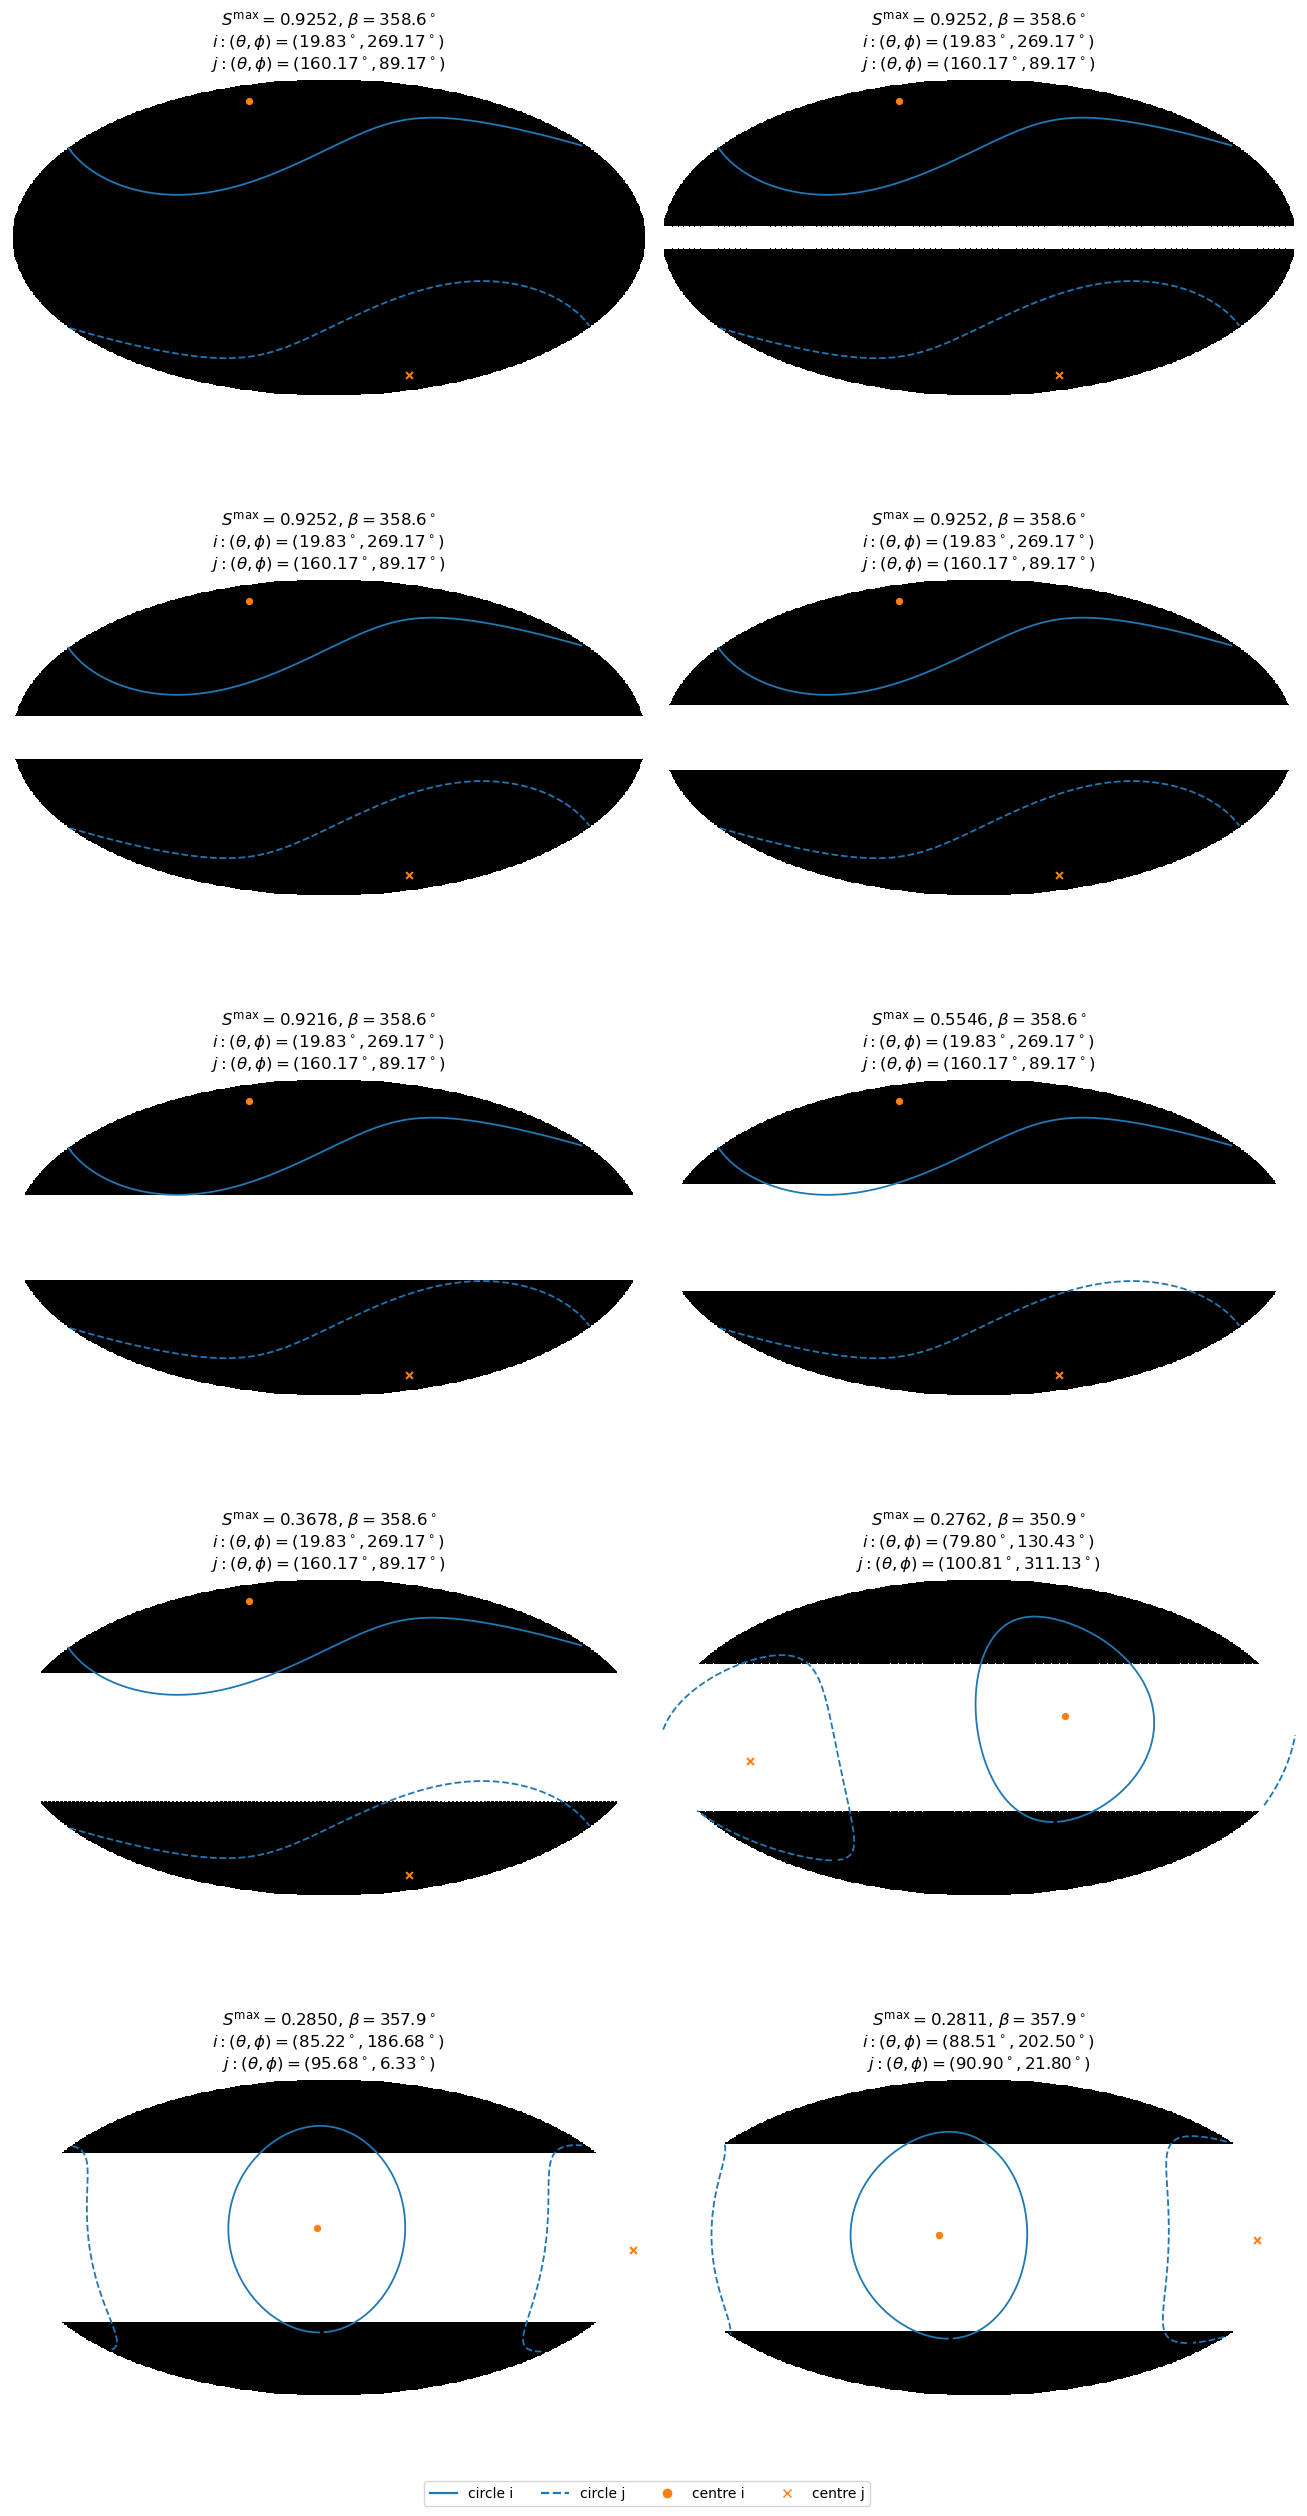

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_01_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_01_alpha50_pairs.png


################################################################################
Processing inj_02
################################################################################

inj_02


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.962968,510.000000,358.593750,29.943721,359.444444,150.056279,179.444444,180.000000,0.000000,0.000000
1,5,50.161562,0.962968,510.000000,358.593750,29.943721,359.444444,150.056279,179.444444,180.000000,0.000000,0.000000
2,10,50.161562,0.943214,510.000000,358.593750,29.943721,359.444444,150.056279,179.444444,180.000000,0.070312,0.070312
3,15,50.161562,0.546179,510.000000,358.593750,29.943721,359.444444,150.056279,179.444444,180.000000,0.437500,0.437500
4,20,50.161562,0.361502,510.000000,358.593750,29.943721,359.444444,150.056279,179.444444,180.000000,0.621094,0.621094
5,25,50.161562,0.257026,323.000000,227.109375,49.379815,158.906250,130.228185,339.257812,179.525352,0.777344,0.638672
6,30,50.161562,0.274845,287.000000,201.796875,73.665177,29.179688,106.334823,209.179688,180.000000,0.910156,0.644531
7,35,50.161562,0.270596,98.000000,68.906250,51.699078,129.375000,127.544325,310.078125,179.061881,1.000000,0.900391
8,40,50.161562,0.274542,509.000000,357.890625,85.219808,186.679688,95.679190,6.328125,179.035239,1.000000,0.738281
9,45,50.161562,0.287755,262.000000,184.218750,81.010701,307.617188,98.084014,127.968750,179.030252,1.000000,0.814453


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


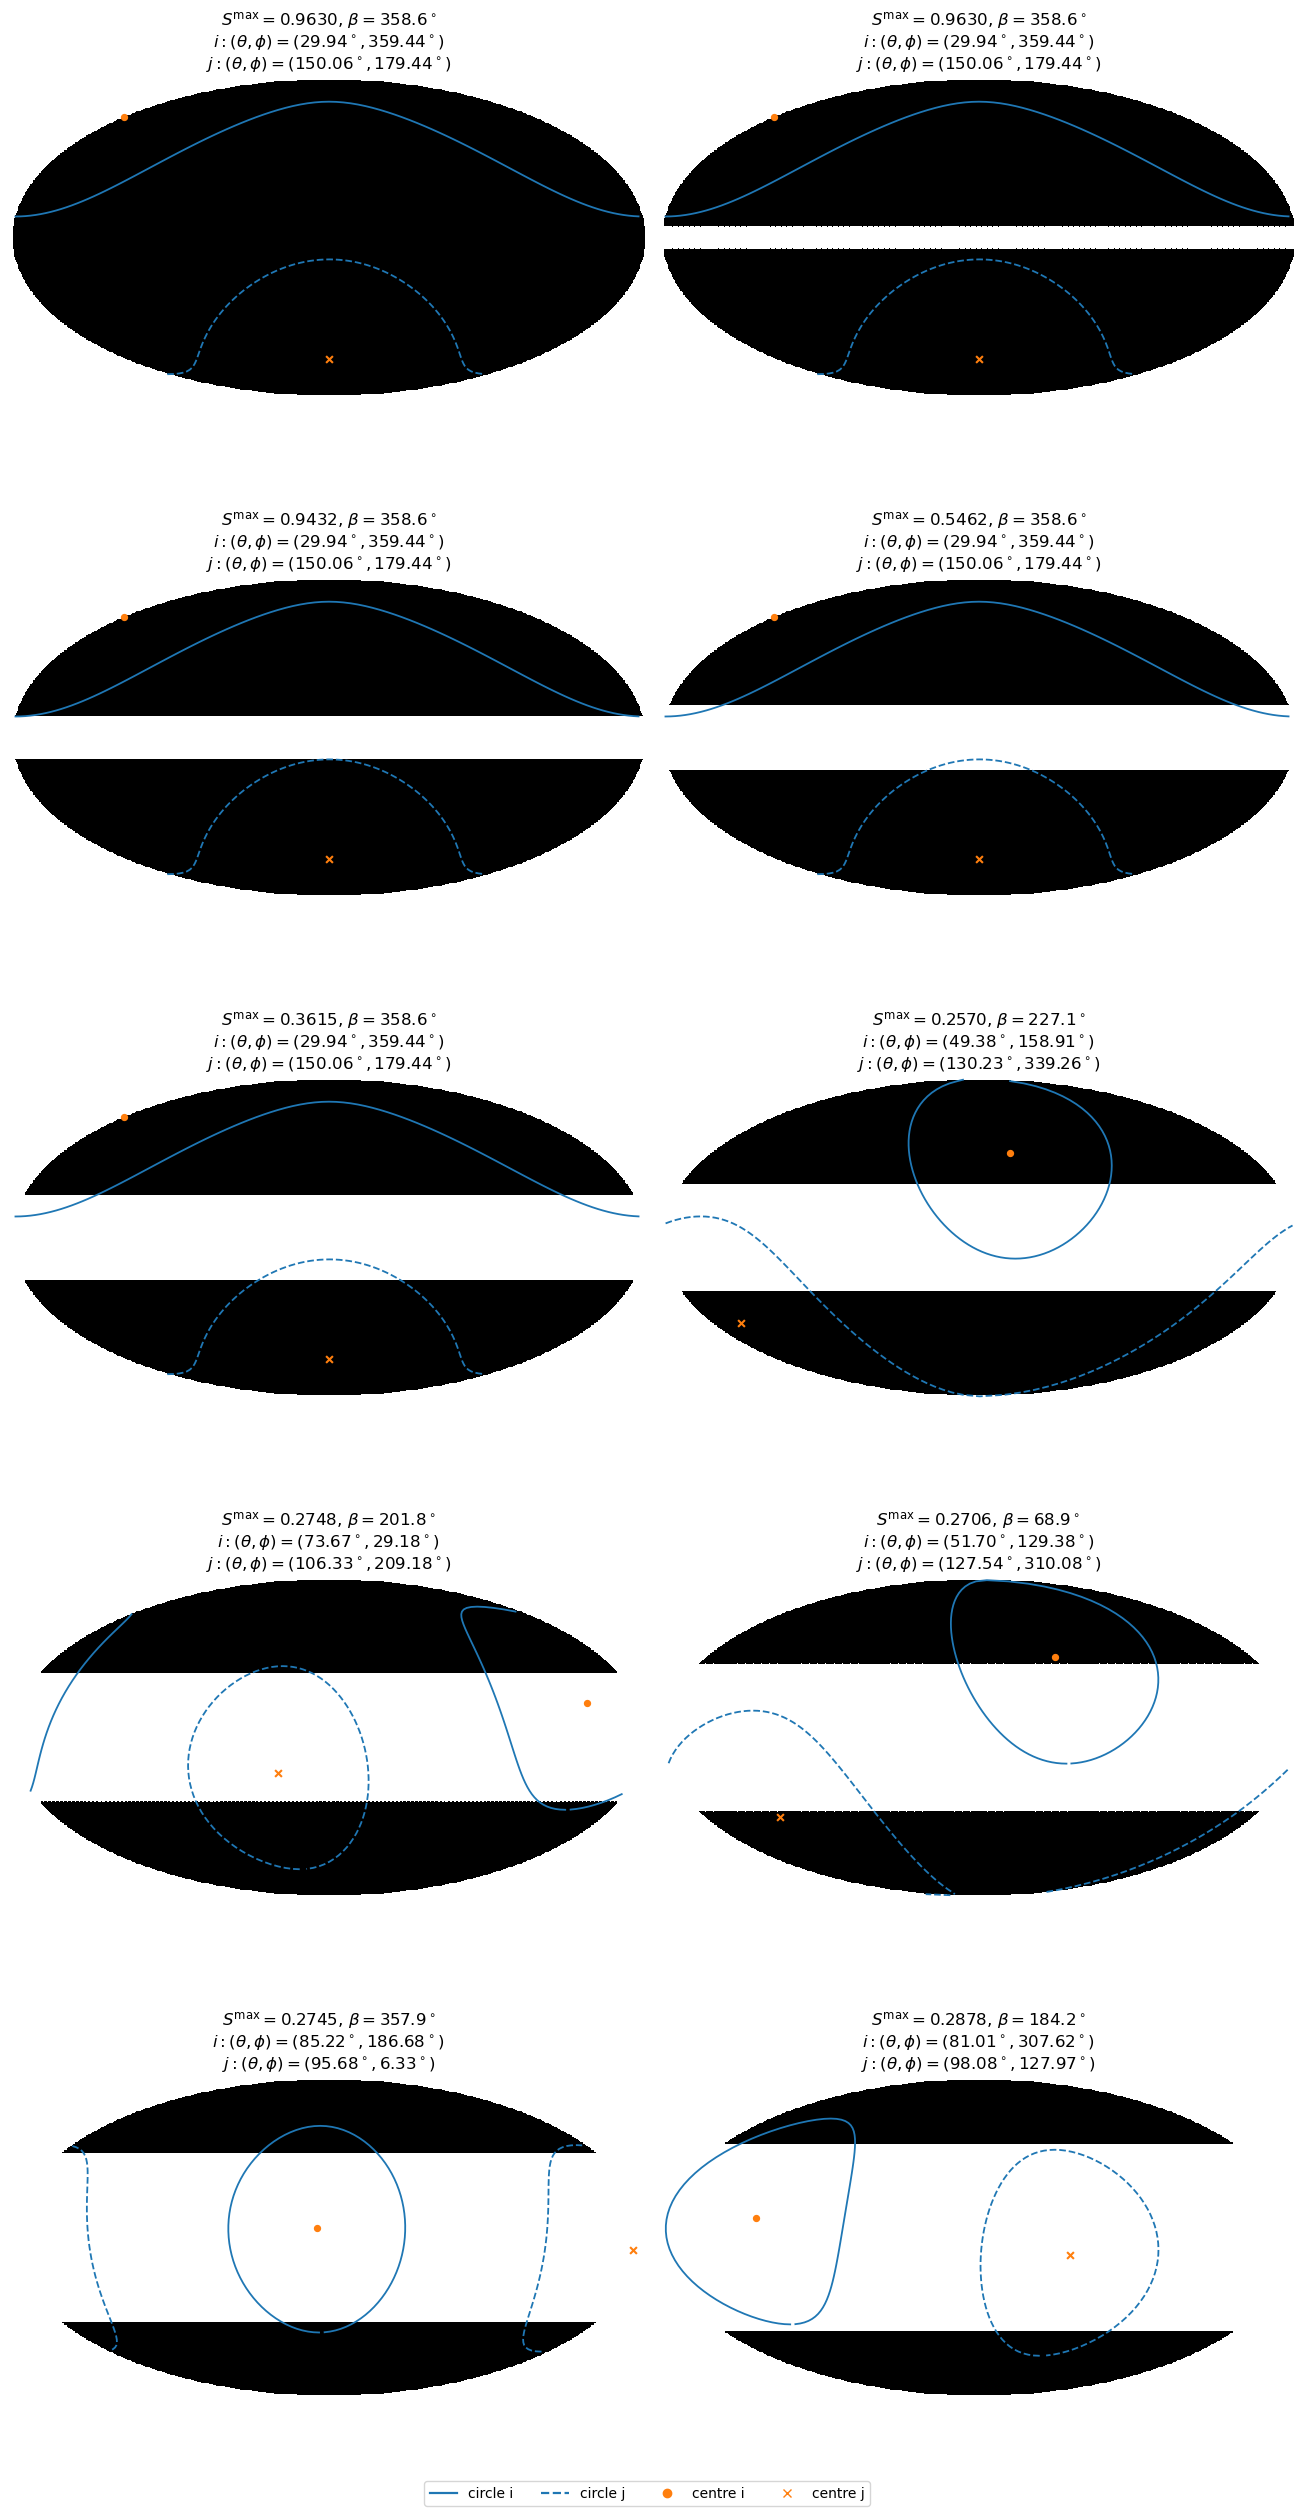

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_02_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_02_alpha50_pairs.png


################################################################################
Processing inj_03
################################################################################

inj_03


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.970010,510.000000,358.593750,39.908543,89.579439,140.091457,269.579439,180.000000,0.000000,0.000000
1,5,50.161562,0.615045,510.000000,358.593750,39.908543,89.579439,140.091457,269.579439,180.000000,0.386719,0.386719
2,10,50.161562,0.536343,510.000000,358.593750,39.908543,89.579439,140.091457,269.579439,180.000000,0.554688,0.554688
3,15,50.161562,0.288100,510.000000,358.593750,39.908543,89.579439,140.091457,269.579439,180.000000,0.683594,0.683594
4,20,50.161562,0.269150,121.000000,85.078125,47.789630,310.039370,131.411189,129.375000,179.059847,0.800781,0.712891
5,25,50.161562,0.259142,393.000000,276.328125,43.821820,85.000000,136.964977,264.130435,179.011888,0.910156,0.744141
6,30,50.161562,0.274791,287.000000,201.796875,73.665177,29.179688,106.334823,209.179688,180.000000,1.000000,0.644531
7,35,50.161562,0.275455,250.000000,175.781250,59.654817,106.171875,121.039240,286.171875,179.305943,1.000000,0.628906
8,40,50.161562,0.272474,278.000000,195.468750,62.046813,89.648438,118.291549,270.000000,179.541062,1.000000,0.714844
9,45,50.161562,0.289121,245.000000,172.265625,73.353960,59.765625,106.957763,239.414062,179.541263,1.000000,0.769531


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


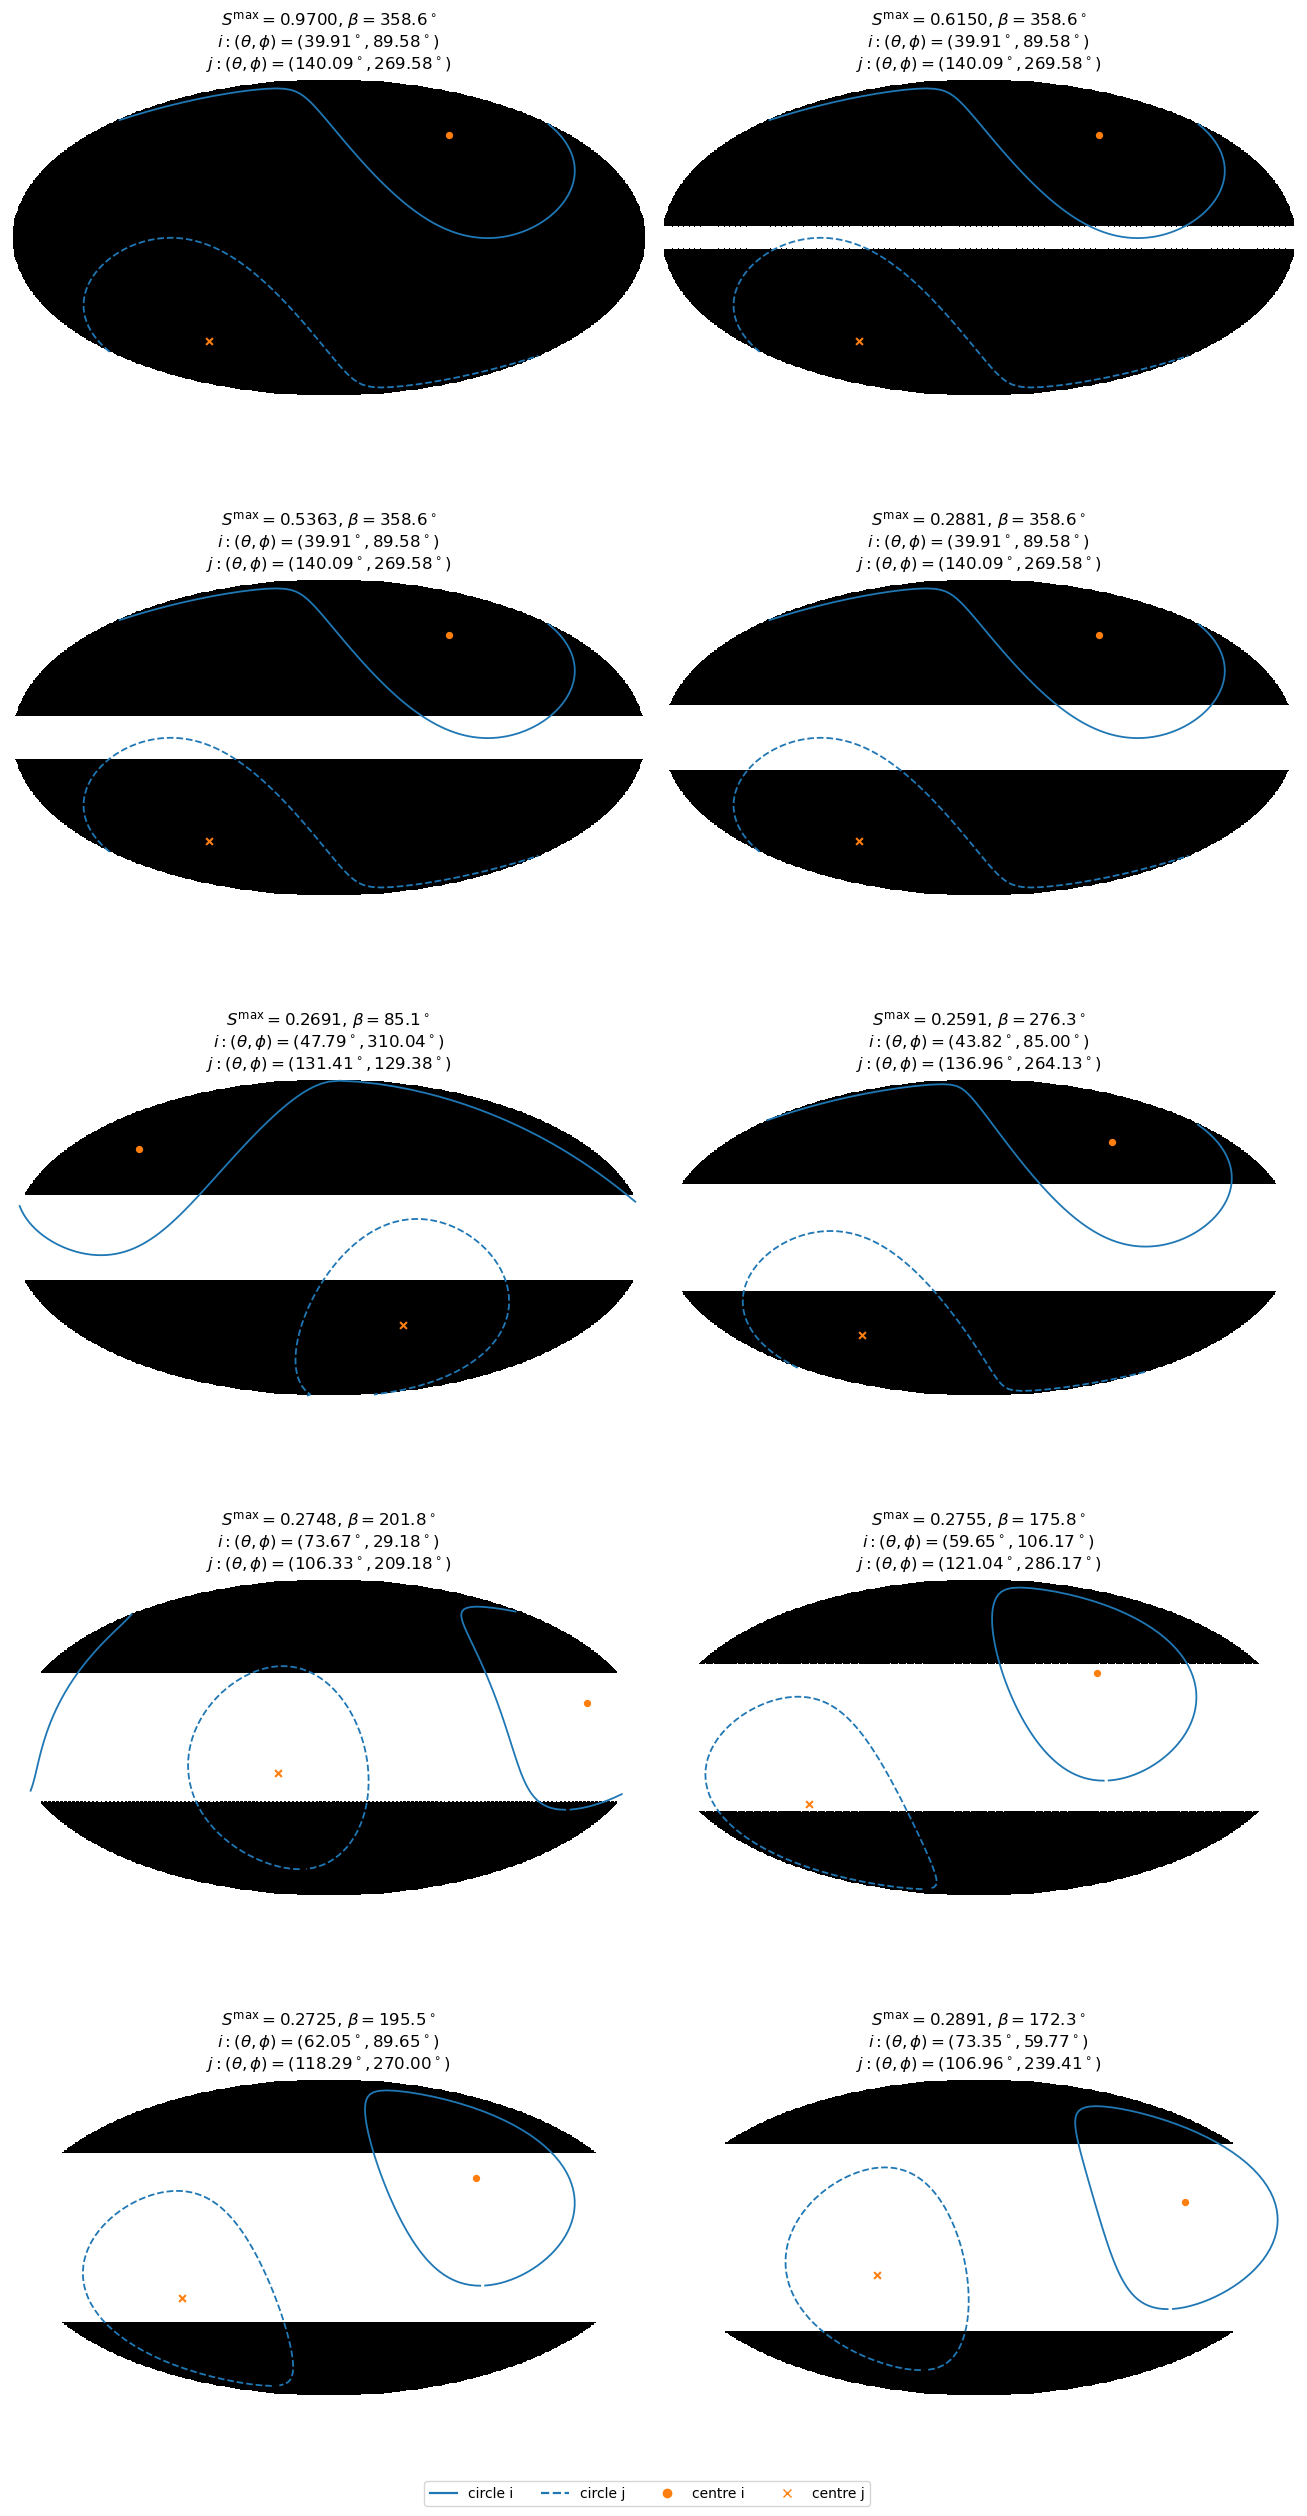

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_03_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_03_alpha50_pairs.png


################################################################################
Processing inj_04
################################################################################

inj_04


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.973983,510.000000,358.593750,50.161560,225.000000,129.838440,45.000000,nan,0.000000,0.000000
1,5,50.161562,0.710741,510.000000,358.593750,50.161560,225.000000,129.838440,45.000000,nan,0.265625,0.265625
2,10,50.161562,0.315985,510.000000,358.593750,50.161560,225.000000,129.838440,45.000000,nan,0.648438,0.648438
3,15,50.161562,0.266000,106.000000,74.531250,86.715631,141.328125,93.284369,320.625000,179.298030,0.832031,0.437500
4,20,50.161562,0.279630,121.000000,85.078125,47.789630,310.039370,131.411189,129.375000,179.059847,0.925781,0.712891
5,25,50.161562,0.263992,261.000000,183.515625,53.576426,109.335938,125.685335,290.039063,179.068273,1.000000,0.537109
6,30,50.161562,0.274270,287.000000,201.796875,73.665177,29.179688,106.334823,209.179688,180.000000,1.000000,0.644531
7,35,50.161562,0.274291,250.000000,175.781250,59.654817,106.171875,121.039240,286.171875,179.305943,1.000000,0.628906
8,40,50.161562,0.275439,509.000000,357.890625,85.219808,186.679688,95.679190,6.328125,179.035239,1.000000,0.738281
9,45,50.161562,0.289915,256.000000,180.000000,48.985500,215.507812,131.810315,36.210938,179.045341,1.000000,0.667969


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


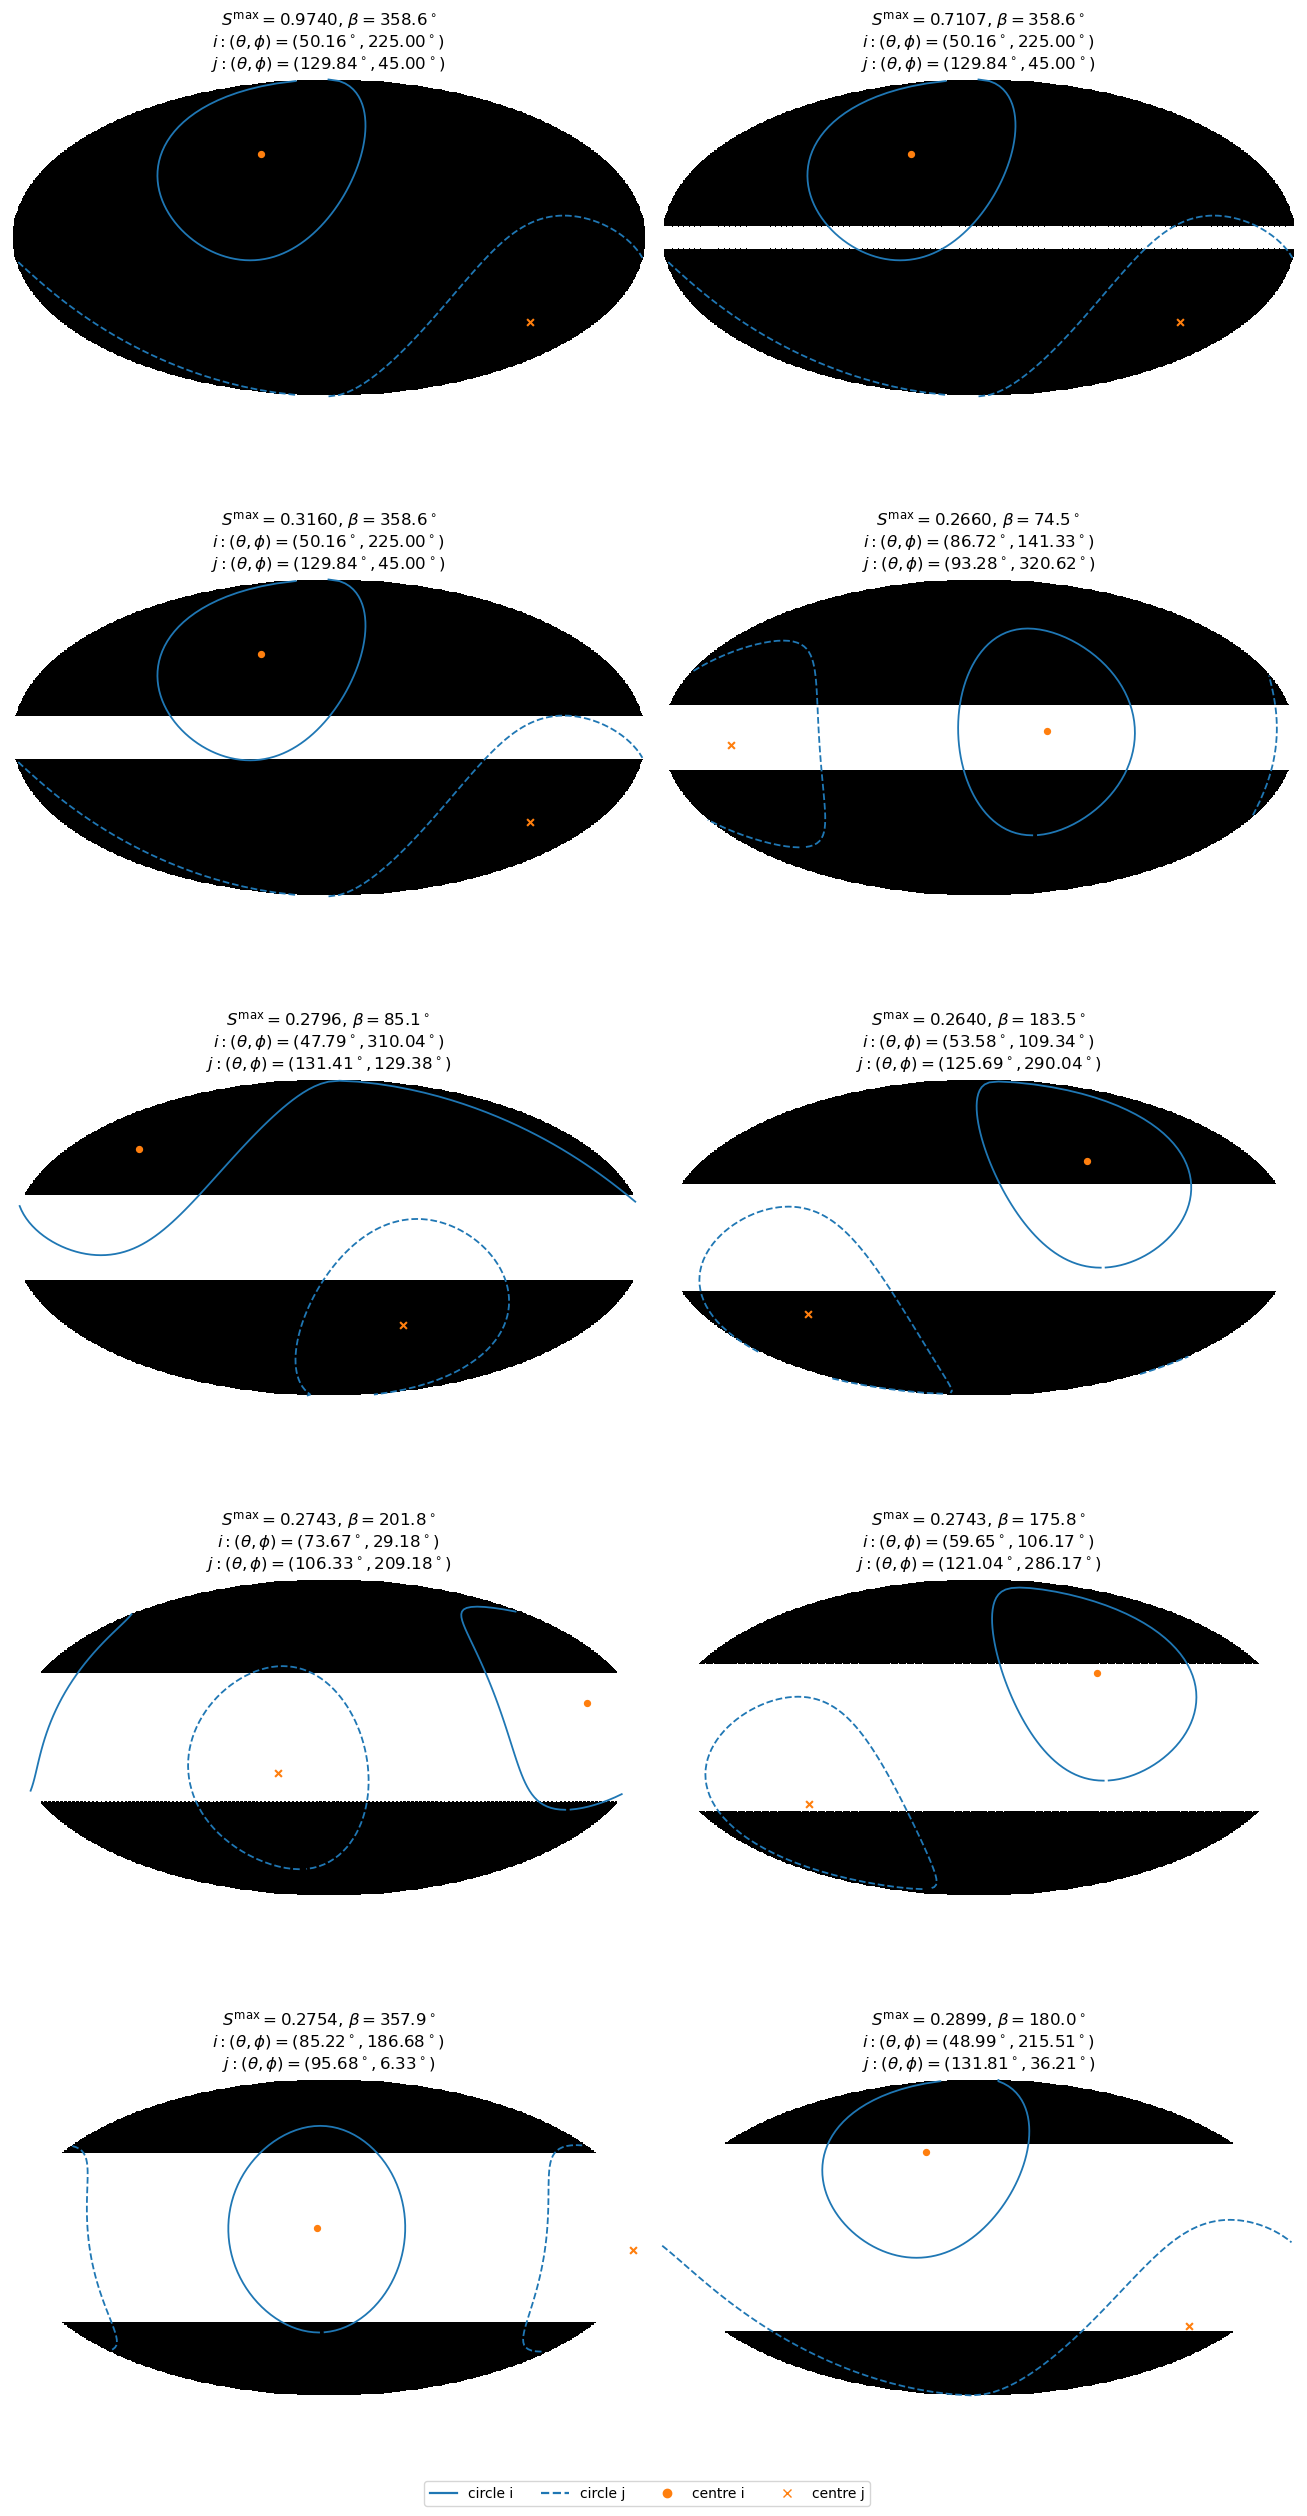

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_04_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_04_alpha50_pairs.png


################################################################################
Processing inj_05
################################################################################

inj_05


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.970752,510.000000,358.593750,60.000000,314.648438,120.000000,134.648437,180.000000,0.000000,0.000000
1,5,50.161562,0.806668,510.000000,358.593750,60.000000,314.648438,120.000000,134.648437,180.000000,0.187500,0.187500
2,10,50.161562,0.624108,510.000000,358.593750,60.000000,314.648438,120.000000,134.648437,180.000000,0.390625,0.390625
3,15,50.161562,0.433614,510.000000,358.593750,60.000000,314.648438,120.000000,134.648437,180.000000,0.617188,0.617188
4,20,50.161562,0.272434,121.000000,85.078125,47.789630,310.039370,131.411189,129.375000,179.059847,0.941406,0.712891
5,25,50.161562,0.262739,244.000000,171.562500,28.810224,25.961538,151.943837,206.644737,179.178778,1.000000,0.394531
6,30,50.161562,0.277003,287.000000,201.796875,73.665177,29.179688,106.334823,209.179688,180.000000,1.000000,0.644531
7,35,50.161562,0.274241,189.000000,132.890625,22.437555,204.344262,157.934929,24.750000,179.597076,1.000000,0.605469
8,40,50.161562,0.276559,509.000000,357.890625,85.219808,186.679688,95.679190,6.328125,179.035239,1.000000,0.738281
9,45,50.161562,0.286721,245.000000,172.265625,73.353960,59.765625,106.957763,239.414062,179.541263,1.000000,0.769531


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


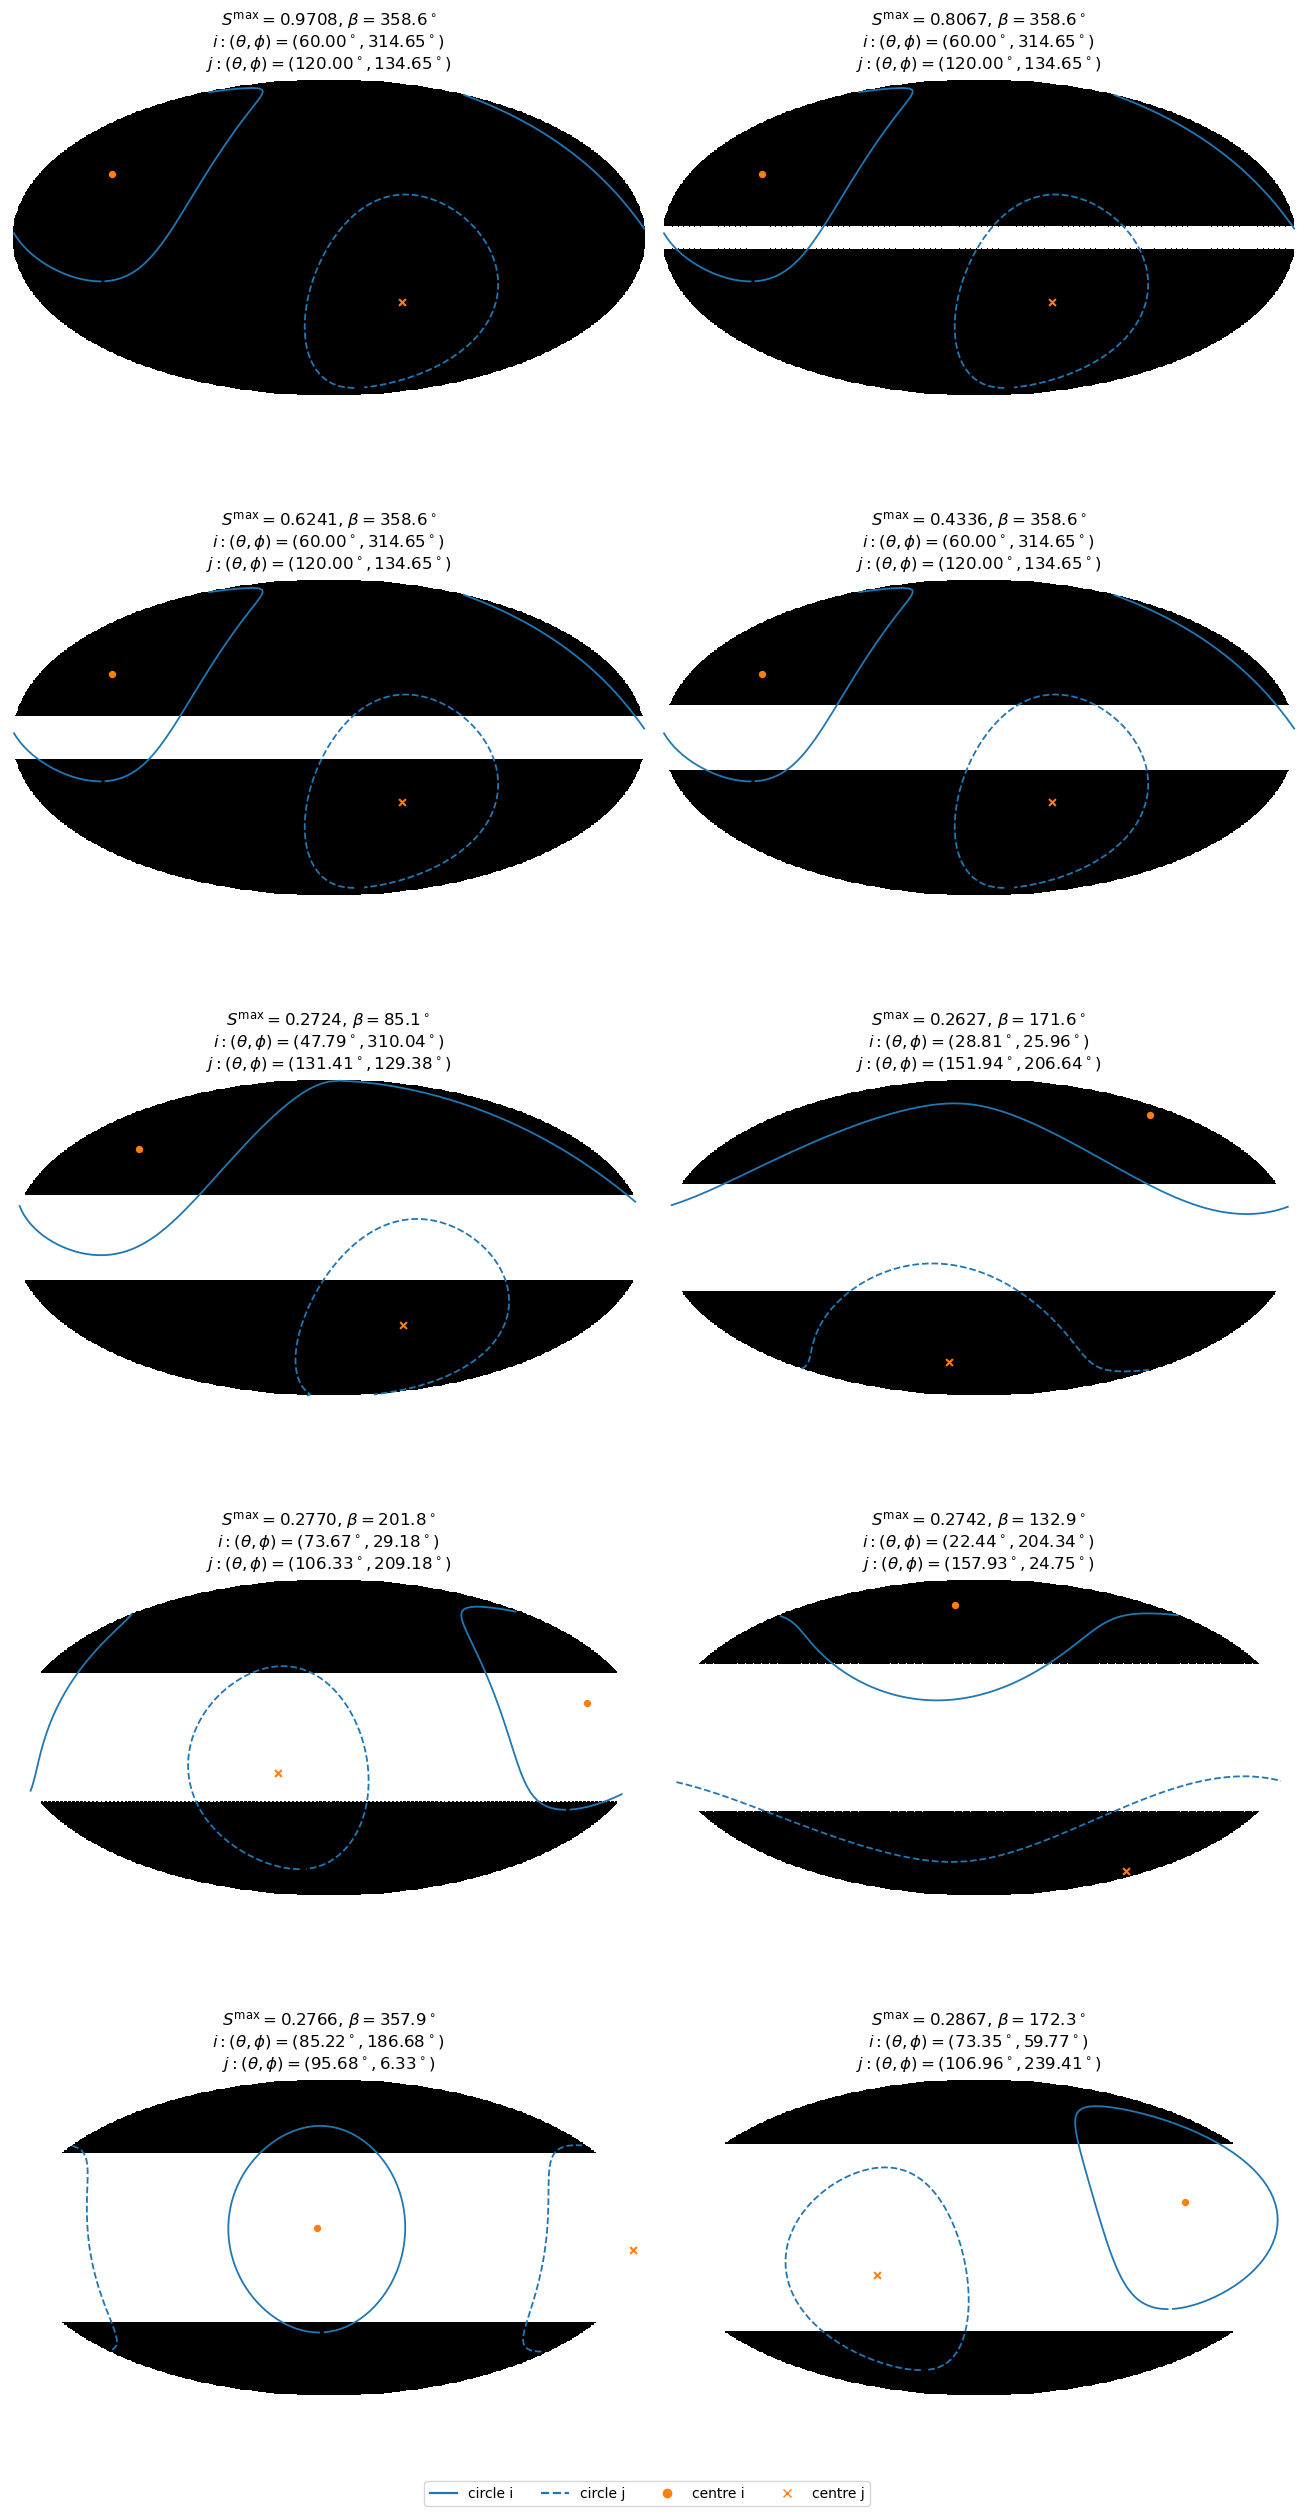

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_05_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_05_alpha50_pairs.png


################################################################################
Processing inj_06
################################################################################

inj_06


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.977997,510.000000,358.593750,70.211951,45.000000,109.788049,225.000000,180.000000,0.000000,0.000000
1,5,50.161562,0.832222,510.000000,358.593750,70.211951,45.000000,109.788049,225.000000,180.000000,0.164062,0.164062
2,10,50.161562,0.699472,510.000000,358.593750,70.211951,45.000000,109.788049,225.000000,180.000000,0.328125,0.328125
3,15,50.161562,0.497985,510.000000,358.593750,70.211951,45.000000,109.788049,225.000000,180.000000,0.457031,0.457031
4,20,50.161562,0.454750,510.000000,358.593750,70.211951,45.000000,109.788049,225.000000,180.000000,0.566406,0.566406
5,25,50.161562,0.354013,510.000000,358.593750,70.211951,45.000000,109.788049,225.000000,180.000000,0.691406,0.691406
6,30,50.161562,0.271690,287.000000,201.796875,73.665177,29.179688,106.334823,209.179688,180.000000,0.921875,0.644531
7,35,50.161562,0.273020,250.000000,175.781250,59.654817,106.171875,121.039240,286.171875,179.305943,1.000000,0.628906
8,40,50.161562,0.285474,250.000000,175.781250,74.595906,57.656250,106.024100,238.359375,179.082110,1.000000,0.726562
9,45,50.161562,0.292278,269.000000,189.140625,63.389902,84.023437,117.279613,264.726562,179.082877,1.000000,0.738281


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


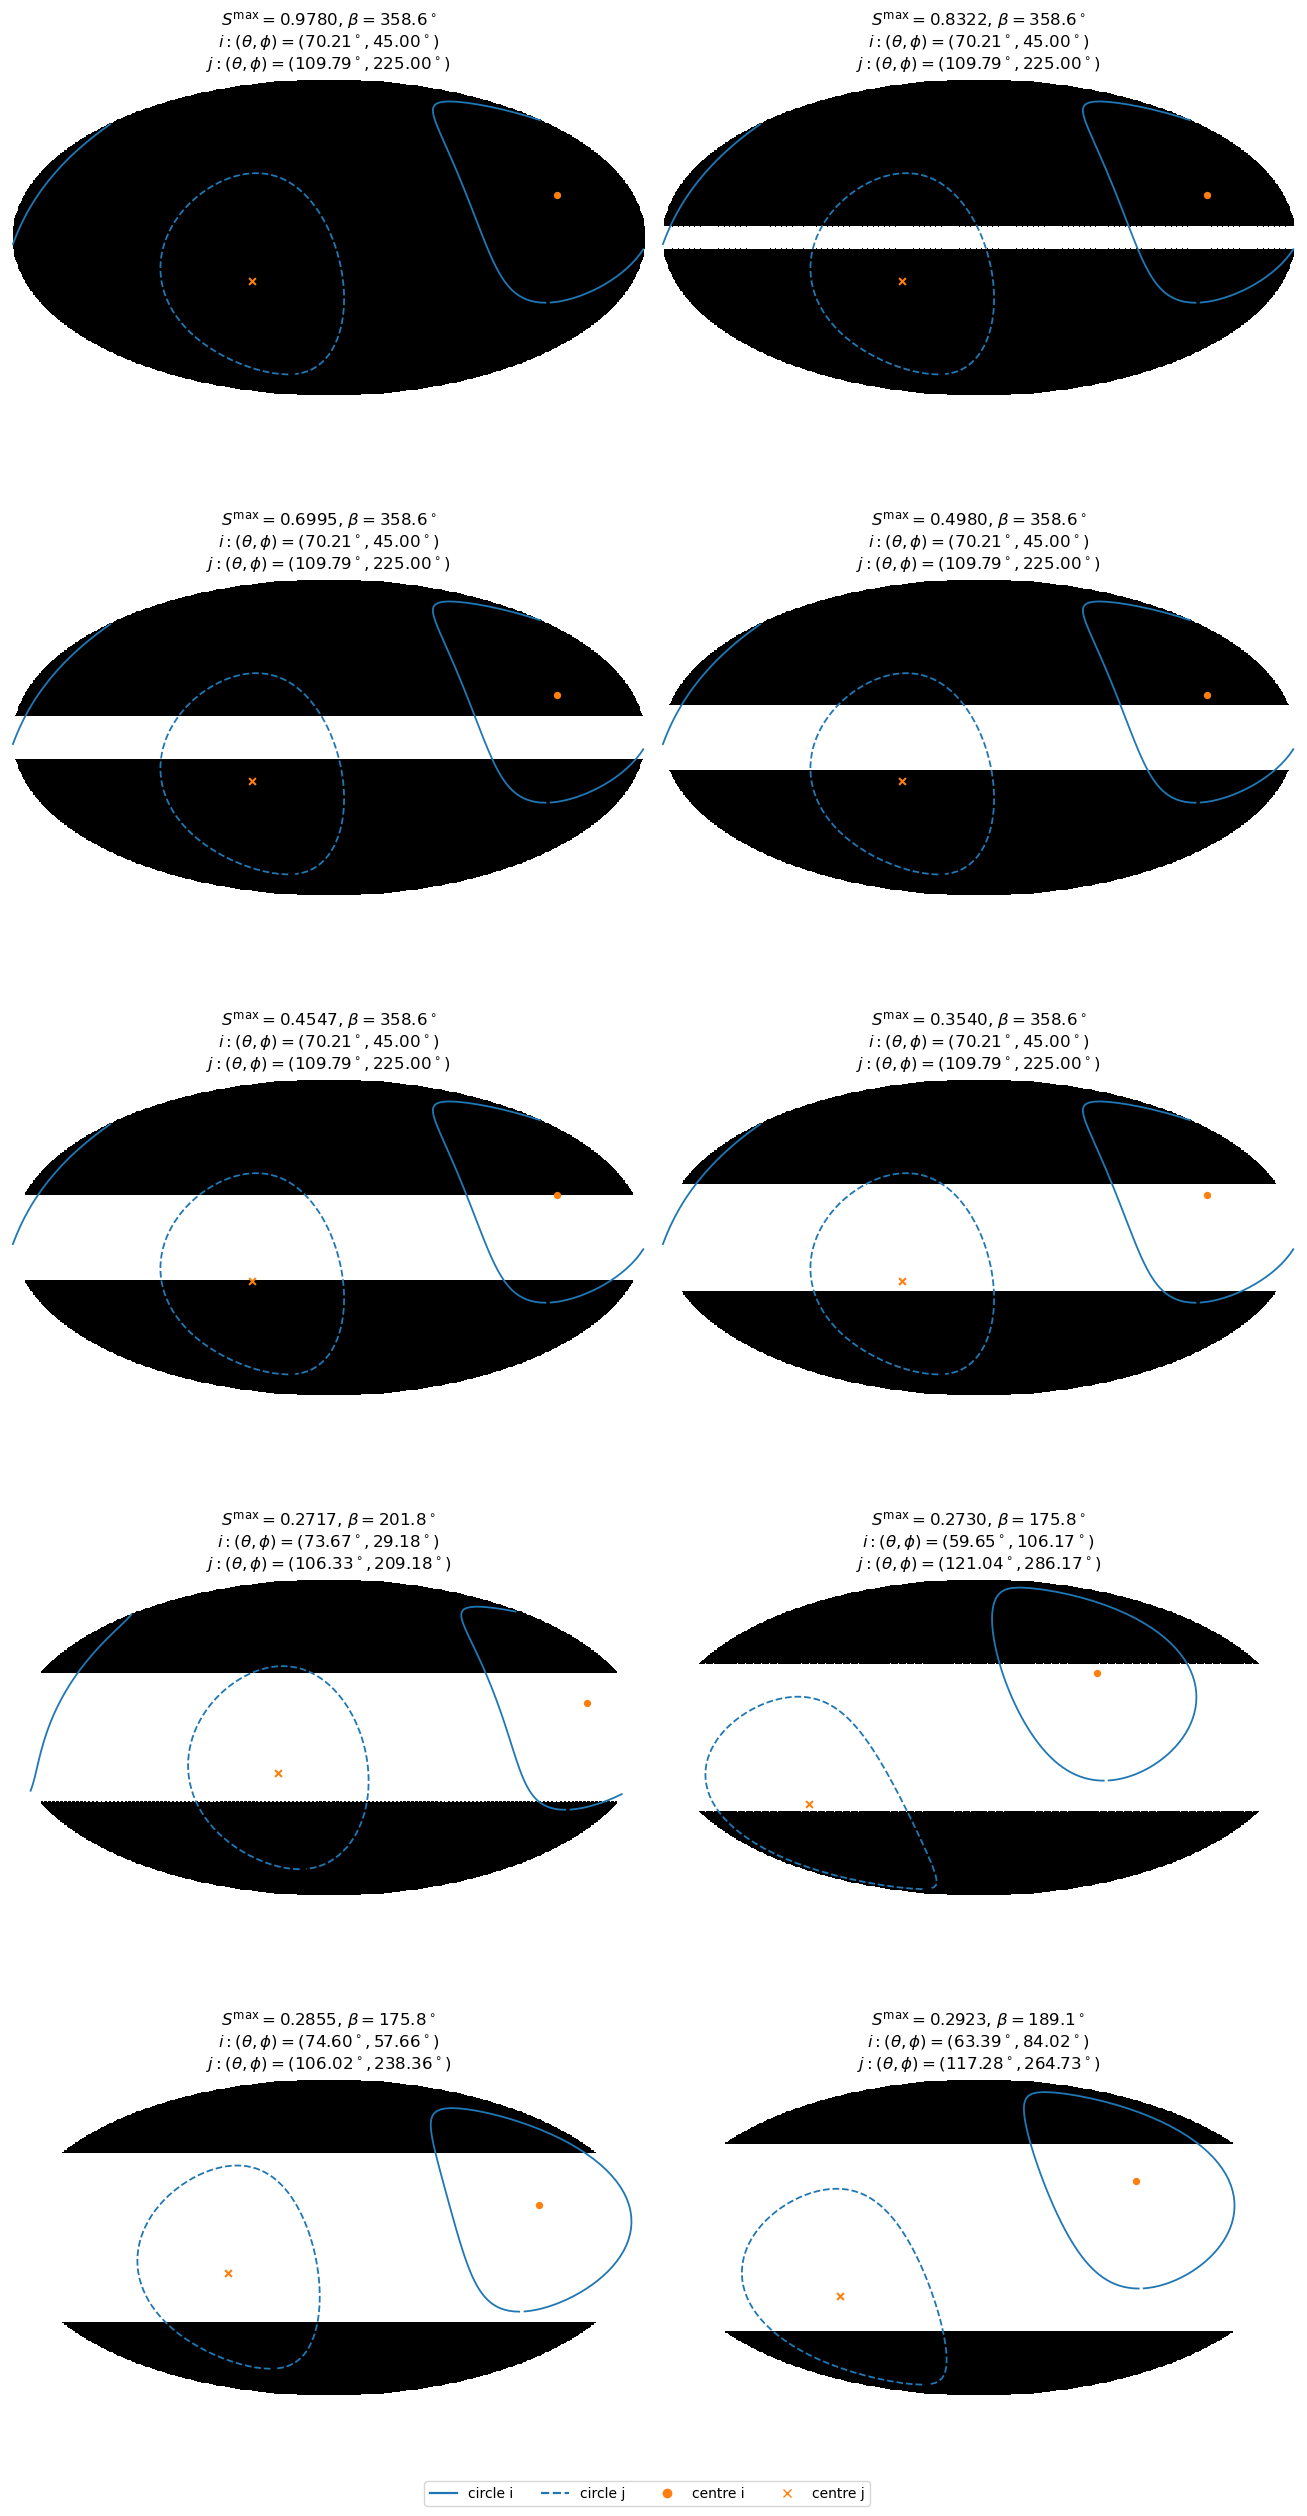

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_06_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_06_alpha50_pairs.png


################################################################################
Processing inj_07
################################################################################

inj_07


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.971113,510.000000,358.593750,80.103147,135.000000,99.896853,315.000000,180.000000,0.000000,0.000000
1,5,50.161562,0.828663,510.000000,358.593750,80.103147,135.000000,99.896853,315.000000,180.000000,0.148438,0.148438
2,10,50.161562,0.751587,510.000000,358.593750,80.103147,135.000000,99.896853,315.000000,180.000000,0.246094,0.246094
3,15,50.161562,0.665609,510.000000,358.593750,80.103147,135.000000,99.896853,315.000000,180.000000,0.324219,0.324219
4,20,50.161562,0.675613,510.000000,358.593750,80.103147,135.000000,99.896853,315.000000,180.000000,0.410156,0.410156
5,25,50.161562,0.596616,510.000000,358.593750,80.103147,135.000000,99.896853,315.000000,180.000000,0.496094,0.496094
6,30,50.161562,0.513102,510.000000,358.593750,80.103147,135.000000,99.896853,315.000000,180.000000,0.597656,0.597656
7,35,50.161562,0.436593,510.000000,358.593750,80.103147,135.000000,99.896853,315.000000,180.000000,0.722656,0.722656
8,40,50.161562,0.281272,5.000000,3.515625,88.209215,256.289062,90.895283,75.937500,179.037997,0.941406,0.658203
9,45,50.161562,0.281028,247.000000,173.671875,49.379815,346.640625,131.014500,166.992188,179.524320,1.000000,0.679688


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


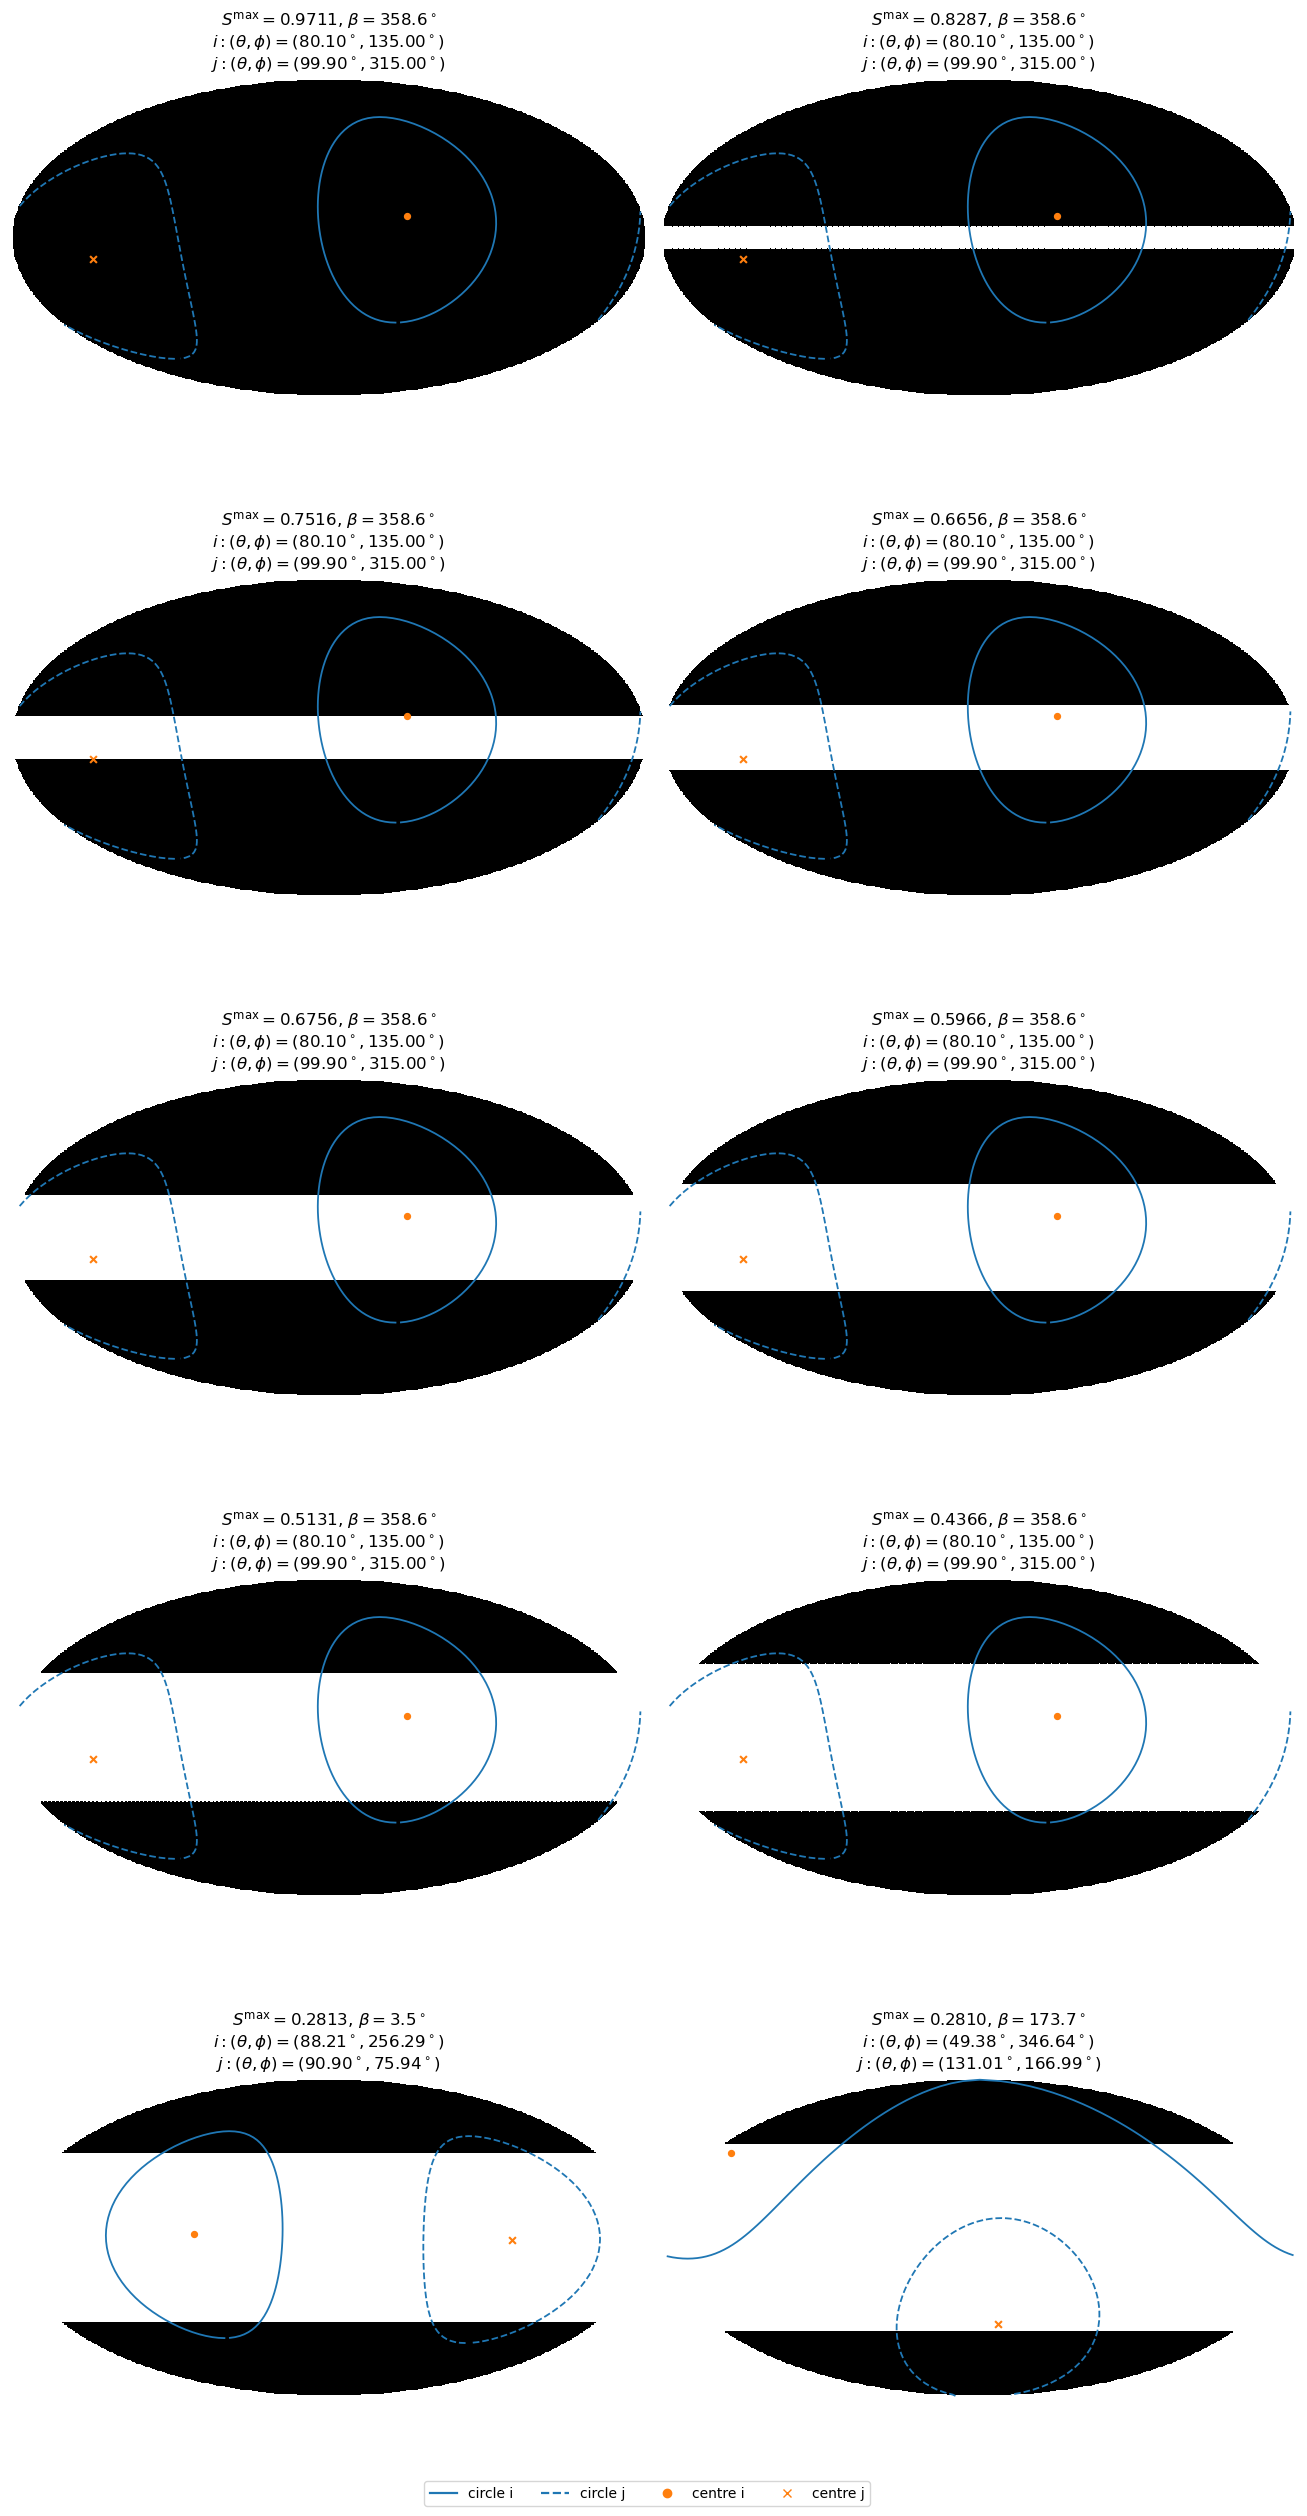

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_07_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_07_alpha50_pairs.png


################################################################################
Processing inj_08
################################################################################

inj_08


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.973384,510.000000,358.593750,35.275372,225.000000,144.724628,45.000000,180.000000,0.000000,0.000000
1,5,50.161562,0.887909,510.000000,358.593750,35.275372,225.000000,144.724628,45.000000,180.000000,0.113281,0.113281
2,10,50.161562,0.613577,510.000000,358.593750,35.275372,225.000000,144.724628,45.000000,180.000000,0.425781,0.425781
3,15,50.161562,0.490412,510.000000,358.593750,35.275372,225.000000,144.724628,45.000000,180.000000,0.589844,0.589844
4,20,50.161562,0.355250,510.000000,358.593750,35.275372,225.000000,144.724628,45.000000,180.000000,0.730469,0.730469
5,25,50.161562,0.281437,510.000000,358.593750,35.275372,225.000000,144.724628,45.000000,180.000000,0.855469,0.855469
6,30,50.161562,0.273854,287.000000,201.796875,73.665177,29.179688,106.334823,209.179688,180.000000,0.964844,0.644531
7,35,50.161562,0.273079,98.000000,68.906250,51.699078,129.375000,127.544325,310.078125,179.061881,1.000000,0.900391
8,40,50.161562,0.276013,278.000000,195.468750,62.046813,89.648438,118.291549,270.000000,179.541062,1.000000,0.714844
9,45,50.161562,0.290622,262.000000,184.218750,81.010701,307.617188,98.084014,127.968750,179.030252,1.000000,0.814453


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


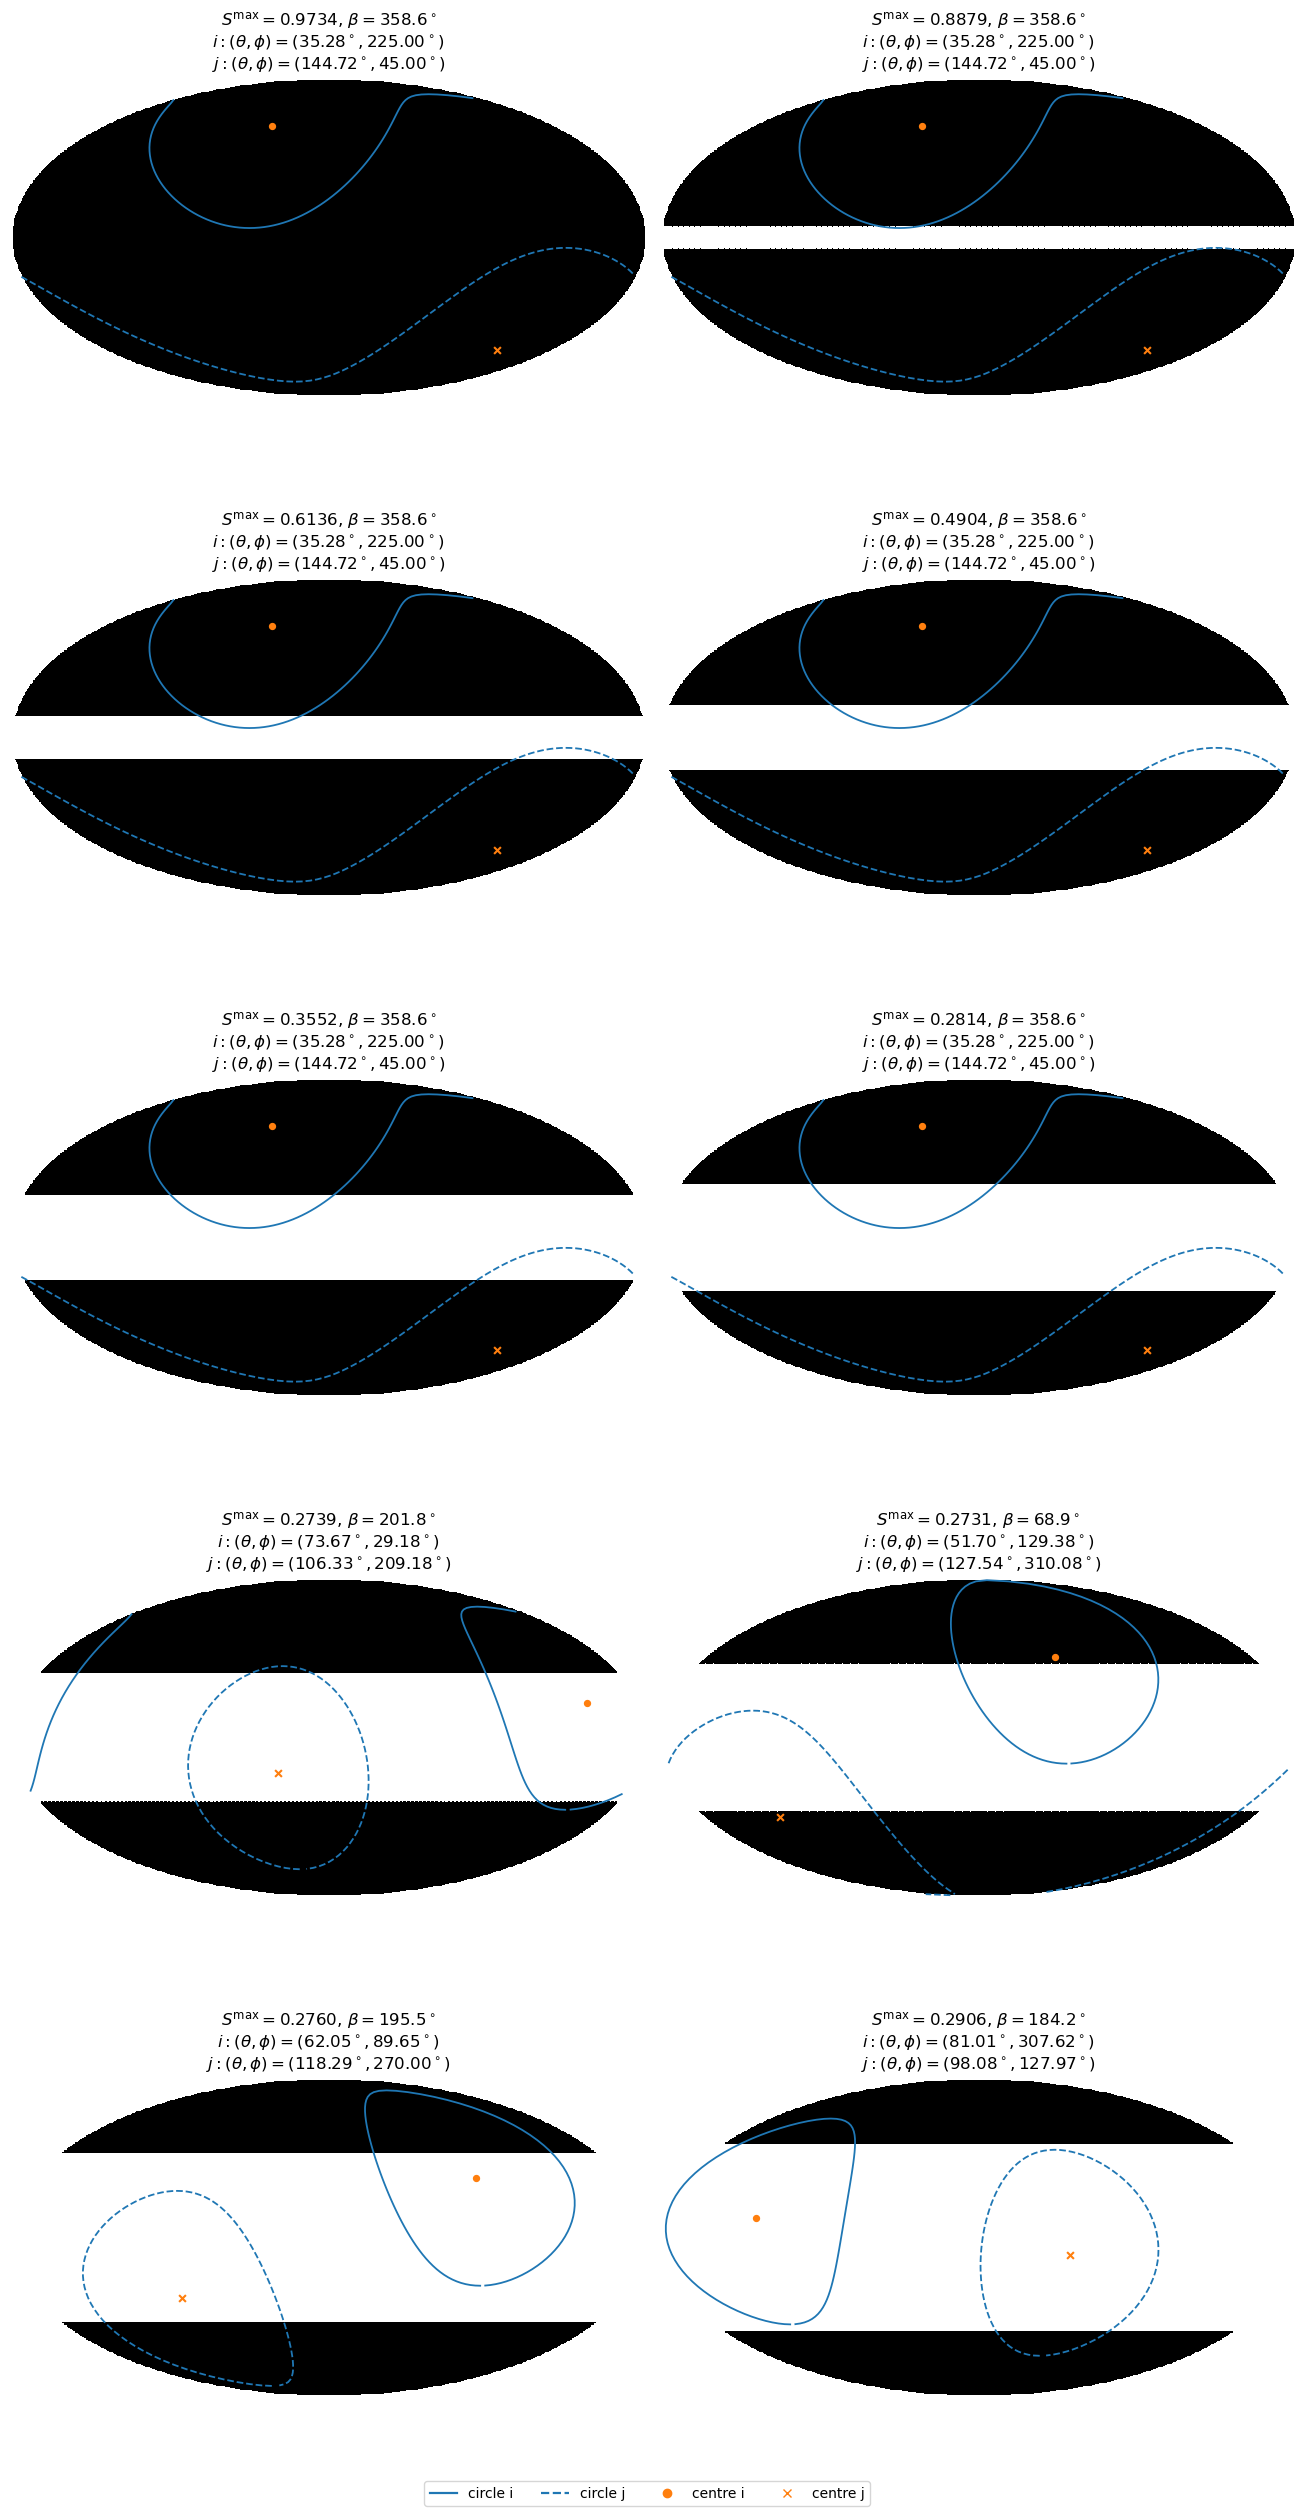

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_08_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_08_alpha50_pairs.png


################################################################################
Processing inj_09
################################################################################

inj_09


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.973209,510.000000,358.593750,55.046135,44.648438,124.953865,224.648438,180.000000,0.000000,0.000000
1,5,50.161562,0.731452,510.000000,358.593750,55.046135,44.648438,124.953865,224.648438,180.000000,0.218750,0.218750
2,10,50.161562,0.568470,510.000000,358.593750,55.046135,44.648438,124.953865,224.648438,180.000000,0.460938,0.460938
3,15,50.161562,0.268745,106.000000,74.531250,86.715631,141.328125,93.284369,320.625000,179.298030,0.820312,0.437500
4,20,50.161562,0.270367,121.000000,85.078125,47.789630,310.039370,131.411189,129.375000,179.059847,0.972656,0.712891
5,25,50.161562,0.261574,244.000000,171.562500,28.810224,25.961538,151.943837,206.644737,179.178778,1.000000,0.394531
6,30,50.161562,0.275395,287.000000,201.796875,73.665177,29.179688,106.334823,209.179688,180.000000,1.000000,0.644531
7,35,50.161562,0.270590,250.000000,175.781250,59.654817,106.171875,121.039240,286.171875,179.305943,1.000000,0.628906
8,40,50.161562,0.275361,509.000000,357.890625,85.219808,186.679688,95.679190,6.328125,179.035239,1.000000,0.738281
9,45,50.161562,0.281201,247.000000,173.671875,49.379815,346.640625,131.014500,166.992188,179.524320,1.000000,0.679688


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


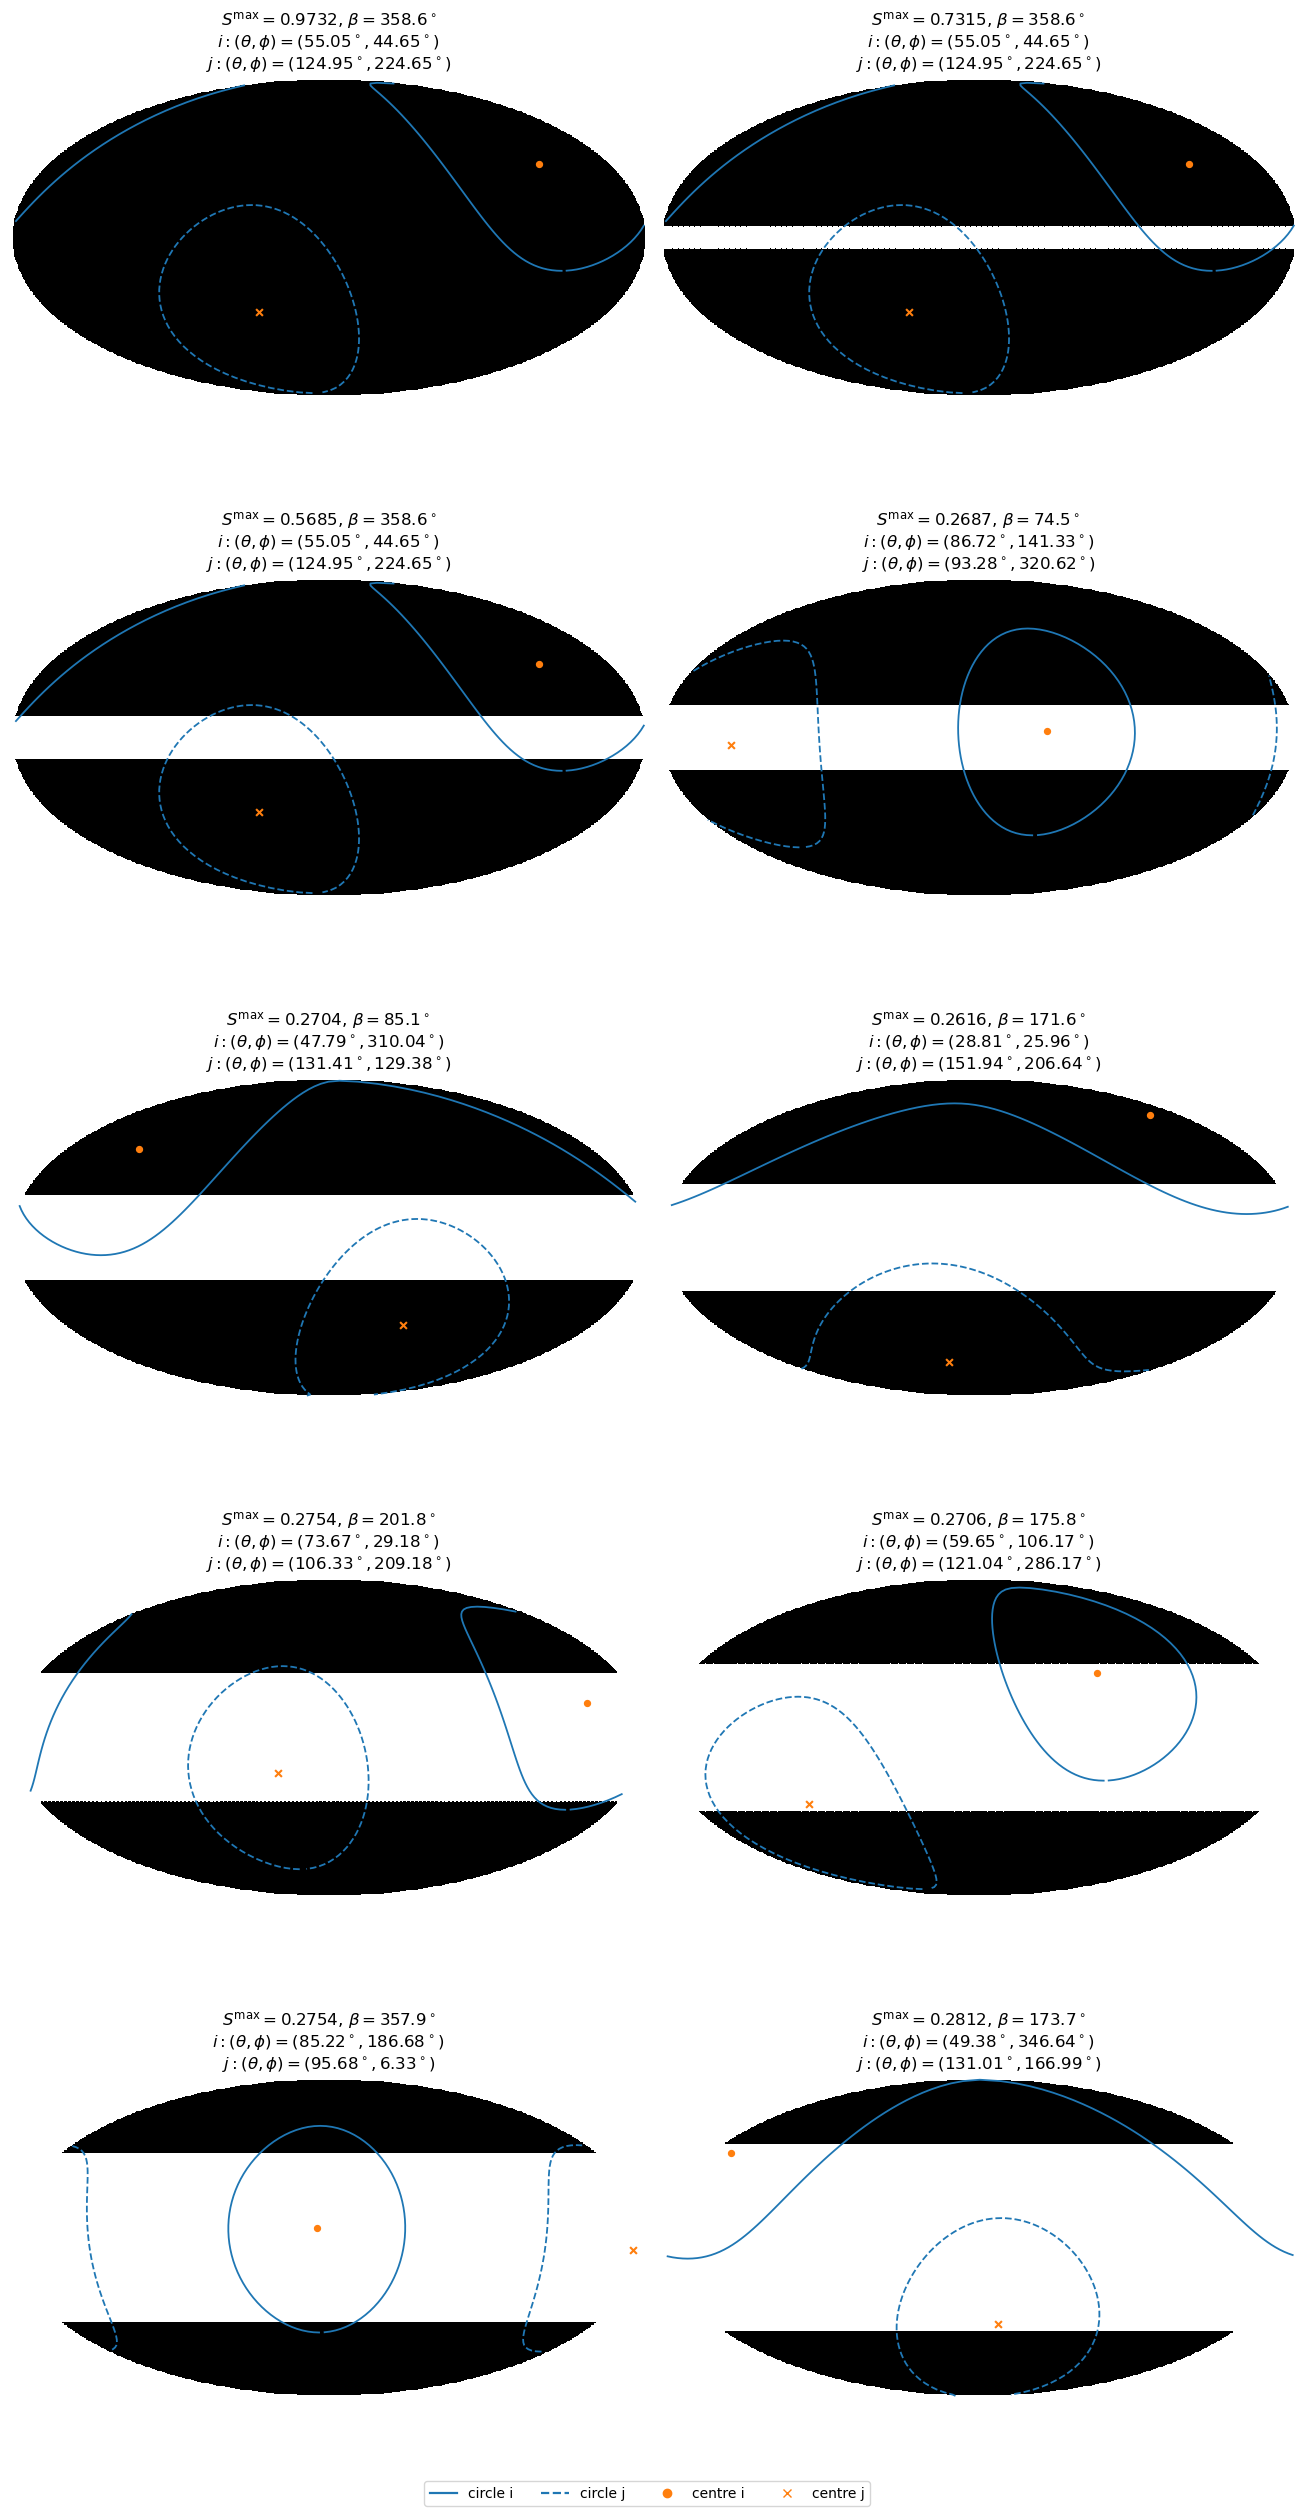

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_09_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_09_alpha50_pairs.png


################################################################################
Processing inj_10
################################################################################

inj_10


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.691339,510.000000,358.593750,9.880275,225.000000,170.119725,45.000000,180.000000,0.000000,0.000000
1,5,50.161562,0.691339,510.000000,358.593750,9.880275,225.000000,170.119725,45.000000,180.000000,0.000000,0.000000
2,10,50.161562,0.691339,510.000000,358.593750,9.880275,225.000000,170.119725,45.000000,180.000000,0.000000,0.000000
3,15,50.161562,0.691339,510.000000,358.593750,9.880275,225.000000,170.119725,45.000000,180.000000,0.000000,0.000000
4,20,50.161562,0.691339,510.000000,358.593750,9.880275,225.000000,170.119725,45.000000,180.000000,0.000000,0.000000
5,25,50.161562,0.691339,510.000000,358.593750,9.880275,225.000000,170.119725,45.000000,180.000000,0.000000,0.000000
6,30,50.161562,0.690201,510.000000,358.593750,9.880275,225.000000,170.119725,45.000000,180.000000,0.052734,0.054688
7,35,50.161562,0.273086,250.000000,175.781250,59.654817,106.171875,121.039240,286.171875,179.305943,0.710938,0.628906
8,40,50.161562,0.274496,509.000000,357.890625,85.219808,186.679688,95.679190,6.328125,179.035239,1.000000,0.738281
9,45,50.161562,0.276822,242.000000,170.156250,69.576385,262.265625,110.423615,82.265625,nan,1.000000,0.759766


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


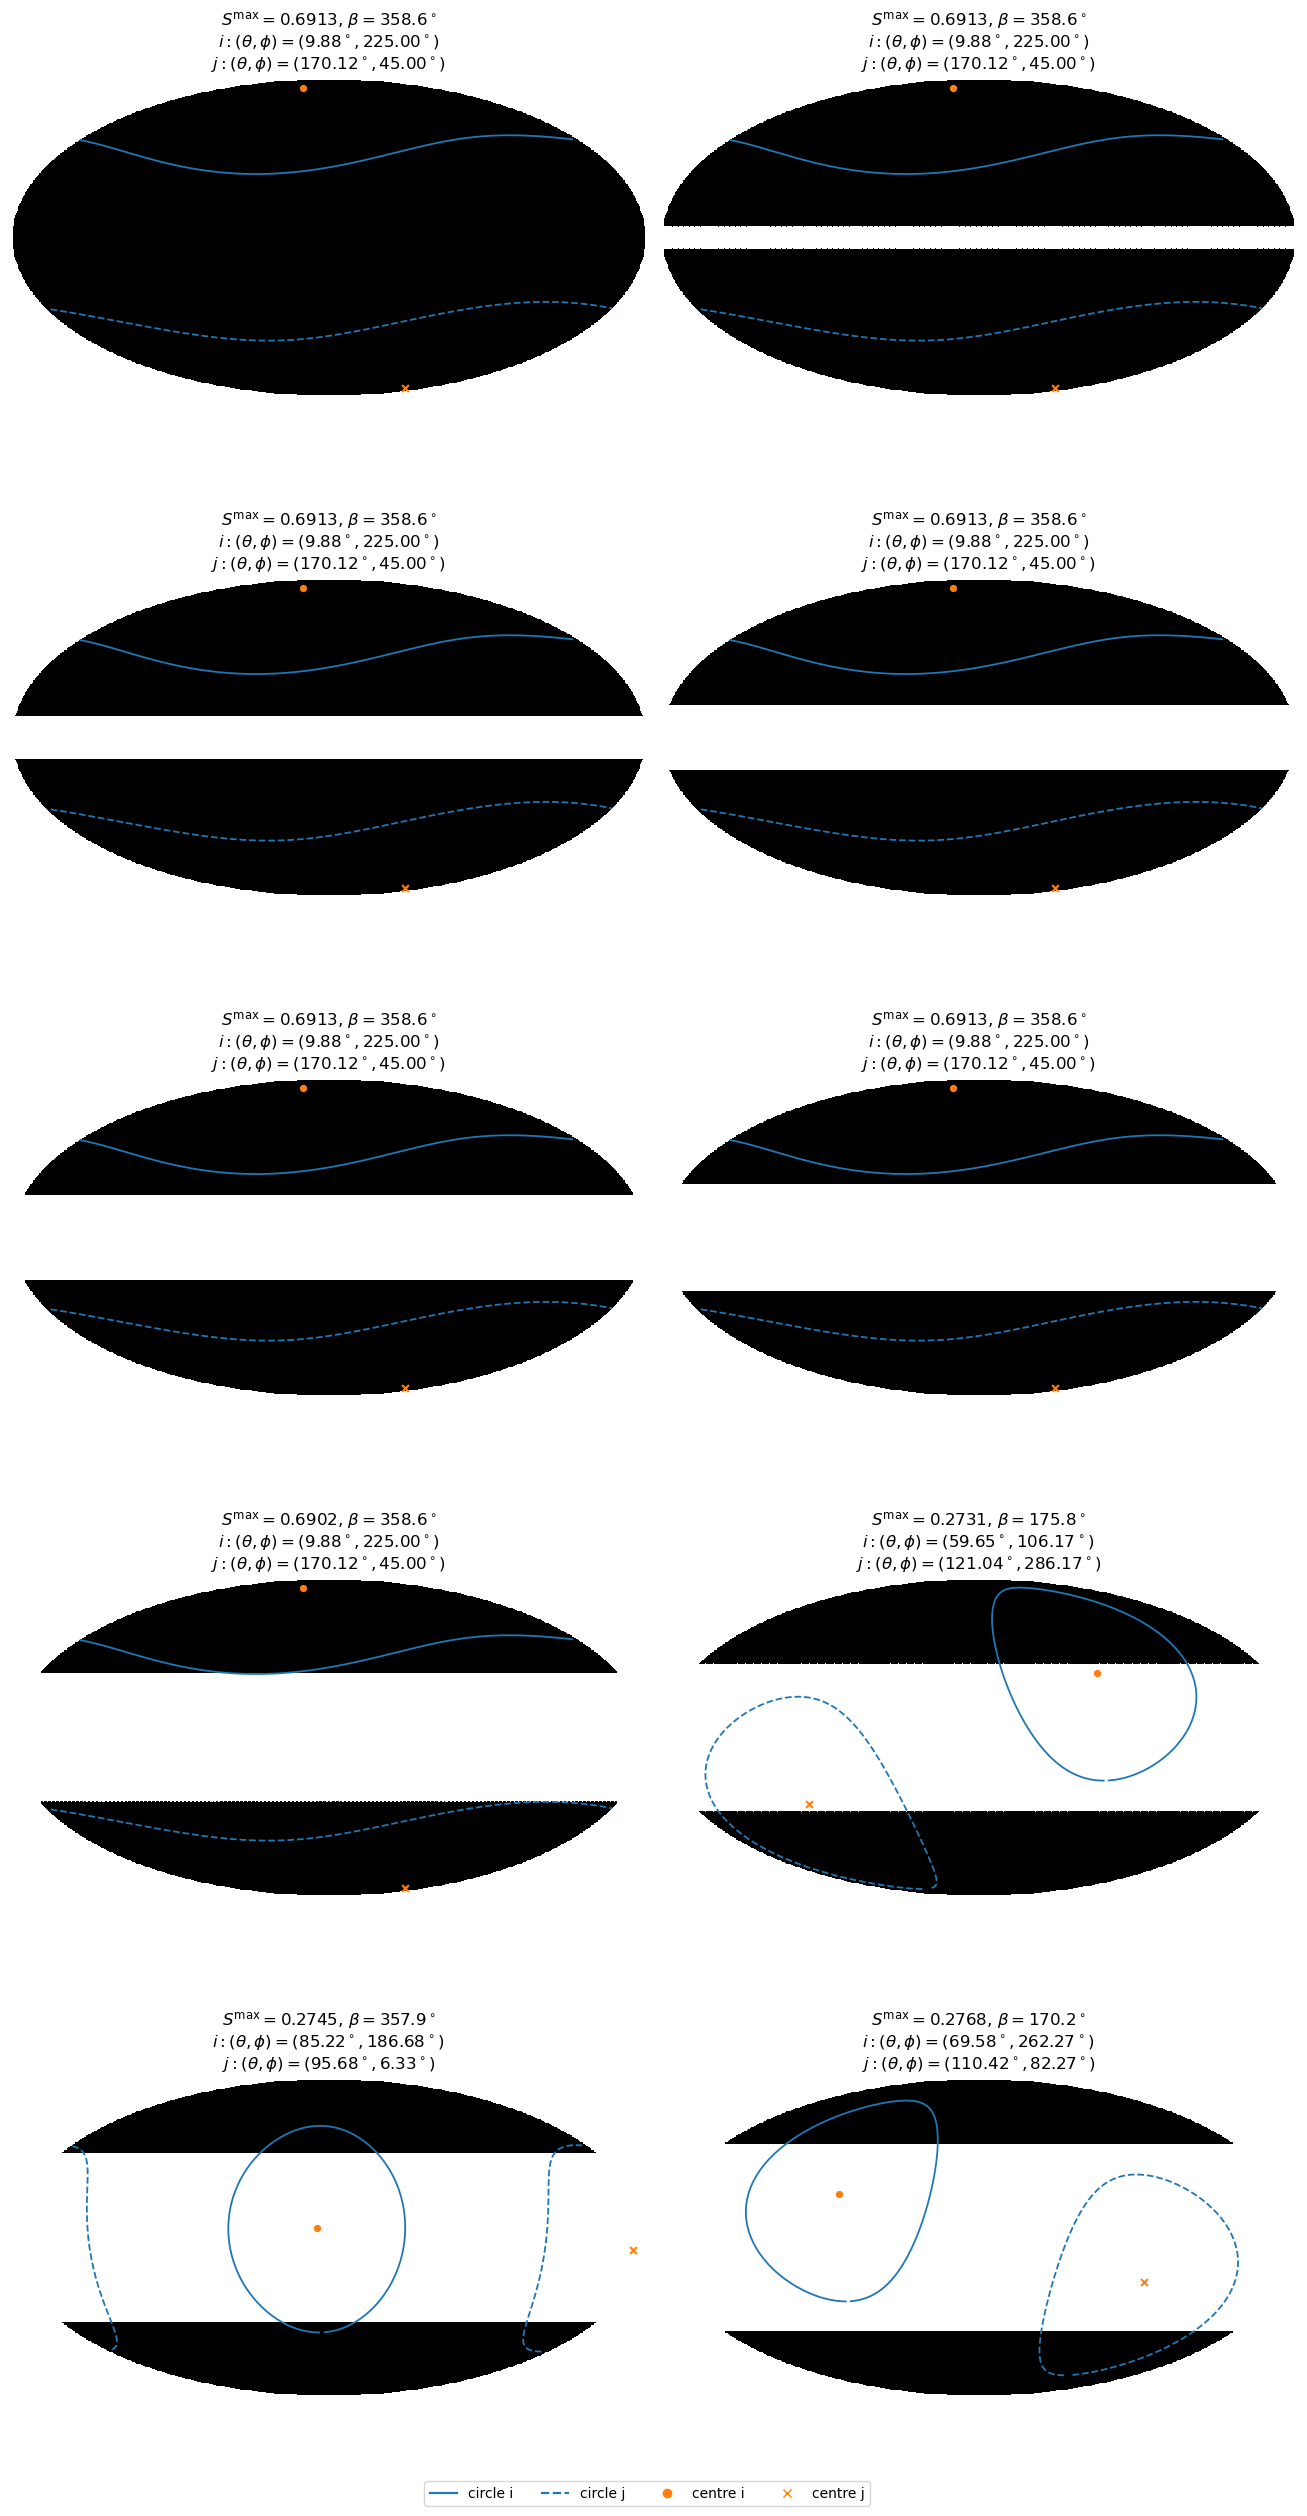

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_10_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_10_alpha50_pairs.png


################################################################################
Processing inj_11
################################################################################

inj_11


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.717286,510.000000,358.593750,9.880275,315.000000,170.119725,135.000000,180.000000,0.000000,0.000000
1,5,50.161562,0.717286,510.000000,358.593750,9.880275,315.000000,170.119725,135.000000,180.000000,0.000000,0.000000
2,10,50.161562,0.717286,510.000000,358.593750,9.880275,315.000000,170.119725,135.000000,180.000000,0.000000,0.000000
3,15,50.161562,0.717286,510.000000,358.593750,9.880275,315.000000,170.119725,135.000000,180.000000,0.000000,0.000000
4,20,50.161562,0.717286,510.000000,358.593750,9.880275,315.000000,170.119725,135.000000,180.000000,0.000000,0.000000
5,25,50.161562,0.717286,510.000000,358.593750,9.880275,315.000000,170.119725,135.000000,180.000000,0.000000,0.000000
6,30,50.161562,0.706691,510.000000,358.593750,9.880275,315.000000,170.119725,135.000000,180.000000,0.052734,0.054688
7,35,50.161562,0.277205,239.000000,168.046875,73.042237,174.726562,106.024100,355.078125,179.007347,0.710938,0.708984
8,40,50.161562,0.273863,5.000000,3.515625,88.209215,256.289062,90.895283,75.937500,179.037997,1.000000,0.658203
9,45,50.161562,0.280270,247.000000,173.671875,49.379815,346.640625,131.014500,166.992188,179.524320,1.000000,0.679688


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


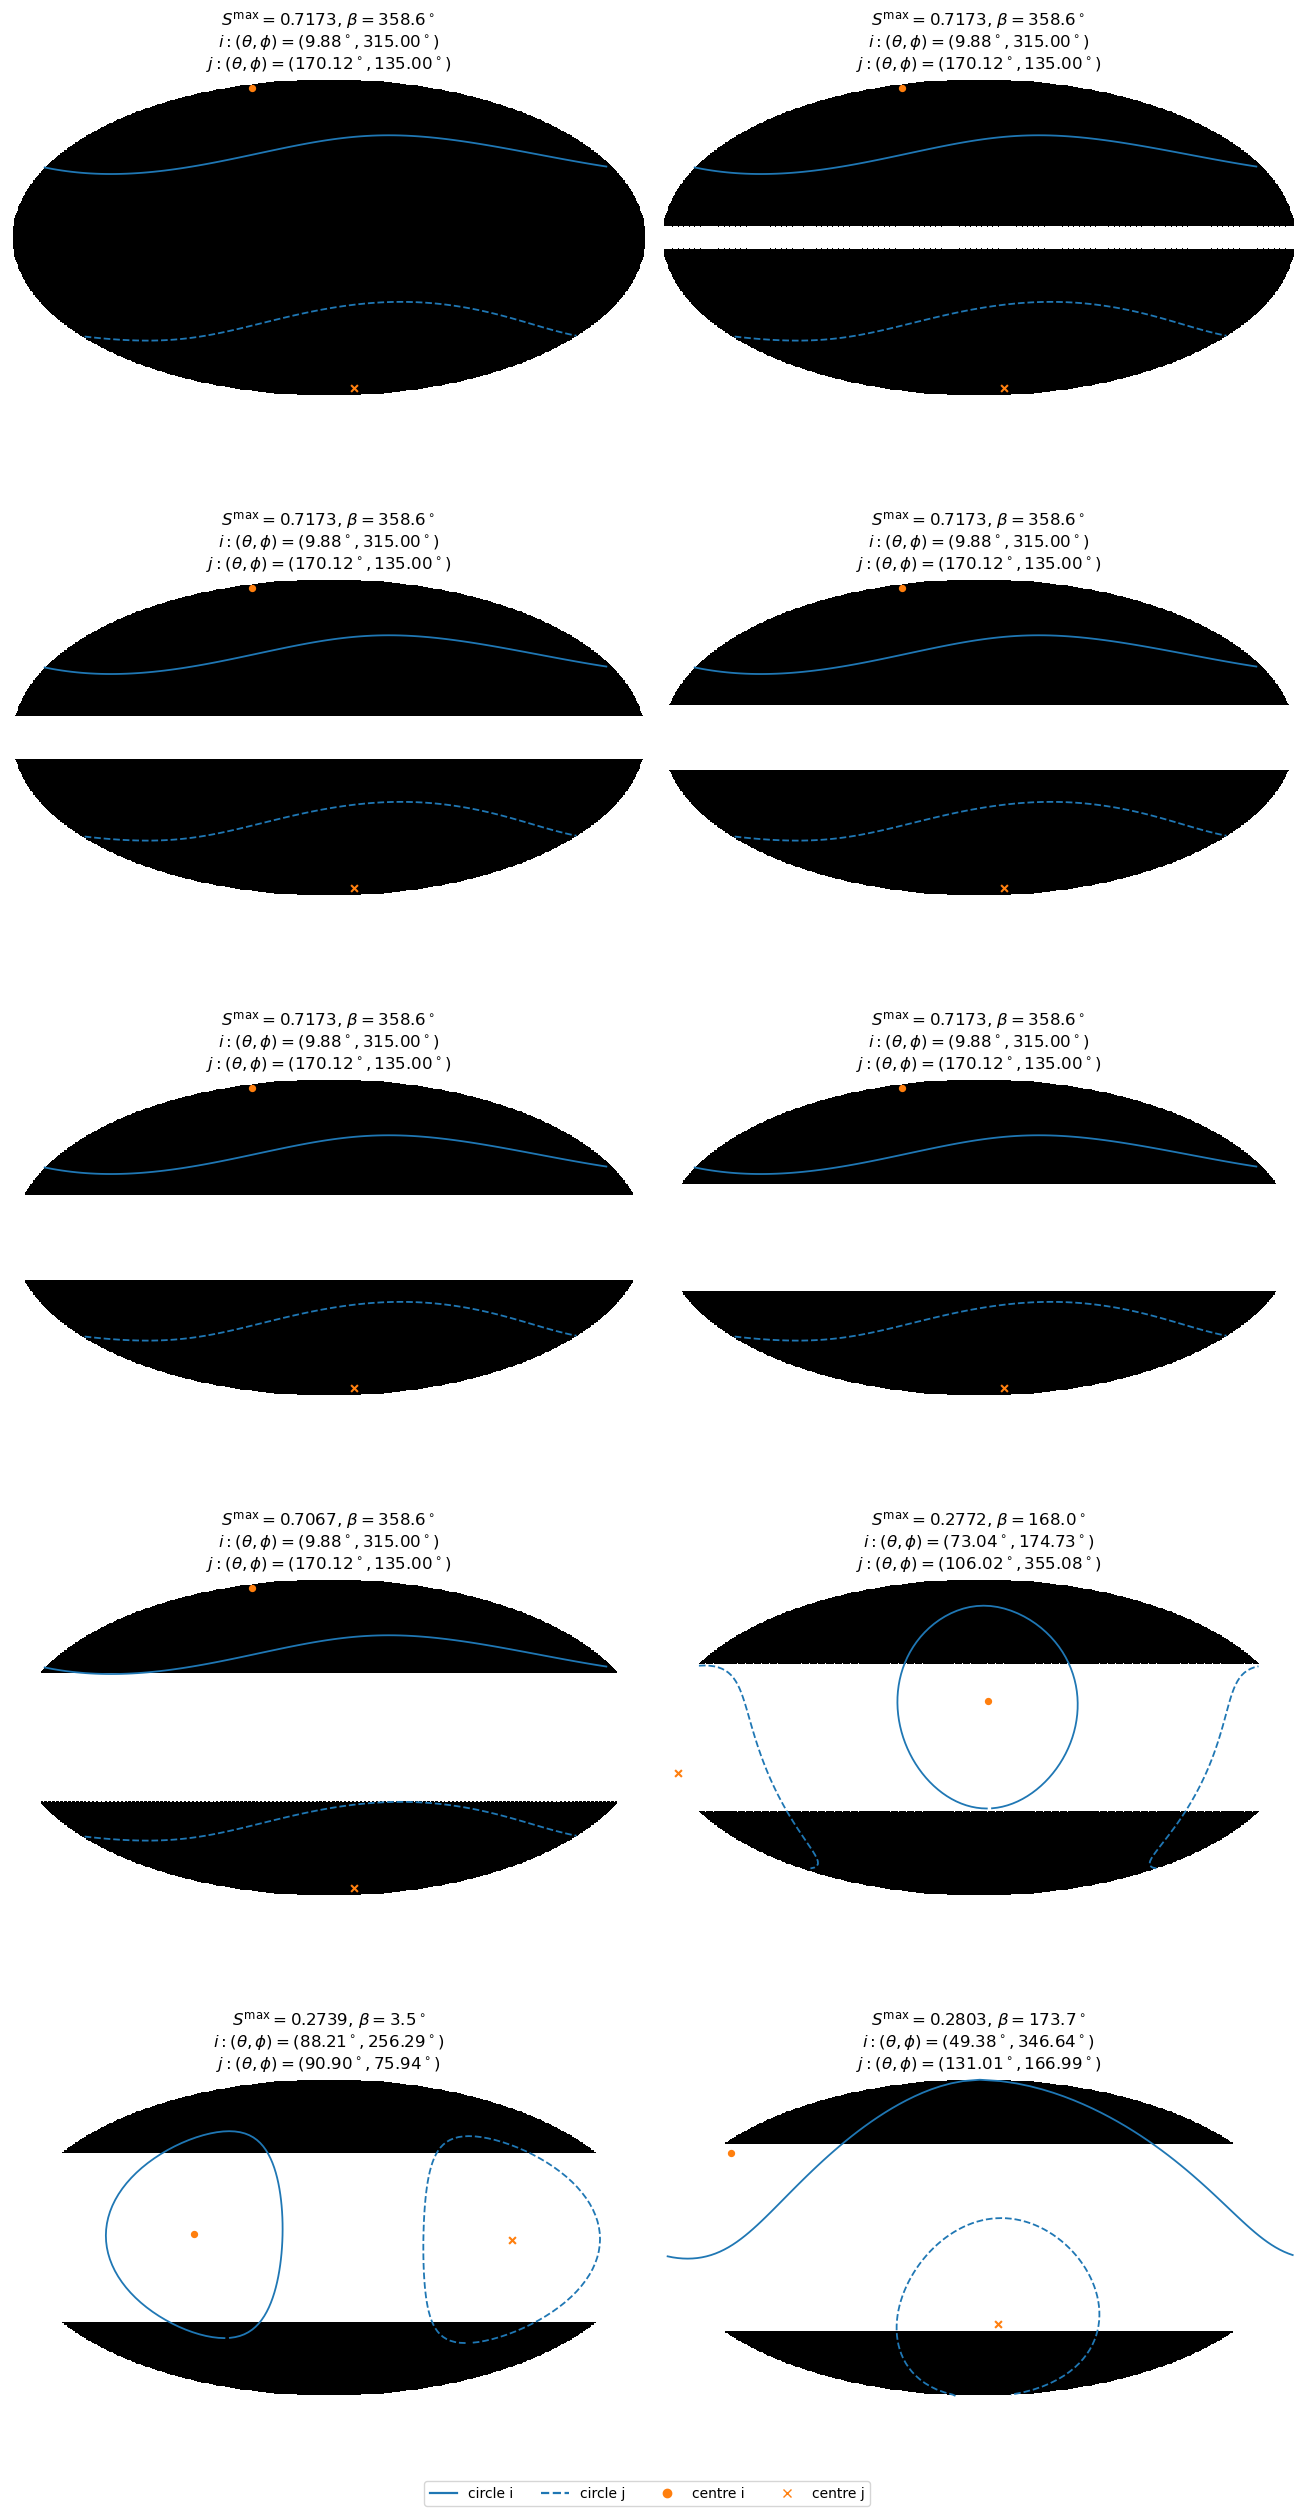

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_11_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_11_alpha50_pairs.png


################################################################################
Processing inj_12
################################################################################

inj_12


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.664815,510.000000,358.593750,9.880275,45.000000,170.119725,225.000000,180.000000,0.000000,0.000000
1,5,50.161562,0.664815,510.000000,358.593750,9.880275,45.000000,170.119725,225.000000,180.000000,0.000000,0.000000
2,10,50.161562,0.664815,510.000000,358.593750,9.880275,45.000000,170.119725,225.000000,180.000000,0.000000,0.000000
3,15,50.161562,0.664815,510.000000,358.593750,9.880275,45.000000,170.119725,225.000000,180.000000,0.000000,0.000000
4,20,50.161562,0.664815,510.000000,358.593750,9.880275,45.000000,170.119725,225.000000,180.000000,0.000000,0.000000
5,25,50.161562,0.664815,510.000000,358.593750,9.880275,45.000000,170.119725,225.000000,180.000000,0.000000,0.000000
6,30,50.161562,0.660773,510.000000,358.593750,9.880275,45.000000,170.119725,225.000000,180.000000,0.052734,0.054688
7,35,50.161562,0.272691,250.000000,175.781250,59.654817,106.171875,121.039240,286.171875,179.305943,0.710938,0.628906
8,40,50.161562,0.273611,509.000000,357.890625,85.219808,186.679688,95.679190,6.328125,179.035239,1.000000,0.738281
9,45,50.161562,0.284046,509.000000,357.890625,88.507754,202.500000,90.895283,21.796875,179.077758,1.000000,0.777344


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


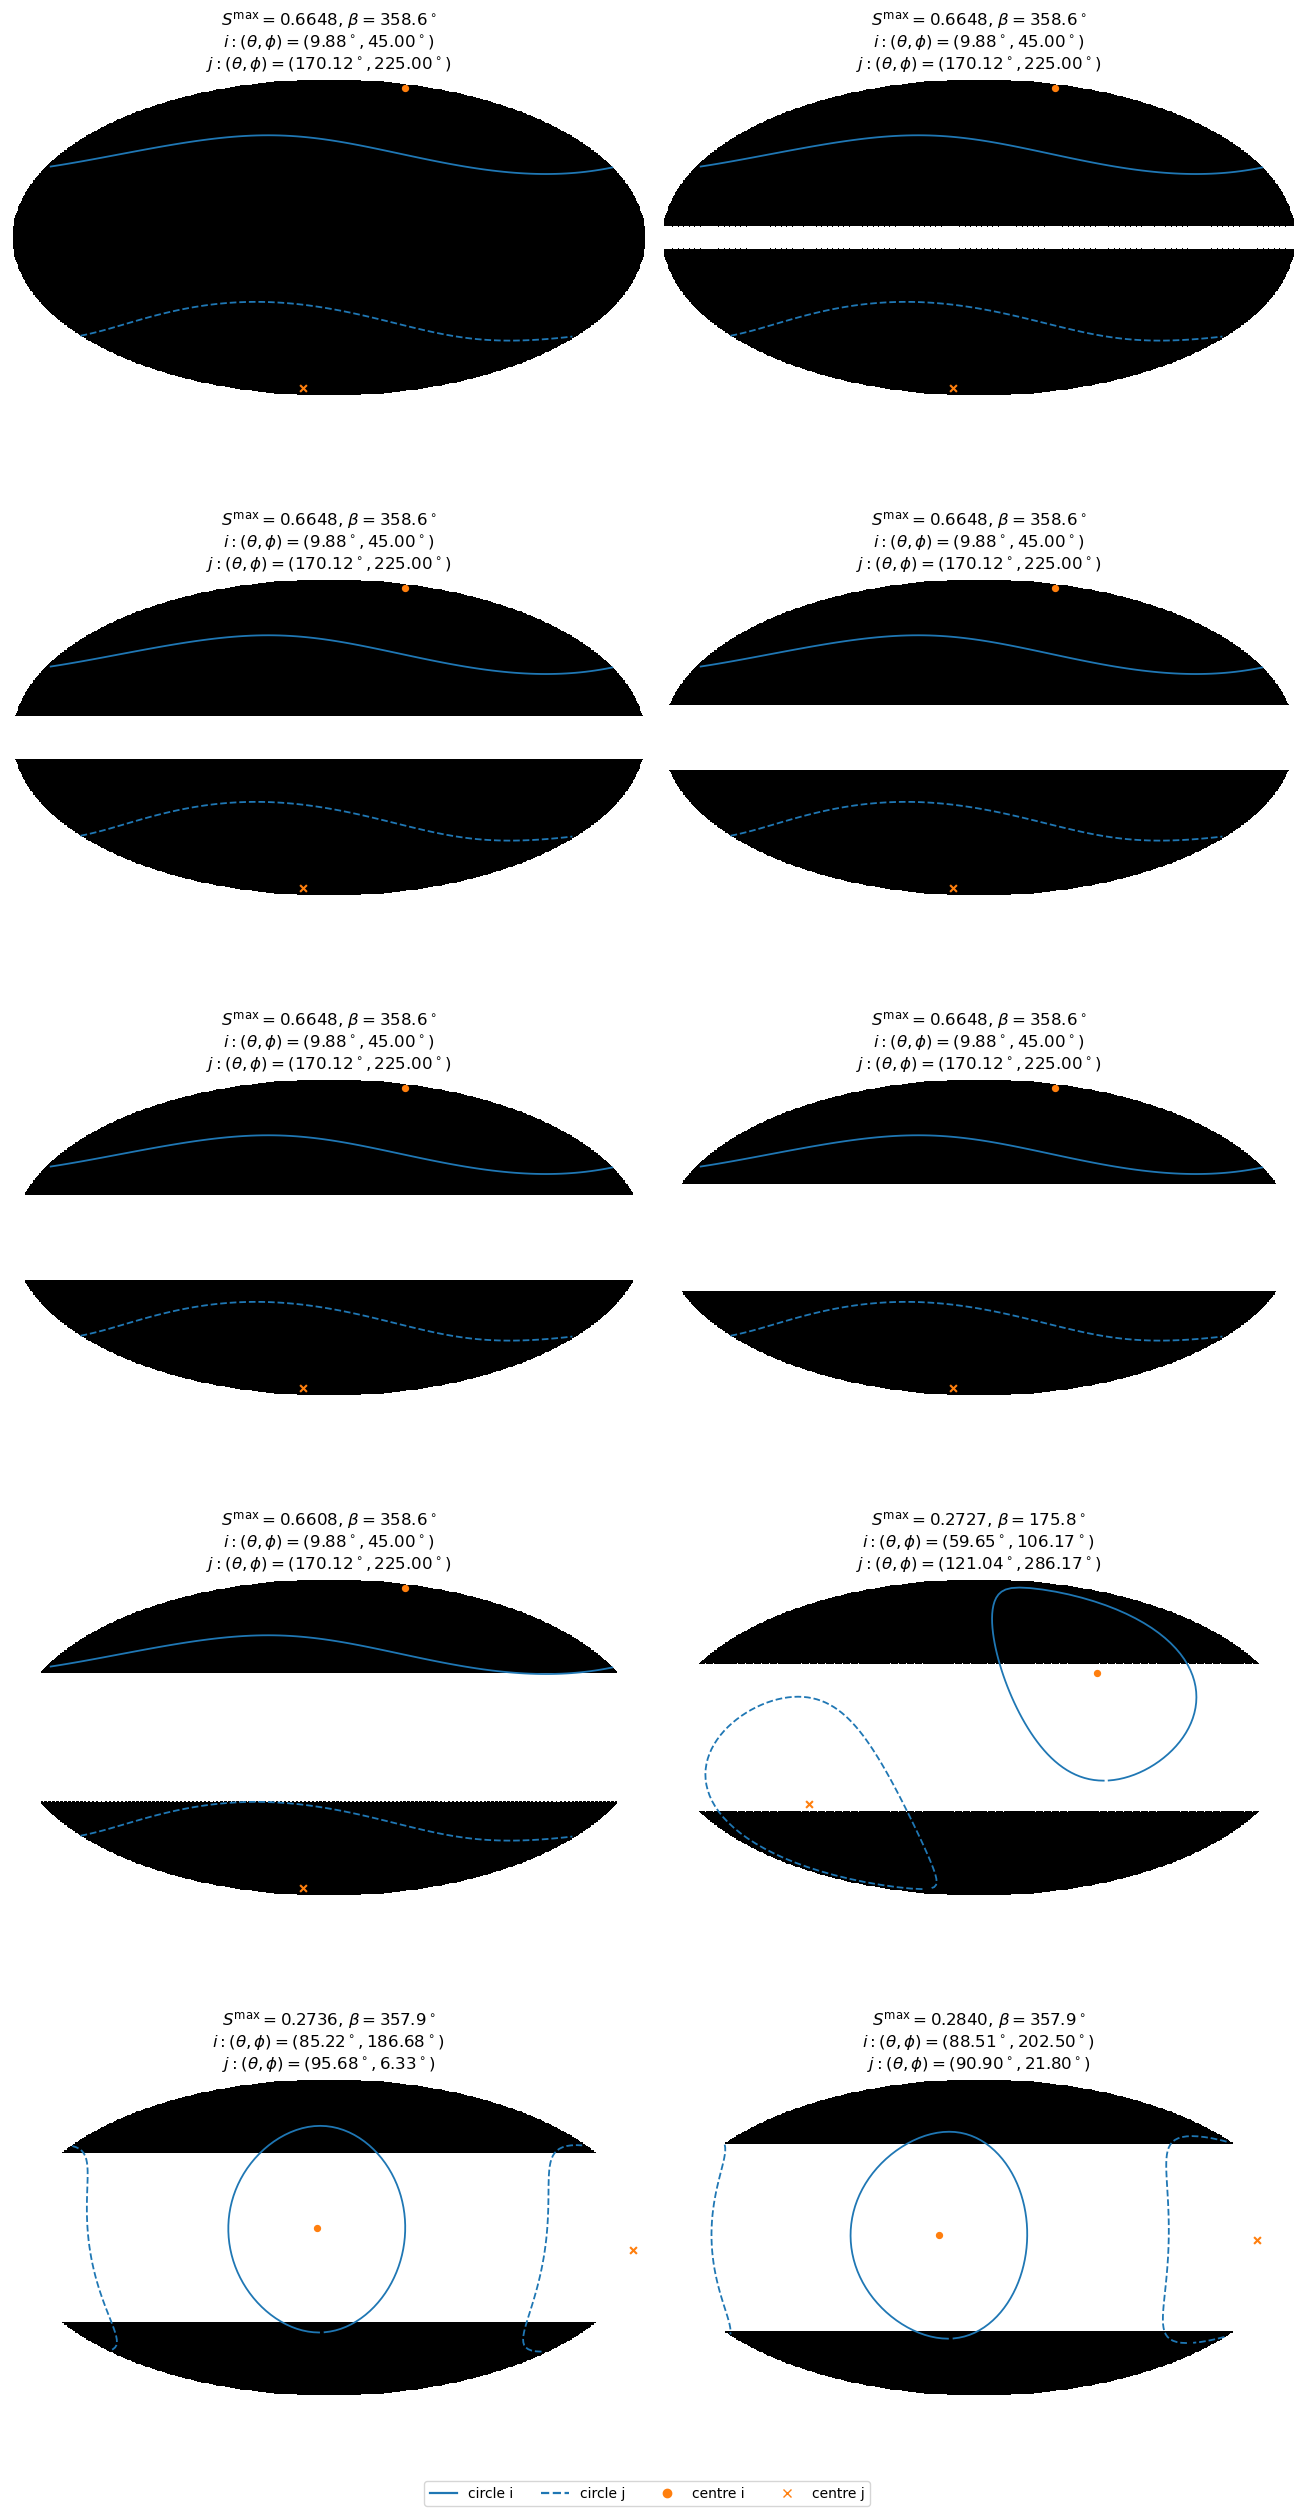

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_12_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_12_alpha50_pairs.png


################################################################################
Processing inj_13
################################################################################

inj_13


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.674036,510.000000,358.593750,9.880275,135.000000,170.119725,315.000000,180.000000,0.000000,0.000000
1,5,50.161562,0.674036,510.000000,358.593750,9.880275,135.000000,170.119725,315.000000,180.000000,0.000000,0.000000
2,10,50.161562,0.674036,510.000000,358.593750,9.880275,135.000000,170.119725,315.000000,180.000000,0.000000,0.000000
3,15,50.161562,0.674036,510.000000,358.593750,9.880275,135.000000,170.119725,315.000000,180.000000,0.000000,0.000000
4,20,50.161562,0.674036,510.000000,358.593750,9.880275,135.000000,170.119725,315.000000,180.000000,0.000000,0.000000
5,25,50.161562,0.674036,510.000000,358.593750,9.880275,135.000000,170.119725,315.000000,180.000000,0.000000,0.000000
6,30,50.161562,0.661684,510.000000,358.593750,9.880275,135.000000,170.119725,315.000000,180.000000,0.052734,0.054688
7,35,50.161562,0.274011,493.000000,346.640625,86.715631,298.828125,94.181528,119.179688,179.036691,0.710938,0.609375
8,40,50.161562,0.274575,509.000000,357.890625,85.219808,186.679688,95.679190,6.328125,179.035239,1.000000,0.738281
9,45,50.161562,0.293723,258.000000,181.406250,87.313276,336.093750,92.089372,156.796875,179.077855,1.000000,0.769531


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


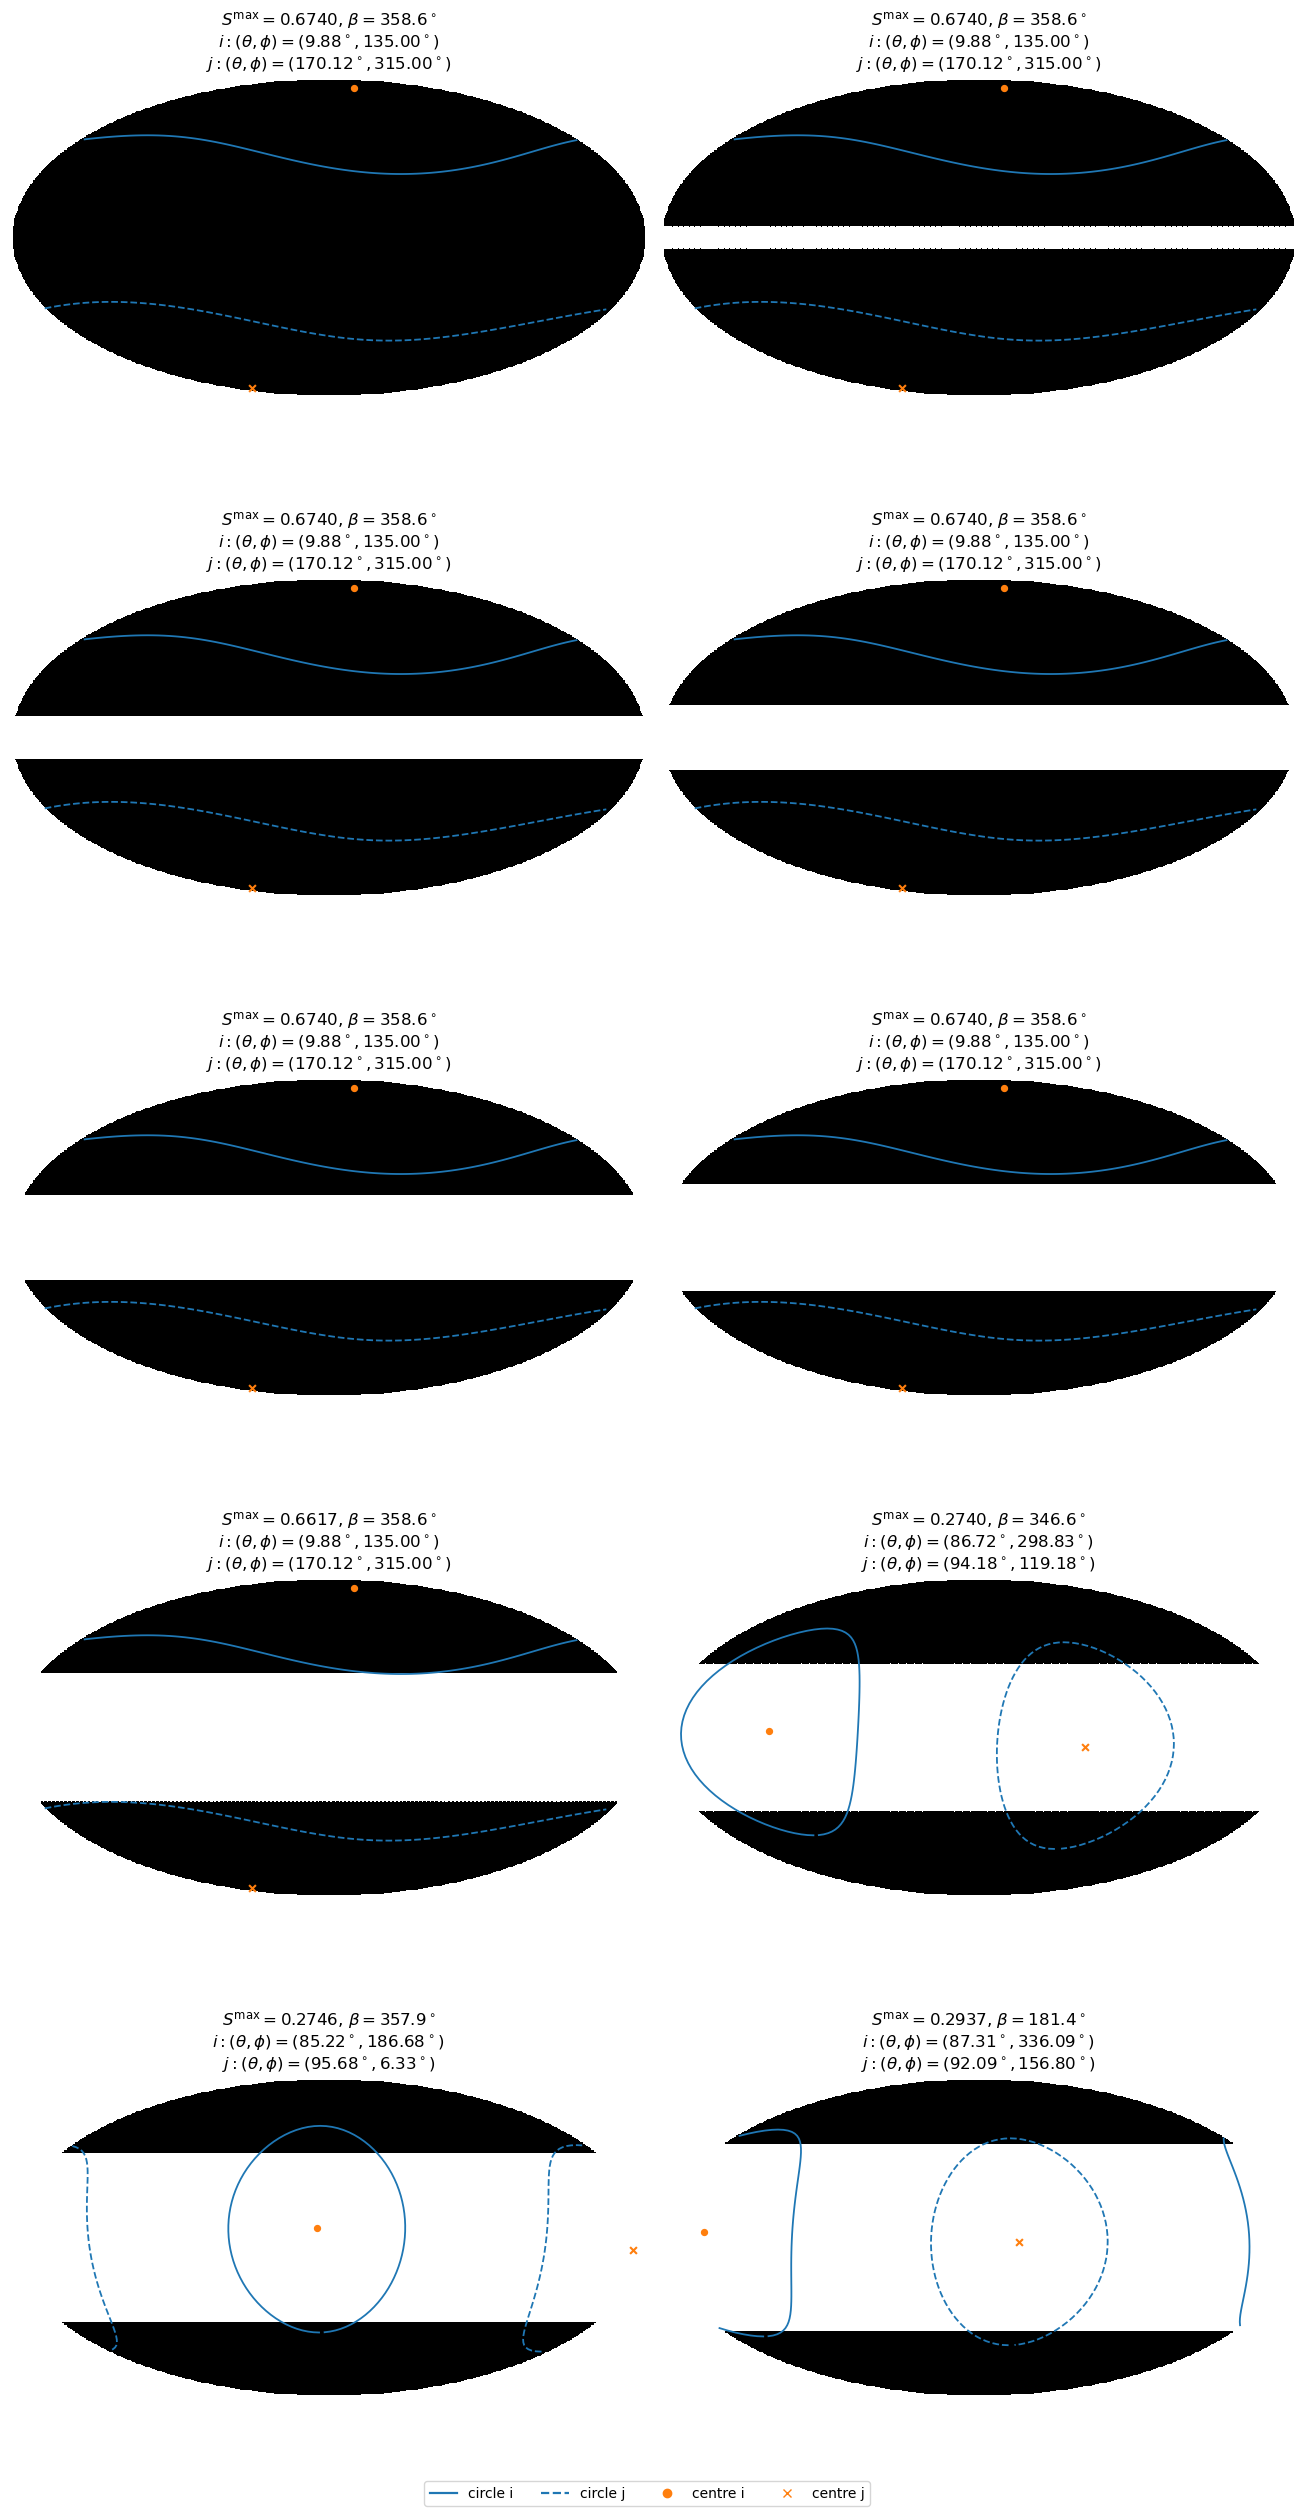

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_13_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_13_alpha50_pairs.png


################################################################################
Processing inj_14
################################################################################

inj_14


,half_width_deg,alpha_deg,Smax,beta_max_bin,beta_max_deg,theta_i_deg,phi_i_deg,theta_j_deg,phi_j_deg,separation_deg,f_lost_injected_pair,f_lost_winning_pair
0,0,50.161562,0.943648,510.000000,358.593750,25.051916,209.779412,154.948084,29.779412,180.000000,0.000000,0.000000
1,5,50.161562,0.943648,510.000000,358.593750,25.051916,209.779412,154.948084,29.779412,180.000000,0.000000,0.000000
2,10,50.161562,0.943648,510.000000,358.593750,25.051916,209.779412,154.948084,29.779412,180.000000,0.000000,0.000000
3,15,50.161562,0.918249,510.000000,358.593750,25.051916,209.779412,154.948084,29.779412,180.000000,0.093750,0.093750
4,20,50.161562,0.496063,510.000000,358.593750,25.051916,209.779412,154.948084,29.779412,180.000000,0.476562,0.472656
5,25,50.161562,0.325557,510.000000,358.593750,25.051916,209.779412,154.948084,29.779412,180.000000,0.675781,0.675781
6,30,50.161562,0.266561,443.000000,311.484375,76.138050,162.070312,104.169522,341.718750,179.540710,0.839844,0.757812
7,35,50.161562,0.280105,493.000000,346.640625,86.715631,298.828125,94.181528,119.179688,179.036691,0.988281,0.609375
8,40,50.161562,0.274210,509.000000,357.890625,85.219808,186.679688,95.679190,6.328125,179.035239,1.000000,0.738281
9,45,50.161562,0.281286,509.000000,357.890625,88.507754,202.500000,90.895283,21.796875,179.077758,1.000000,0.777344


/tmp/ipykernel_1859235/256142311.py:796: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


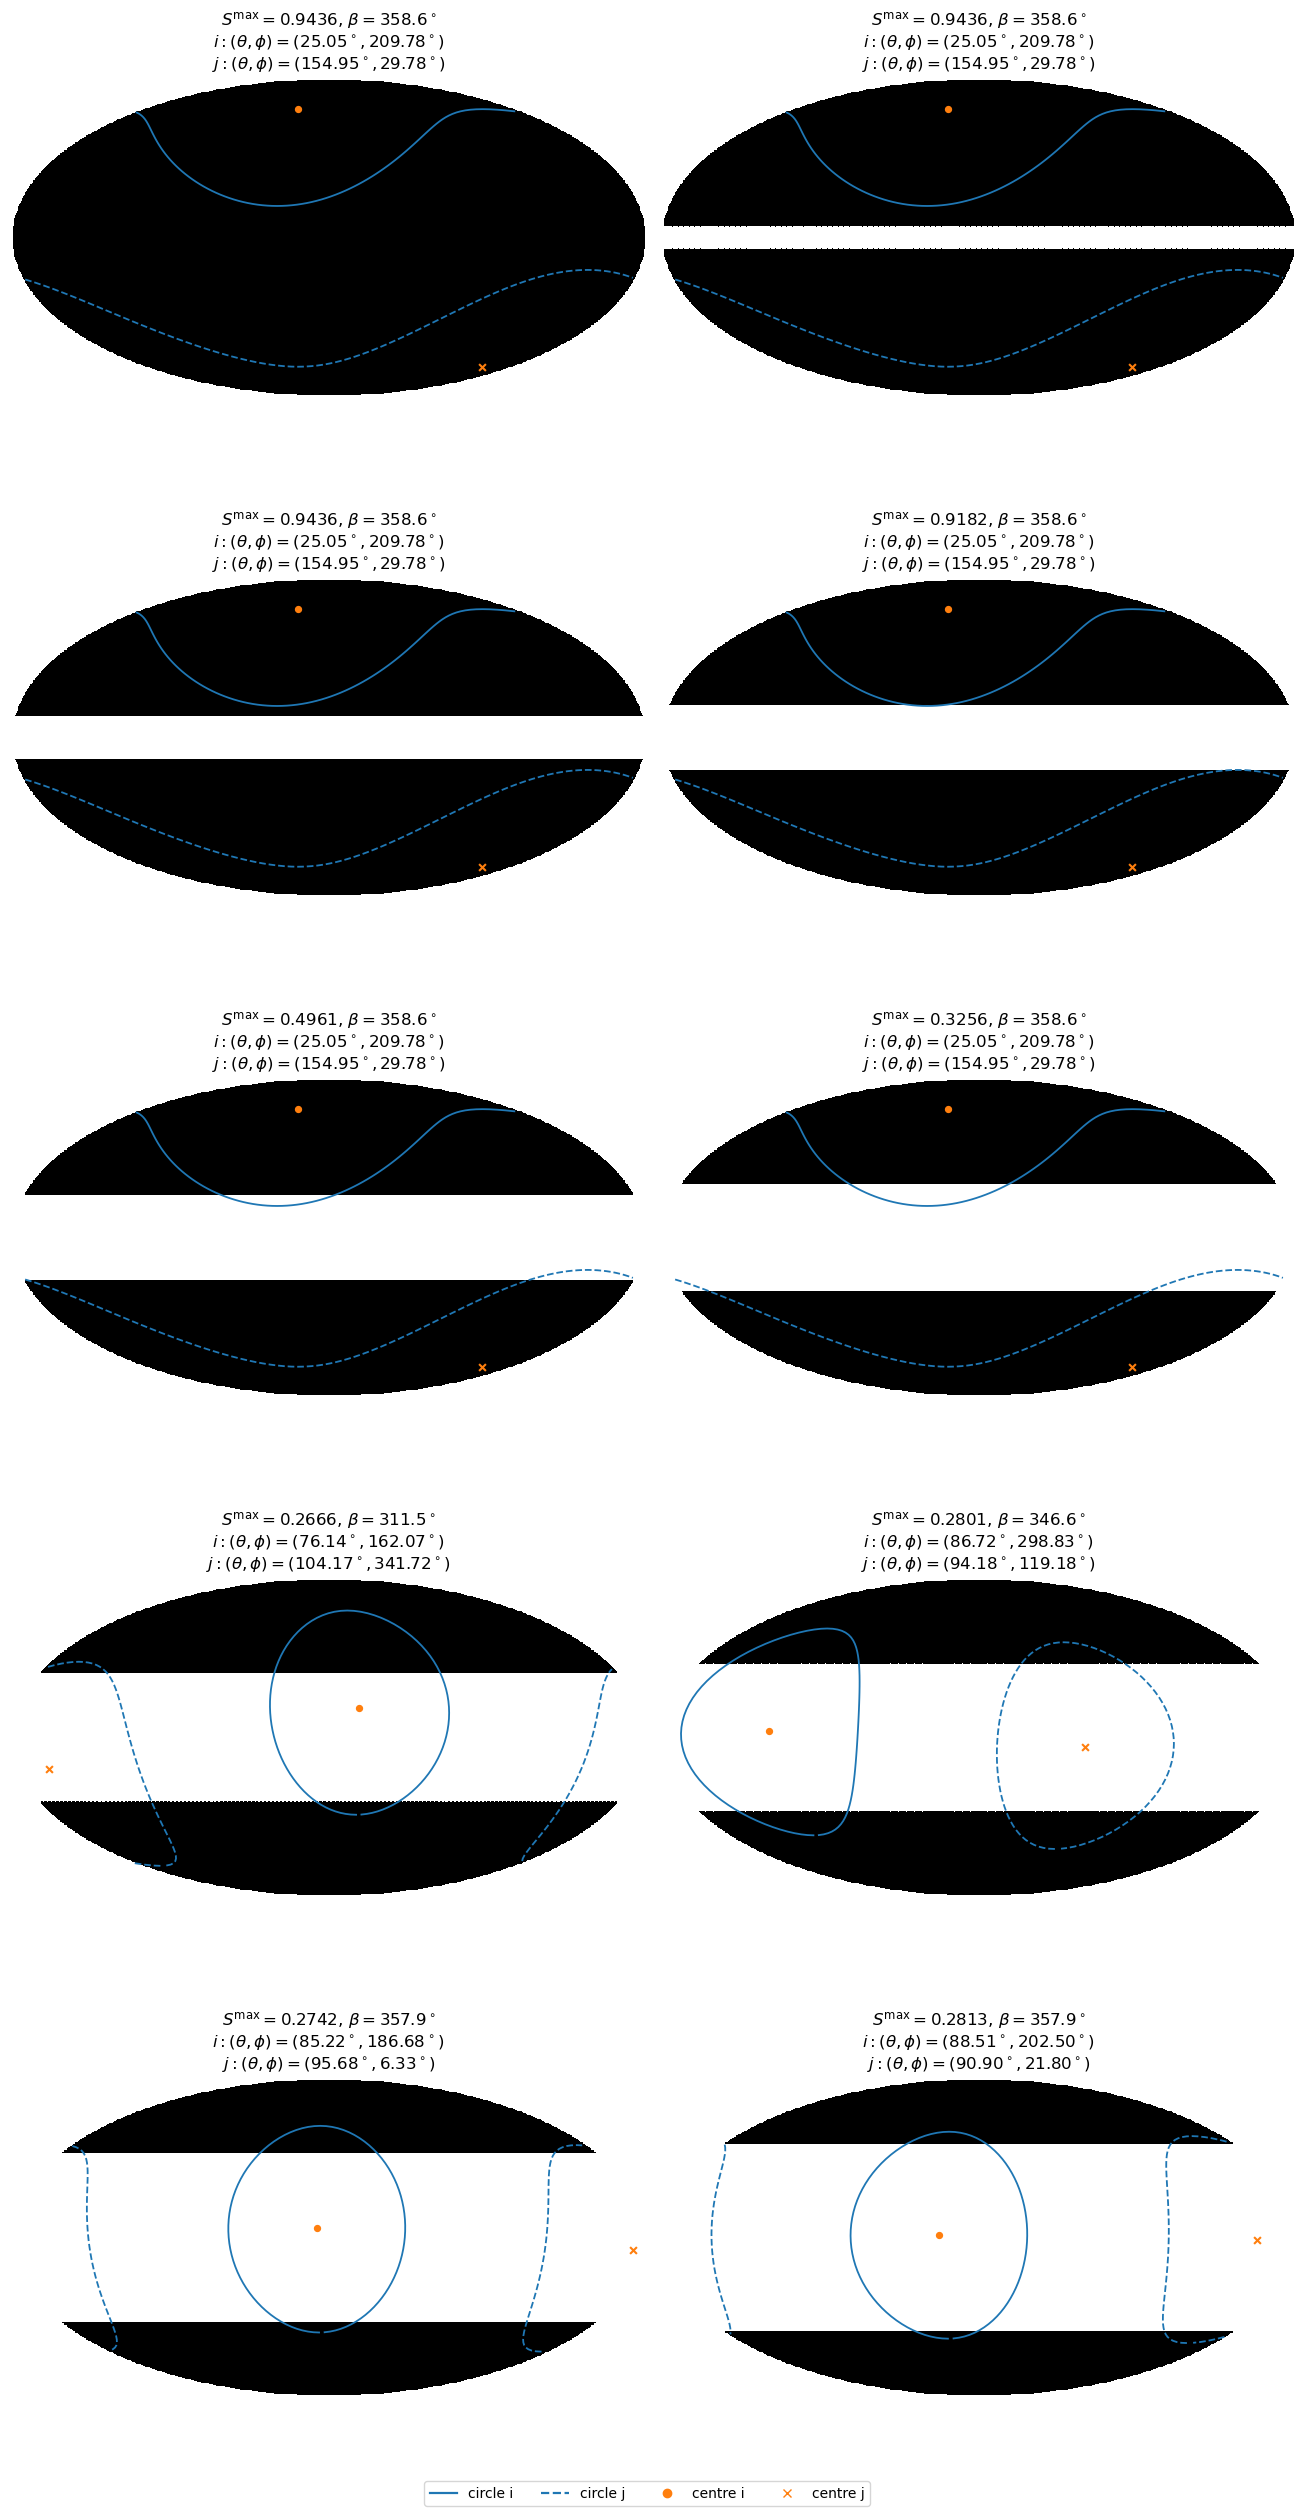

saved table: /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_14_alpha50_table.dat
saved plot : /home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations/inj_14_alpha50_pairs.png

Finished.
Original realizations processed: 1
New realizations processed: 15
Total realizations processed: 16
All tables and plots saved in:
/home/xluo/circles-in-the-sky/inj15_equator_nphi512/analysis_all_realizations


In [ ]:
# ==================================================
# Paths
# ==================================================
root = Path("/home/xluo/circles-in-the-sky")

# --------------------------------------------------
# Original inj09 result
# --------------------------------------------------
old_results_dir = root / "eqbF" / "results"

old_topo_result_file = (
    root
    / "inj09_full_correct"
    / "results"
    / "inj09_full.dat"
)

old_mask_dir = (
    root
    / "injected_position_scan_nside512_lmax800"
    / "inj_09_symmetric_equatorial_masks"
)

old_fraction_file = (
    old_mask_dir
    / "equatorial_mask_pair_fractions.dat"
)


# --------------------------------------------------
# New 15-realisation job 904140
# --------------------------------------------------
new_job_dir = (
    root
    / "inj15_equator_nphi512"
)

# Search recursively because each realisation may
# have its own results subdirectory
new_results_dir = (
    new_job_dir
    / "results"
)

new_mask_base = (
    root
    / "injected_position_scan_nside512_lmax800"
    / "all30_symmetric_equatorial_masks"
)

new_mask_dir = new_mask_base / "masks"

new_fraction_file = (
    new_mask_base
    / "equatorial_mask_pair_fractions_all30.dat"
)


# --------------------------------------------------
# Save every table and figure here
# --------------------------------------------------
output_dir = (
    new_job_dir
    / "analysis_all_realizations"
)
output_dir.mkdir(parents=True, exist_ok=True)


# ==================================================
# Settings
# ==================================================
alpha_target = 50.161562

half_widths = [
    5, 10, 15, 20, 25,
    , 35, 40, 45,
]

NPHI = 512
ORIENTABLE = True
N_CURVE = 100


# ==================================================
# Columns in beta-returning .dat files
# ==================================================
columns = [
    "alpha_deg",
    "Smax",
    "pixel_i",
    "theta_i_deg",
    "phi_i_deg",
    "pixel_j",
    "theta_j_deg",
    "phi_j_deg",
    "separation_deg",
    "beta_max_bin",
    "beta_max_deg",
]


# ==================================================
# Read original inj09 injected-pair fractions
# ==================================================
old_f_inj = pd.read_csv(
    old_fraction_file,
    comment="#",
    sep=r"\s+",
    names=[
        "half_width_deg",
        "sky_masked",
        "circle_i_masked",
        "circle_j_masked",
        "f_lost_injected_pair",
        "f_usable_injected_pair",
        "mask_file",
    ],
)

old_f_inj["half_width_deg"] = (
    old_f_inj["half_width_deg"]
    .astype(int)
)


# ==================================================
# Read new all-realisation injected-pair fractions
# ==================================================
new_f_inj = pd.read_csv(
    new_fraction_file,
    comment="#",
    sep=r"\s+",
    names=[
        "case_id",
        "theta_seed_deg",
        "phi_seed_deg",
        "pixel_i",
        "pixel_j",
        "separation_deg",
        "half_width_deg",
        "sky_masked",
        "circle_i_masked",
        "circle_j_masked",
        "f_lost_injected_pair",
        "f_usable_injected_pair",
        "input_map",
        "mask_file",
        "inpainted_map",
    ],
)

new_f_inj["case_id"] = (
    new_f_inj["case_id"]
    .astype(int)
)

new_f_inj["half_width_deg"] = (
    new_f_inj["half_width_deg"]
    .round()
    .astype(int)
)


# ==================================================
# Geometry helpers
# ==================================================
def rotation_matrix(phi, theta):
    return np.array(
        [
            [
                np.cos(theta) * np.cos(phi),
                -np.sin(phi),
                np.sin(theta) * np.cos(phi),
            ],
            [
                np.cos(theta) * np.sin(phi),
                np.cos(phi),
                np.sin(theta) * np.sin(phi),
            ],
            [
                -np.sin(theta),
                0.0,
                np.cos(theta),
            ],
        ]
    )


def circle_pixels(theta_deg, phi_deg, alpha_deg, nside):
    theta = np.deg2rad(theta_deg)
    phi = np.deg2rad(phi_deg)
    alpha = np.deg2rad(alpha_deg)

    phase = (
        2.0
        * np.pi
        * np.arange(1, NPHI + 1)
        / NPHI
    )

    local_vectors = np.column_stack(
        [
            np.sin(alpha) * np.cos(phase),
            np.sin(alpha) * np.sin(phase),
            np.full(NPHI, np.cos(alpha)),
        ]
    )

    vectors = (
        local_vectors
        @ rotation_matrix(phi, theta).T
    )

    theta_ring = np.arccos(
        np.clip(
            vectors[:, 2],
            -1.0,
            1.0,
        )
    )

    phi_ring = np.mod(
        np.arctan2(
            vectors[:, 1],
            vectors[:, 0],
        )
        + np.pi,
        2.0 * np.pi,
    )

    return hp.ang2pix(
        nside,
        theta_ring,
        phi_ring,
        nest=False,
    )


def partner_indices(beta_bin):
    index_i = np.arange(
        NPHI,
        dtype=int,
    )

    if ORIENTABLE:
        return (
            int(beta_bin)
            - index_i
        ) % NPHI

    return (
        index_i
        - int(beta_bin)
    ) % NPHI


def f_lost_for_row(row, mask_map):
    nside = hp.get_nside(mask_map)

    observed_mask = (
        mask_map >= 0.5
    )

    pix_i = circle_pixels(
        row["theta_i_deg"],
        row["phi_i_deg"],
        row["alpha_deg"],
        nside,
    )

    pix_j = circle_pixels(
        row["theta_j_deg"],
        row["phi_j_deg"],
        row["alpha_deg"],
        nside,
    )

    pix_j_matched = pix_j[
        partner_indices(
            row["beta_max_bin"]
        )
    ]

    usable = (
        observed_mask[pix_i]
        & observed_mask[pix_j_matched]
    )

    f_usable = usable.mean()
    f_lost = 1.0 - f_usable

    return f_lost, f_usable


def circle_lonlat(
    theta_deg,
    phi_deg,
    alpha_deg,
    ncurve=N_CURVE,
):
    theta = np.deg2rad(theta_deg)
    phi = np.deg2rad(phi_deg)
    alpha = np.deg2rad(alpha_deg)

    phase = np.linspace(
        0.0,
        2.0 * np.pi,
        ncurve,
        endpoint=False,
    )

    local_vectors = np.column_stack(
        [
            np.sin(alpha) * np.cos(phase),
            np.sin(alpha) * np.sin(phase),
            np.full(
                ncurve,
                np.cos(alpha),
            ),
        ]
    )

    vectors = (
        local_vectors
        @ rotation_matrix(phi, theta).T
    )

    theta_ring = np.arccos(
        np.clip(
            vectors[:, 2],
            -1.0,
            1.0,
        )
    )

    phi_ring = np.mod(
        np.arctan2(
            vectors[:, 1],
            vectors[:, 0],
        )
        + np.pi,
        2.0 * np.pi,
    )

    lon_deg = np.rad2deg(phi_ring)
    lat_deg = (
        90.0
        - np.rad2deg(theta_ring)
    )

    return lon_deg, lat_deg


# ==================================================
# Read nearest alpha row from one result file
# ==================================================
def read_target_row(result_file):
    if not result_file.is_file():
        raise FileNotFoundError(result_file)

    data = np.loadtxt(
        result_file,
        comments="#",
        ndmin=2,
    )

    df = pd.DataFrame(
        data[:, :len(columns)],
        columns=columns,
    )

    for col in [
        "pixel_i",
        "pixel_j",
        "beta_max_bin",
    ]:
        df[col] = (
            df[col]
            .round()
            .astype(int)
        )

    idx = (
        df["alpha_deg"]
        .sub(alpha_target)
        .abs()
        .idxmin()
    )

    return df.loc[idx].copy()


# ==================================================
# The 15 new realizations are r000--r014
# ==================================================
new_case_ids = list(range(15))

print(
    "New realization IDs:",
    new_case_ids,
)


# ==================================================
# Exact result filename
# ==================================================
def find_new_result_file(
    case_id,
    half_width=None,
):
    if half_width is None:
        result_file = (
            new_results_dir
            / f"r{case_id:03d}_orig_nphi512.dat"
        )
    else:
        result_file = (
            new_results_dir
            / (
                f"r{case_id:03d}"
                f"_pm{half_width:02d}"
                "_nphi512.dat"
            )
        )

    if not result_file.is_file():
        raise FileNotFoundError(
            result_file
        )

    return result_file

# ==================================================
# Analyse one realization
# ==================================================
def analyse_one_realisation(
    label,
    topo_result_file,
    result_files,
    mask_dir,
    fraction_table,
):
    rows = []

    # ----------------------------------------------
    # Full map / no mask
    # ----------------------------------------------
    row = read_target_row(
        topo_result_file
    )

    row["half_width_deg"] = 0
    row["f_lost_injected_pair"] = 0.0
    row["f_usable_injected_pair"] = 1.0
    row["f_lost_winning_pair"] = 0.0
    row["f_usable_winning_pair"] = 1.0

    rows.append(row)

    # ----------------------------------------------
    # pm05--pm50
    # ----------------------------------------------
    for half_width in half_widths:
        result_file = result_files[
            half_width
        ]

        row = read_target_row(
            result_file
        )

        row["half_width_deg"] = (
            half_width
        )

        mask_file = (
            mask_dir
            / (
                f"mask_equator_"
                f"pm{half_width:02d}deg.fits"
            )
        )

        if not mask_file.is_file():
            raise FileNotFoundError(
                mask_file
            )

        mask_map = hp.read_map(
            mask_file,
            field=0,
            nest=False,
            dtype=np.float64,
        )

        (
            f_lost_win,
            f_usable_win,
        ) = f_lost_for_row(
            row,
            mask_map,
        )

        inj_rows = fraction_table.loc[
            fraction_table[
                "half_width_deg"
            ]
            == half_width
        ]

        if len(inj_rows) != 1:
            raise RuntimeError(
                f"{label}: expected one "
                f"fraction row for "
                f"pm{half_width:02d}, "
                f"found {len(inj_rows)}"
            )

        inj_row = inj_rows.iloc[0]

        row[
            "f_lost_injected_pair"
        ] = inj_row[
            "f_lost_injected_pair"
        ]

        row[
            "f_usable_injected_pair"
        ] = inj_row[
            "f_usable_injected_pair"
        ]

        row[
            "f_lost_winning_pair"
        ] = f_lost_win

        row[
            "f_usable_winning_pair"
        ] = f_usable_win

        rows.append(row)

    table = (
        pd.DataFrame(rows)
        .reset_index(drop=True)
    )

    # ----------------------------------------------
    # Display table
    # ----------------------------------------------
    display_cols = [
        "half_width_deg",
        "alpha_deg",
        "Smax",
        "beta_max_bin",
        "beta_max_deg",
        "theta_i_deg",
        "phi_i_deg",
        "theta_j_deg",
        "phi_j_deg",
        "separation_deg",
        "f_lost_injected_pair",
        "f_lost_winning_pair",
    ]

    print("\n" + "=" * 80)
    print(label)
    print("=" * 80)

    display(
        table[
            display_cols
        ].style.format(
            {
                "half_width_deg": "{:.0f}",
                "alpha_deg": "{:.6f}",
                "Smax": "{:.6f}",
                "beta_max_deg": "{:.6f}",
                "theta_i_deg": "{:.6f}",
                "phi_i_deg": "{:.6f}",
                "theta_j_deg": "{:.6f}",
                "phi_j_deg": "{:.6f}",
                "separation_deg": "{:.6f}",
                "f_lost_injected_pair": "{:.6f}",
                "f_lost_winning_pair": "{:.6f}",
            }
        )
    )

    # ----------------------------------------------
    # Save table
    # ----------------------------------------------
    table_file = (
        output_dir
        / f"{label}_alpha50_table.dat"
    )

    table.to_csv(
        table_file,
        sep=" ",
        index=False,
        float_format="%.8f",
    )

    # ----------------------------------------------
    # Plot
    # ----------------------------------------------
    fig = plt.figure(
        figsize=(13, 25)
    )

    for panel, plot_row in enumerate(
        table.itertuples(index=False),
        start=1,
    ):
        half_width = int(
            plot_row.half_width_deg
        )

        if half_width == 0:
            panel_label = (
                f"{label} full"
            )

            mask_plot_map = np.zeros(
                hp.nside2npix(512)
            )

        else:
            panel_label = (
                f"pm{half_width:02d}"
            )

            mask_file = (
                mask_dir
                / (
                    f"mask_equator_"
                    f"pm{half_width:02d}deg.fits"
                )
            )

            mask_map = hp.read_map(
                mask_file,
                field=0,
                nest=False,
                dtype=np.float64,
            )

            mask_plot_map = np.where(
                mask_map >= 0.5,
                0.0,
                1.0,
            )

        hp.mollview(
            mask_plot_map,
            fig=fig.number,
            sub=(5, 2, panel),
            cmap="gray",
            min=0.0,
            max=1.0,
            cbar=False,
            notext=True,
            title=(
                rf"$S^{{\max}}="
                rf"{plot_row.Smax:.4f}$, "
                rf"$\beta="
                rf"{plot_row.beta_max_deg:.1f}^\circ$"
                "\n"
                rf"$i:(\theta,\phi)="
                rf"({plot_row.theta_i_deg:.2f}^\circ,"
                rf"{plot_row.phi_i_deg:.2f}^\circ)$"
                "\n"
                rf"$j:(\theta,\phi)="
                rf"({plot_row.theta_j_deg:.2f}^\circ,"
                rf"{plot_row.phi_j_deg:.2f}^\circ)$"
            ),
        )

        lon_i, lat_i = circle_lonlat(
            plot_row.theta_i_deg,
            plot_row.phi_i_deg,
            plot_row.alpha_deg,
        )

        lon_j, lat_j = circle_lonlat(
            plot_row.theta_j_deg,
            plot_row.phi_j_deg,
            plot_row.alpha_deg,
        )

        hp.projplot(
            lon_i,
            lat_i,
            lonlat=True,
            color="tab:blue",
            linewidth=1.3,
        )

        hp.projplot(
            lon_j,
            lat_j,
            lonlat=True,
            color="tab:blue",
            linewidth=1.3,
            linestyle="--",
        )

        phi_i_plot = (
            plot_row.phi_i_deg
            + 180.0
        ) % 360.0

        phi_j_plot = (
            plot_row.phi_j_deg
            + 180.0
        ) % 360.0

        hp.projscatter(
            phi_i_plot,
            90.0
            - plot_row.theta_i_deg,
            lonlat=True,
            color="tab:orange",
            marker="o",
            s=18,
        )

        hp.projscatter(
            phi_j_plot,
            90.0
            - plot_row.theta_j_deg,
            lonlat=True,
            color="tab:orange",
            marker="x",
            s=24,
        )

    handles = [
        plt.Line2D(
            [0],
            [0],
            color="tab:blue",
            linewidth=1.6,
            linestyle="-",
            label="circle i",
        ),
        plt.Line2D(
            [0],
            [0],
            color="tab:blue",
            linewidth=1.6,
            linestyle="--",
            label="circle j",
        ),
        plt.Line2D(
            [0],
            [0],
            color="tab:orange",
            marker="o",
            linestyle="None",
            label="centre i",
        ),
        plt.Line2D(
            [0],
            [0],
            color="tab:orange",
            marker="x",
            linestyle="None",
            label="centre j",
        ),
    ]

    fig.legend(
        handles=handles,
        loc="lower center",
        ncol=4,
        frameon=True,
        bbox_to_anchor=(
            0.5,
            -0.02,
        ),
    )

    plt.tight_layout(
        rect=(
            0,
            0.04,
            1,
            0.96,
        )
    )

    plot_file = (
        output_dir
        / f"{label}_alpha50_pairs.png"
    )

    plt.savefig(
        plot_file,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print("saved table:", table_file)
    print("saved plot :", plot_file)


# ==================================================
# First process the original inj09
# ==================================================
old_result_files = {
    half_width: (
        old_results_dir
        / f"pm{half_width:02d}.dat"
    )
    for half_width in half_widths
}

analyse_one_realisation(
    label="inj09_original",
    topo_result_file=old_topo_result_file,
    result_files=old_result_files,
    mask_dir=old_mask_dir,
    fraction_table=old_f_inj,
)


# ==================================================
# Process all 15 new realizations
# ==================================================
for case_id in new_case_ids:
    label = f"inj_{case_id:02d}"

    print("\n")
    print("#" * 80)
    print(
        f"Processing {label}"
    )
    print("#" * 80)

    topo_result_file = (
        find_new_result_file(
            case_id,
            half_width=None,
        )
    )

    result_files = {
        half_width: (
            find_new_result_file(
                case_id,
                half_width=half_width,
            )
        )
        for half_width in half_widths
    }

    fraction_table = (
        new_f_inj.loc[
            new_f_inj["case_id"]
            == case_id
        ]
        .copy()
        .reset_index(drop=True)
    )

    analyse_one_realisation(
        label=label,
        topo_result_file=topo_result_file,
        result_files=result_files,
        mask_dir=new_mask_dir,
        fraction_table=fraction_table,
    )


# ==================================================
# Finished
# ==================================================
print("\nFinished.")
print(
    "Original realizations processed: 1"
)
print(
    "New realizations processed:",
    len(new_case_ids),
)
print(
    "Total realizations processed:",
    1 + len(new_case_ids),
)
print(
    "All tables and plots saved in:"
)
print(output_dir)

In [1]:
import numpy as np

last_found = np.array([
    0.23047,
    0.59180,
    0.74219,
    0.62109,
    0.68359,
    0.64844,
    0.94141,
    1.00000,
    0.72266,
    0.85547,
    0.46875,
    0.05273,
    0.67578,
])

first_lost = np.array([
    0.41406,
    0.85547,
    0.92969,
    0.77734,
    0.80078,
    0.83203,
    1.00000,
    1.00000,
    0.94141,
    0.96484,
    0.82031,
    0.71094,
    0.83594,
])

last_sorted = np.sort(last_found)
lost_sorted = np.sort(first_lost)

median_index = len(last_found) // 2

lower_bound = last_sorted[median_index]
upper_bound = lost_sorted[median_index]

print("sorted last found:")
print(last_sorted)

print("\nsorted first lost:")
print(lost_sorted)

print("\nmedian loss-threshold interval:")
print(
    f"{lower_bound:.5f} < f_50 <= {upper_bound:.5f}"
)

sorted last found:
[0.05273 0.23047 0.46875 0.5918  0.62109 0.64844 0.67578 0.68359 0.72266
 0.74219 0.85547 0.94141 1.     ]

sorted first lost:
[0.41406 0.71094 0.77734 0.80078 0.82031 0.83203 0.83594 0.85547 0.92969
 0.94141 0.96484 1.      1.     ]

median loss-threshold interval:
0.67578 < f_50 <= 0.83594


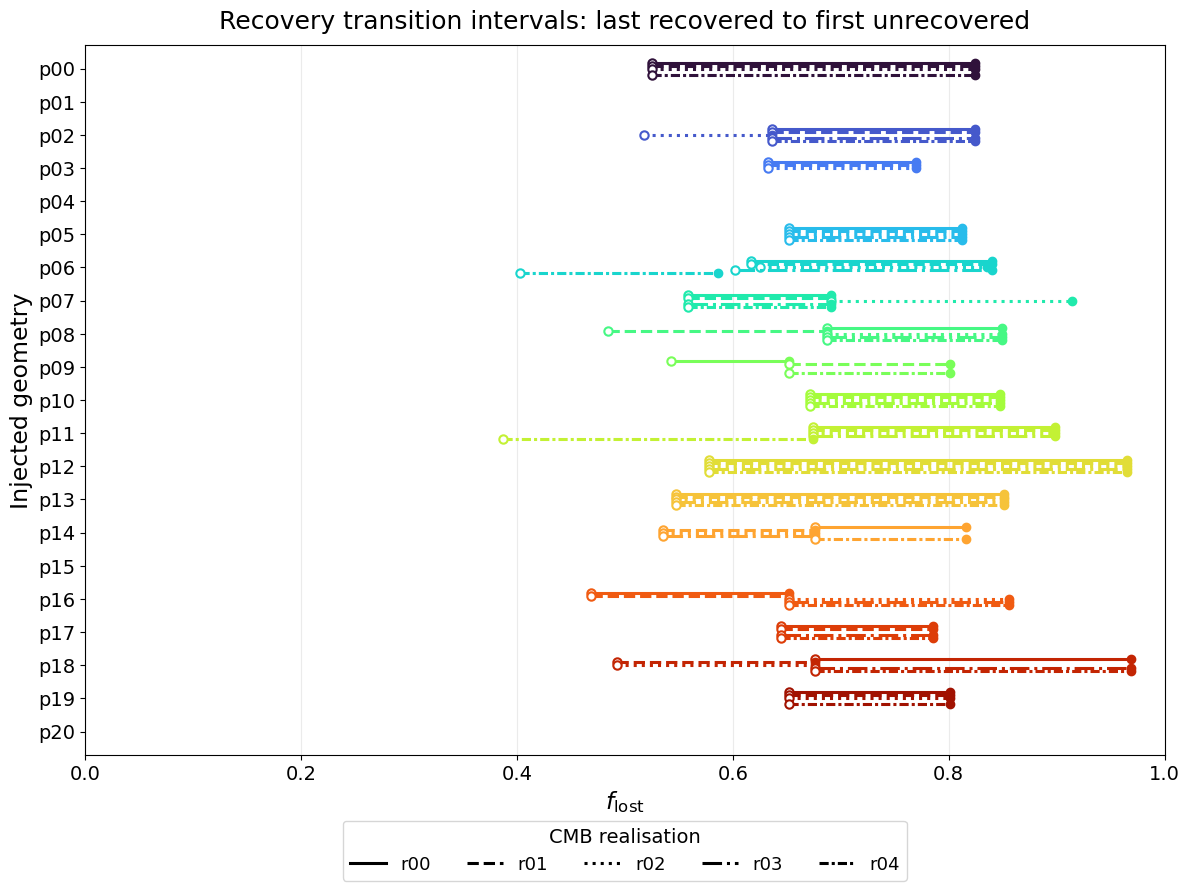

Saved: /hydrarepo/xluo/circles-in-the-sky/rand45_eq/threshold_analysis/f_lost_intervals_p06_p26_renumbered.png


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ==================================================
# Input
# ==================================================
file = Path(
    "/hydrarepo/xluo/circles-in-the-sky/"
    "rand45_eq/threshold_analysis/"
    "f_lost_intervals_reconstructed_p00_p77.dat"
)

df = pd.read_csv(
    file,
    sep=r"\s+",
)


# ==================================================
# Columns
# ==================================================
position_col = "position_id"
realisation_col = "realisation_id"

last_col = "f_last"
first_col = "f_first"


# ==================================================
# Extract original position number
# ==================================================
df["original_pos"] = (
    df[position_col]
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .astype(int)
)


# ==================================================
# Keep original p06--p26 only
# ==================================================
df = df[
    df["original_pos"].between(6, 26)
].copy()


# ==================================================
# Re-number:
# original p06 -> p00
# ...
# original p26 -> p20
# ==================================================
df["plot_pos"] = (
    df["original_pos"] - 6
)


# ==================================================
# Extract CMB realisation number
# ==================================================
df["real_num"] = (
    df[realisation_col]
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .astype(int)
)


# ==================================================
# Convert interval values to numeric
# ==================================================
df[last_col] = pd.to_numeric(
    df[last_col],
    errors="coerce",
)

df[first_col] = pd.to_numeric(
    df[first_col],
    errors="coerce",
)


# ==================================================
# Realisations
# ==================================================
realisations = sorted(
    df["real_num"].unique()
)


# ==================================================
# Line styles
# ==================================================
line_styles = [
    "-",
    "--",
    ":",
    "-.",
    (0, (3, 1, 1, 1)),
]


# ==================================================
# Vertical offsets between CMB realisations
# ==================================================
offsets = np.linspace(
    -0.18,
    0.18,
    len(realisations),
)


# ==================================================
# Position colours
# ==================================================
cmap = plt.cm.turbo

position_colors = {
    pos: cmap(pos / 20)
    for pos in range(21)
}


# ==================================================
# Figure
# ==================================================
fig, ax = plt.subplots(
    figsize=(12, 9)
)


# ==================================================
# Plot
# ==================================================
for r_index, realisation in enumerate(realisations):

    rows_r = df[
        df["real_num"] == realisation
    ]

    for _, row in rows_r.iterrows():

        pos = int(
            row["plot_pos"]
        )

        x_last = row[last_col]
        x_first = row[first_col]

        if (
            pd.isna(x_last)
            or pd.isna(x_first)
        ):
            continue

        y = (
            pos
            + offsets[r_index]
        )

        color = position_colors[pos]

        linestyle = line_styles[
            r_index % len(line_styles)
        ]


        # ------------------------------------------
        # Recovery transition interval
        # ------------------------------------------
        ax.plot(
            [x_last, x_first],
            [y, y],
            linestyle=linestyle,
            linewidth=2.2,
            color=color,
        )


        # ------------------------------------------
        # Last recovered = open circle
        # ------------------------------------------
        ax.plot(
            x_last,
            y,
            marker="o",
            markersize=6,
            markerfacecolor="white",
            markeredgecolor=color,
            markeredgewidth=1.5,
        )


        # ------------------------------------------
        # First unrecovered = filled circle
        # ------------------------------------------
        ax.plot(
            x_first,
            y,
            marker="o",
            markersize=6,
            color=color,
        )


# ==================================================
# Axes
# ==================================================
ax.set_xlim(
    0.0,
    1.0,
)

ax.set_ylim(
    20.7,
    -0.7,
)

ax.set_xticks(
    np.arange(
        0.0,
        1.01,
        0.2,
    )
)

ax.set_yticks(
    np.arange(21)
)

ax.set_yticklabels(
    [
        f"p{i:02d}"
        for i in range(21)
    ]
)


# ==================================================
# Larger text
# ==================================================
ax.set_xlabel(
    r"$f_{\mathrm{lost}}$",
    fontsize=17,
)

ax.set_ylabel(
    "Injected geometry",
    fontsize=17,
)

ax.set_title(
    "Recovery transition intervals: "
    "last recovered to first unrecovered",
    fontsize=18,
    pad=12,
)

ax.tick_params(
    axis="both",
    labelsize=14,
)


# ==================================================
# Grid
# ==================================================
ax.grid(
    axis="x",
    alpha=0.25,
)


# ==================================================
# Legend
# ==================================================
legend_handles = []

for i, realisation in enumerate(realisations):

    legend_handles.append(
        Line2D(
            [0],
            [0],
            color="black",
            linewidth=2.2,
            linestyle=line_styles[
                i % len(line_styles)
            ],
            label=f"r{realisation:02d}",
        )
    )


ax.legend(
    handles=legend_handles,
    title="CMB realisation",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=len(realisations),
    fontsize=13,
    title_fontsize=14,
)


# ==================================================
# Save
# ==================================================
plt.tight_layout()

output = (
    file.parent
    / "f_lost_intervals_p06_p26_renumbered.png"
)

plt.savefig(
    output,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(f"Saved: {output}")

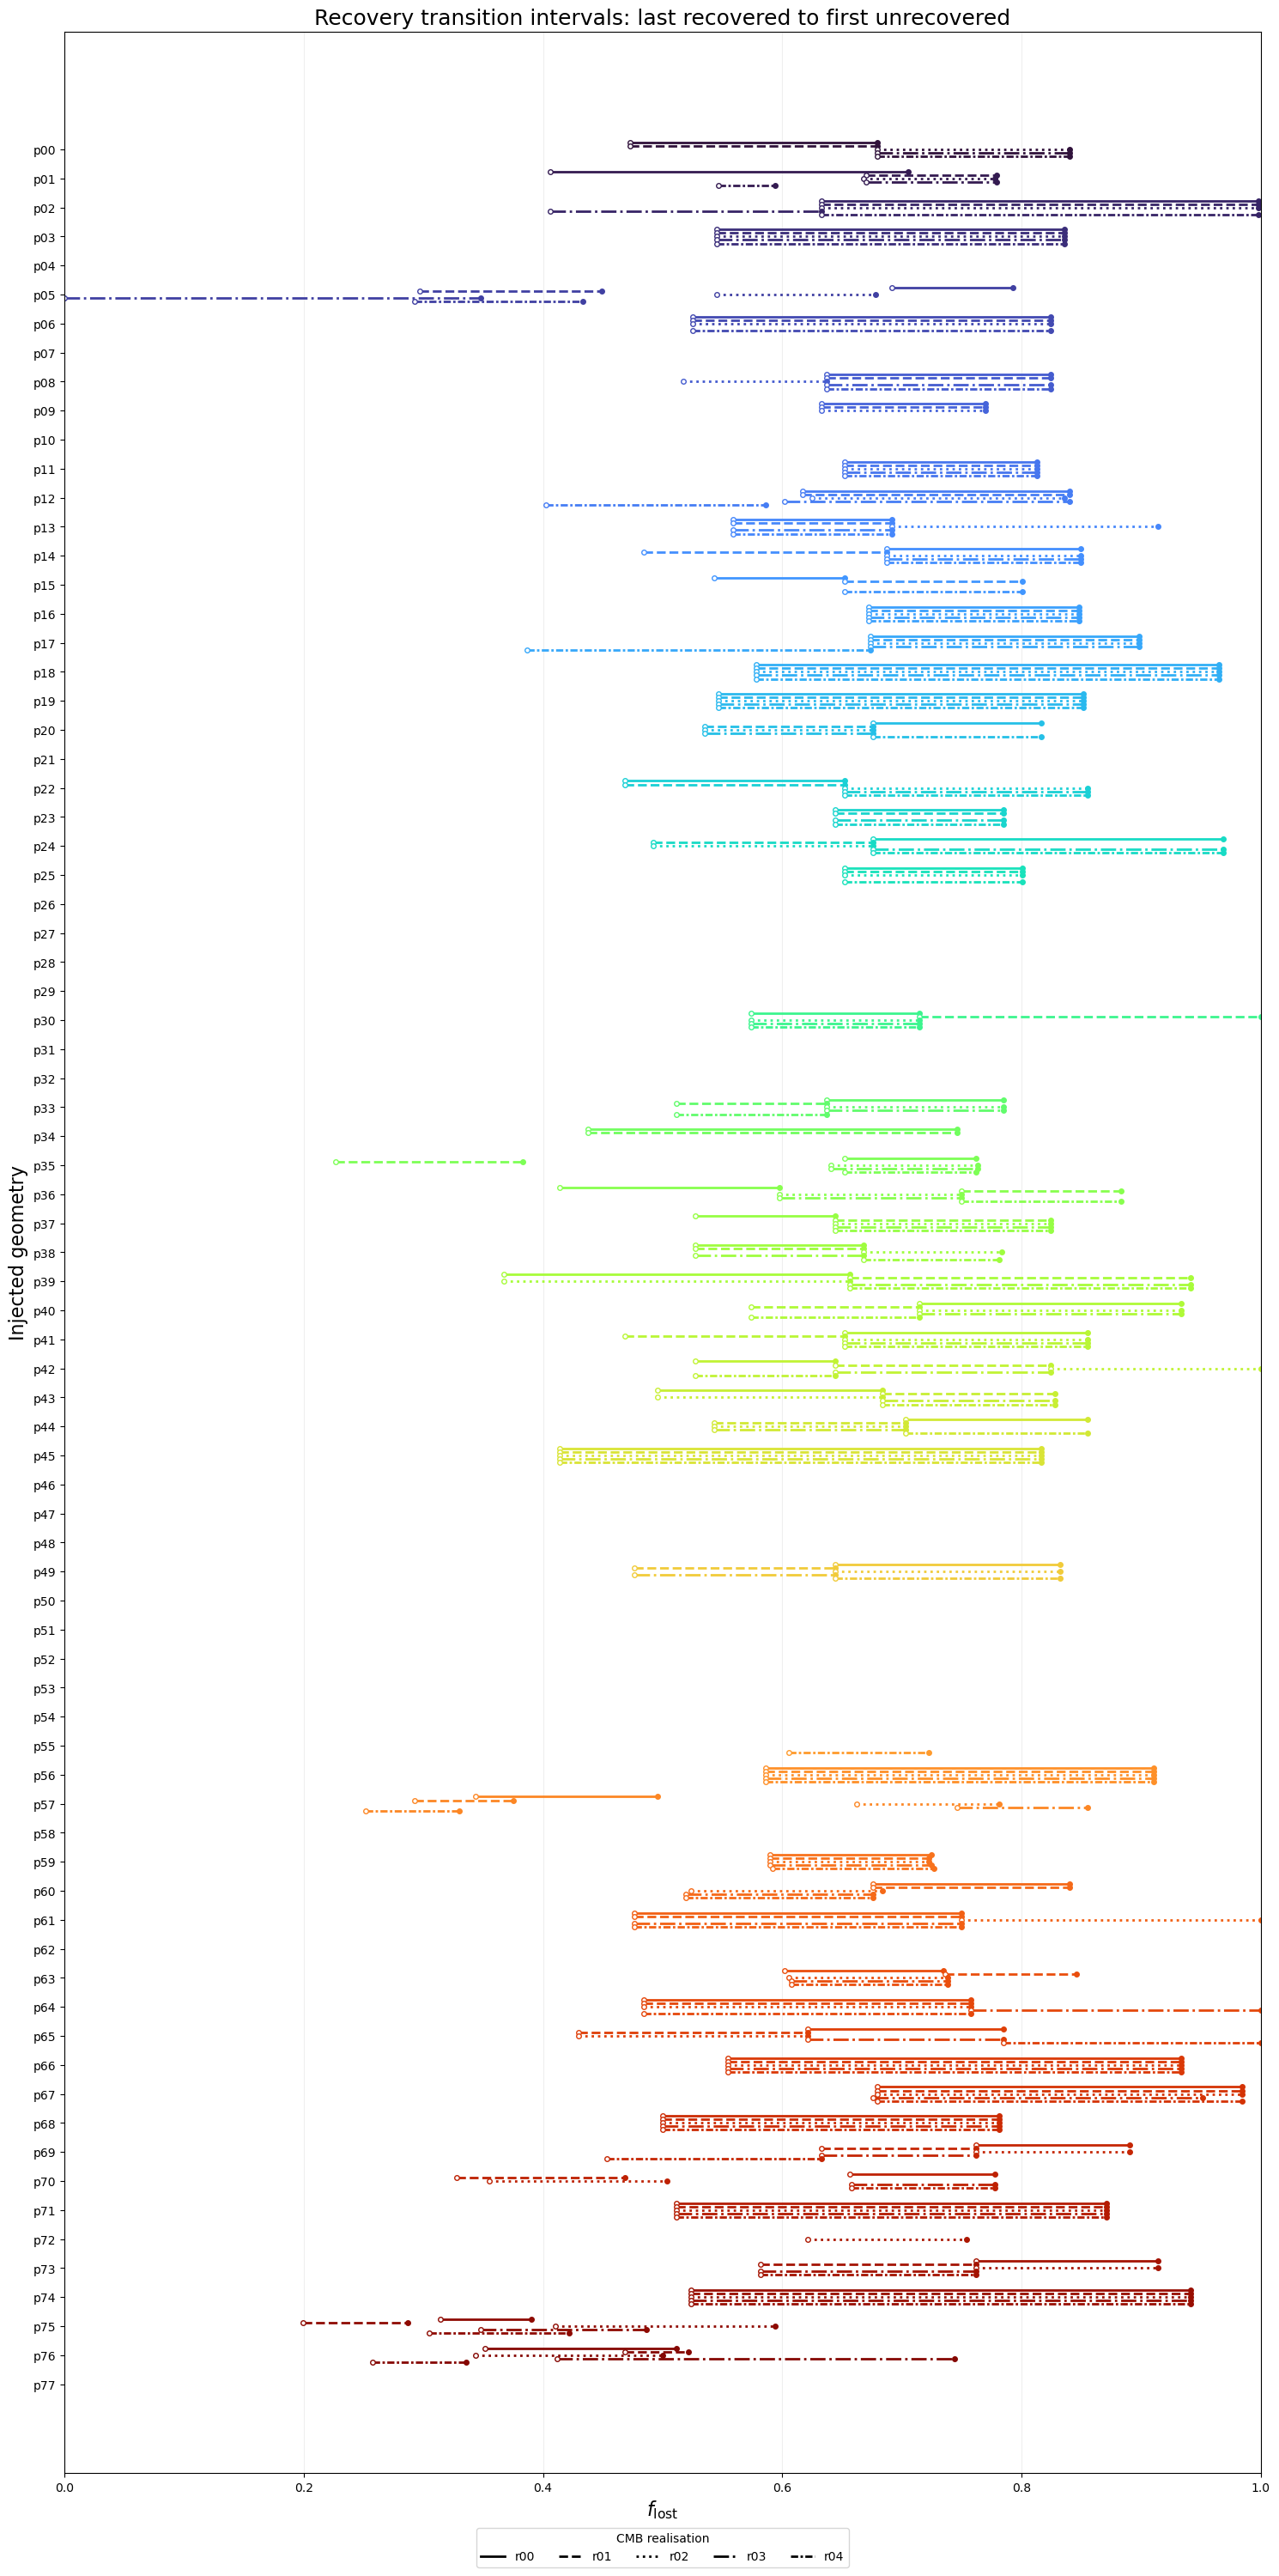

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ==================================================
# Load saved recovery-status table
# ==================================================

file = Path(
    "/hydrarepo/xluo/circles-in-the-sky"
    "/rand45_eq/threshold_analysis"
    "/mask_recovery_status_reconstructed_p00_p77.dat"
)

df = pd.read_csv(
    file,
    sep=r"\s+",
)


# ==================================================
# Find transition interval for every p00-p77,
# separately for every CMB realisation r00-r04
# ==================================================

rows = []

for (position_id, realisation_id), group in df.groupby(
    [
        "position_id",
        "realisation_id",
    ]
):

    group = group.sort_values(
        "f_lost"
    )

    recovered = group.loc[
        group["recovered"],
        "f_lost",
    ]

    if recovered.empty:
        continue

    last_recovered = recovered.max()

    unrecovered = group.loc[
        (~group["recovered"])
        & (group["f_lost"] > last_recovered),
        "f_lost",
    ]

    if unrecovered.empty:
        continue

    rows.append(
        {
            "position_id": position_id,
            "realisation_id": realisation_id,
            "last_recovered": last_recovered,
            "first_unrecovered": unrecovered.min(),
        }
    )


transitions = pd.DataFrame(
    rows
)


# ==================================================
# Plot all 78 injected geometries
# ==================================================

fig, ax = plt.subplots(
    figsize=(15, 30)
)

colours = plt.cm.turbo(
    np.linspace(
        0,
        1,
        78,
    )
)

linestyles = [
    "-",
    "--",
    ":",
    "-.",
    (0, (3, 1, 1, 1)),
]

# Small vertical offset for the 5 CMB realisations.
offsets = np.array(
    [
        -0.24,
        -0.12,
         0.00,
         0.12,
         0.24,
    ]
)


for position_id in range(78):

    subset = transitions[
        transitions["position_id"]
        == position_id
    ]

    for row in subset.itertuples():

        r = int(
            row.realisation_id
        )

        y = (
            position_id
            + offsets[r]
        )

        # Transition interval
        ax.plot(
            [
                row.last_recovered,
                row.first_unrecovered,
            ],
            [
                y,
                y,
            ],
            color=colours[position_id],
            linestyle=linestyles[r],
            linewidth=2,
        )

        # Last recovered: open marker
        ax.plot(
            row.last_recovered,
            y,
            marker="o",
            markersize=4,
            markerfacecolor="white",
            markeredgecolor=colours[position_id],
        )

        # First unrecovered: filled marker
        ax.plot(
            row.first_unrecovered,
            y,
            marker="o",
            markersize=4,
            color=colours[position_id],
        )


# ==================================================
# CMB realisation legend
# ==================================================

for r in range(5):

    ax.plot(
        [],
        [],
        color="black",
        linestyle=linestyles[r],
        linewidth=2,
        label=f"r{r:02d}",
    )


# ==================================================
# Formatting
# ==================================================

ax.set_yticks(
    range(78)
)

ax.set_yticklabels(
    [
        f"p{i:02d}"
        for i in range(78)
    ]
)

ax.invert_yaxis()

ax.set_xlim(
    0,
    1,
)

ax.set_xlabel(
    r"$f_{\rm lost}$",
    fontsize=16,
)

ax.set_ylabel(
    "Injected geometry",
    fontsize=16,
)

ax.set_title(
    "Recovery transition intervals: "
    "last recovered to first unrecovered",
    fontsize=18,
)

ax.grid(
    axis="x",
    alpha=0.2,
)

ax.legend(
    title="CMB realisation",
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.02),
)

plt.tight_layout()
plt.show()